# Group 7 — Clean, Join, Explore, and Stakeholder Rounds
**Urban Transit Dynamics and Extreme Weather · NYC and Chicago, 2017–2025**

This notebook covers **Step 0** (cleaning, cleaning log, spot-checks, briefing pack) and the analysis behind **Step 2** (Round 2 follow-up requests and Round 3 challenges). The stakeholder conversations themselves are in the separate LLM transcripts.

**Sources**

| Source | What | Dataset |
|---|---|---|
| A | MTA Subway Hourly Ridership (NYC), by station complex | NY Open Data `t69i-h2me` (2017–19), `wujg-7c2s` (2020–24), `5wq4-mkjj` (2025+) |
| B | CTA Daily Boarding Totals (bus + rail, systemwide) | Chicago Data Portal `6iiy-9s97` |
| B | CTA 'L' Station Entries, Daily Totals | Chicago Data Portal `5neh-572f` (+ `8pix-ypme` station locations, `igwz-8jzy` community areas) |
| C | NOAA GHCN-Daily weather | NCEI Data Service API, 5 stations |

**How it's organized**

| Part | What it does | Assignment step |
|---|---|---|
| 1–3 | Download and clean NOAA weather, MTA subway and CTA ridership. Every decision goes to one shared cleaning log | Step 0: clean, log every decision |
| 4 | Join everything on `city` + `date` (and the nearest weather station for station-level data), with checks that every row matched | Step 0: checks |
| 5 | Spot-check 20+ random processed rows from each source against the raw data | Step 0: spot-check |
| 6 | Analysis: % change on extreme-weather weekdays vs. a normal weekday | Step 0: explore |
| 7 | Briefing pack: P1–P6 for Round 1, plus P7 from Round 2 | Step 0: briefing pack |
| 8 | Round 2: each follow-up request from Alex (decision-maker) and Shirley (end user), with its status | Step 2, Round 2 |
| 9 | Round 3: each challenge from Rebecca (skeptical expert), whether it held up, and what changed | Step 2, Round 3 |
| 10 | The complete cleaning log, all sources | Step 0: cleaning log |

**Definitions used throughout**
- **Extreme heat:** daily high at or above the hottest 5% of 2017–19 summer days (92°F NYC, 93°F Chicago). **Extreme cold:** daily low at or below the coldest 5% of 2017–19 winter days (14°F NYC, −1°F Chicago). **Snow:** 2 inches or more. **Heavy rain:** 1 inch or more.
- **Periods:** 2017–19 (before COVID) and 2022–25 (after). 2020–21 is shown in gray and left out of comparisons.
- **Normal weekday:** the median of non-extreme, non-holiday weekdays on the same weekday in the same month. **n** = number of weekdays.

**Running it:** run top to bottom. Raw downloads are cached in `data/raw/`; cleaned tables, results and the full cleaning log are written to `data/clean/`, and charts to `figures/`. `check()` stops the notebook with `CHECK FAILED` if anything is wrong, so a completed run means every check passed.

## Key cleaning decisions at a glance
The decisions that matter most, grouped by the kinds of problems we looked for. Row counts come from the cleaning log; every entry, including checks that found nothing, is in **Part 10** (log step codes in the last column).

| Problem type | What we found | Rows | What we did | Alternative rejected | Log |
|---|---|---|---|---|---|
| **Missing values** | Station-days with no ridership record inside a station's active span (MTA; CTA days with 0 entries, i.e. closures) | 6,774 MTA; 4,153 CTA | Kept as blank and flagged `missing_day`; left out of analysis | Filling with 0 (a closed or unreported station isn't zero riders) | MTA 4g; CTA C5–C6 |
| | MTA station-days with near-zero ridership (closures: weekend track work, the G line's July–Aug 2024 suspension) | 20,148 at 353 stations | Treated as closures: set to missing, like CTA's 0-entry days. Added after Round 3; system and area results moved by at most 0.2 points | Keeping them (a closed station read as a −100% "weather" drop) | MTA 4j |
| | Weather values missing at a city's main station (NYC wind speed); one station-day missing entirely | 214; 1 | Filled from the next-priority station, with the source recorded in a `*_src` column; the missing day added as an empty row so it can't vanish in joins | Averaging all stations (blurs the main record); leaving gaps | NOAA 4d, 5 |
| | Trace precipitation and summer snow left blank | 2,239 rain, 581 snow; 1,231 | Trace kept as 0 with a flag; summer blanks set to 0 only on days above 35°F | Inventing a small amount; filling every blank with 0 | NOAA 4c, 4f |
| **Duplicates** | Duplicate station-days or dates | 1 MTA; 0 NOAA, 0 CTA | Merged into one station-day (ridership summed) | Keeping both (double counts) | MTA 4f; NOAA 4a; CTA C3 |
| **Units** | NOAA bulk files use tenths of °C and mm | 16,589 | Requested °F, inches and mph from the API; confirmed by range checks | Converting by hand (easy to be off by 10×) | NOAA 4e, 4h |
| **Timezone** | MTA has hourly local-clock timestamps; NOAA days run on local standard time all year | all MTA rows (offset applies to station-days in daylight saving) | Summed hours by local NYC date. In summer the two calendars are one hour apart (12–1 a.m. lands on different days); accepted as negligible | Converting to UTC (a 4–5 hour offset instead of 1) | NOAA 4h; MTA 4i |
| **Outliers** | Real weather extremes (≥3 in rain, ≥8 in snow, ≥100°F) | 50 | Kept, and checked against known storms (Ida 2021, Feb 2021 snowstorm) | Removing by z-score (would delete the events we study) | NOAA 4h |
| | Unusual system days and station spikes (holidays, storms, game days) | 55 MTA days; 67 CTA bus and 84 CTA rail days; 113 station-days | Never dropped. Every unusual system day was explained: mostly holidays and holiday weeks, plus snow, cold and rain days, the March 2020 shutdown, and Chicago days at known events (St. Patrick's parade weekends, Pride and the 2017 Women's March on the high side; CTA service suspensions during the May–June 2020 unrest on the low side) | Removing them (often the weather days themselves) | MTA 4h–4i; CTA C11 |
| | % changes against a broken baseline (station closures, rehab) | 26,091 station weekdays | Left out of % change | Keeping them (produced +2,000% "effects") | A1–A3 |
| **Join keys** | Station renamed between datasets (e.g. "Christopher St-Sheridan Sq" → "Christopher St-Stonewall") | 38 MTA stations | Joined on station ID, not name; latest name kept | Joining on names (one station would split in two) | MTA 4c |
| | CTA station IDs must match the stops list's ID format (e.g. `40010` vs `40010.0`) | 0 found; 2 of 146 stations missing from the stops list | Normalized IDs and checked all are 5-digit codes. The 2 unmatched are closed Loop stations (Randolph/Wabash, Madison/Wabash): kept, with no area assigned | Leaving as-is (silent non-matches) | CTA C2, C12 |
| | Ridership dates with no matching weather date | 0 of 9,849 system-days; 0 station-days | Join must match every row and keep the row count, or the notebook stops | Dropping unmatched rows silently | J1, J3 |
| **Scope** | Roosevelt Island Tram in the subway file; Staten Island Railway | 6,550; 6,543 | Tram dropped (not rail); SIR kept so Staten Island appears | Keeping the tram / dropping SIR | MTA 4b |
| **Measurement change** | CTA restated its 2025 counts | 365 days | Kept, flagged; 2025 shaded on P2 and bus vs. rail re-checked on 2022–24 | Treating 2025 like other years | CTA C10; R3b |

In [1]:
import os, time, json, re
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar
import textwrap
PRINT_WIDTH = 100   # keep printed output within a PDF page
pd.set_option("display.width", PRINT_WIDTH); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
if not hasattr(pd.DataFrame, "_to_string_original"):     # save pandas' own version once, so re-running this cell is safe
    pd.DataFrame._to_string_original = pd.DataFrame.to_string
def _to_string_wrapped(self, *args, line_width=PRINT_WIDTH, **kwargs):
    # print(df.to_string()) ignores display.width; wrap wide tables into blocks so they fit the page
    return pd.DataFrame._to_string_original(self, *args, line_width=line_width, **kwargs)
pd.DataFrame.to_string = _to_string_wrapped

def say(text):
    # print long sentences wrapped to the page width
    print(textwrap.fill(str(text), PRINT_WIDTH, subsequent_indent="    "))

CLEAN_DIR = Path("data/clean"); CLEAN_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("figures");      FIG_DIR.mkdir(parents=True, exist_ok=True)

SOURCE = "SETUP"          # which dataset the next log entries belong to
CLEANING_LOG = []
def log(step, issue, rows, action, rejected):
    entry = dict(source=SOURCE, step=step, issue=issue, rows_affected=int(rows), action=action, alternative_rejected=rejected)
    same = [i for i, e in enumerate(CLEANING_LOG) if (e["source"], e["step"], e["issue"]) == (SOURCE, step, issue)]
    if same: CLEANING_LOG[same[0]] = entry      # cell re-run: replace its entry rather than adding a duplicate
    else: CLEANING_LOG.append(entry)
    print(textwrap.fill(f"[{SOURCE} {step}] {issue}: {plural(int(rows), 'row')} -> {action}", PRINT_WIDTH, subsequent_indent="    "))

def plural(n, one, many=None):
    # "1 entry" / "2 entries": a count with the right form of the word
    return f"{n:,} {one if n == 1 else (many or one + 's')}"

def check(cond, msg):
    # Fail loudly: stop the notebook if a check fails.
    if not cond:
        raise AssertionError("CHECK FAILED: " + msg)
    print(textwrap.fill("  ✓ " + msg, PRINT_WIDTH, subsequent_indent="      "))

# Explaining unusual ridership days (used in Part 2, MTA 4h, and Part 3, CTA C11).
# Federal holidays, plus hand-annotated events that no holiday, weather or COVID rule explains.
_HOL = USFederalHolidayCalendar().holidays("2016-12-01", "2025-12-31")
KNOWN_EVENTS = {   # hand-annotated: days no holiday, weather or COVID rule explains (all in Chicago)
    "2017-01-21": "Women's March", "2018-06-24": "Pride Parade", "2019-06-30": "Pride Parade",
    **{d: "CTA service suspensions during the May-June 2020 unrest" for d in ["2020-05-31", "2020-06-01", "2020-06-02"]},
    **{d: "St. Patrick's Day parade weekend" for d in
       ["2018-03-17", "2019-03-16", "2022-03-12", "2023-03-11", "2024-03-16", "2025-03-15"]}}
WX = [("heavy_snow", "heavy snow"), ("snow_2in", "snow"), ("extreme_cold", "extreme cold"),
      ("heavy_rain", "heavy rain"), ("extreme_heat", "extreme heat")]

STATION_NOTES = {   # hand-annotated context for stations that stand out on extreme-weather days (not proven by the data)
    "448": "Citi Field / US Open: ridership follows game and event schedules",
    **{i: "Rockaway beach stop: hot days likely bring beach trips" for i in ["200", "201", "202", "203", "204"]},
    **{i: "Coney Island beach and amusement area" for i in ["57", "58"]},
    "41420": "Wrigley Field (Cubs home games)",
    "41690": "McCormick Place convention center: event-driven",
}
def station_note(ids):
    return pd.Series(ids).astype(str).map(STATION_NOTES).fillna("").values

def explain_days(dates, city):
    """Why was ridership unusual on each date? Returns (details, main reason). Uses city_day, built in Part 1."""
    w = city_day[city_day.city == city].set_index("date")
    details, main = [], []
    for d in pd.to_datetime(dates):
        why = []
        if d in _HOL: why.append("federal holiday")
        elif any(abs((d - h).days) <= 1 for h in _HOL): why.append("next to a federal holiday")
        if (d.month == 12 and d.day >= 20) or (d.month == 1 and d.day <= 2): why.append("holiday week")
        wx = [lab for f, lab in WX if bool(w.at[d, f])]
        if "heavy snow" in wx: wx.remove("snow")
        why += wx
        if pd.Timestamp("2020-03-09") <= d <= pd.Timestamp("2020-04-30"): why.append("COVID shutdown (comparison days span the collapse)")
        ev = KNOWN_EVENTS.get(f"{d:%Y-%m-%d}")
        if ev: why.append(ev)
        details.append(", ".join(why) or "unexplained")
        main.append("COVID shutdown" if any(x.startswith("COVID") for x in why) else
                    "holiday or holiday week" if any("holiday" in x for x in why) else
                    "known event" if ev else "extreme weather" if wx else "unexplained")
    return details, main


# Part 1 — NOAA GHCN-Daily weather (Source C)
Five stations: Central Park, LaGuardia and JFK for NYC; O'Hare and Midway for Chicago. The main station is used first and backups fill its gaps. Output is one row per city per day with extreme-weather flags, plus one row per station per day.

| Step | What it handles |
|---|---|
| 4a | duplicates |
| 4b | values that failed NOAA quality checks |
| 4c | trace amounts |
| 4d | missing days |
| 4e | impossible values |
| 4f | summer snow blanks |
| 4g | missing average temperature |
| 4h | decisions on record: units, timezone, real extremes |
| 5 | backup-station fills |
| 6 | flags |

In [2]:
SOURCE = "NOAA"

START, END = "2016-12-01", "2025-12-31"

# station_id: (city, name, priority)   priority 1 = primary, used first; others fill gaps
STATIONS = {
    "USW00094728": ("NYC", "Central Park", 1),
    "USW00014732": ("NYC", "LaGuardia",    2),
    "USW00094789": ("NYC", "JFK",          3),
    "USW00094846": ("CHI", "O'Hare",       1),
    "USW00014819": ("CHI", "Midway",       2),
}

CORE = ["TMAX", "TMIN", "PRCP", "SNOW", "SNWD", "AWND"]   # analysis fields
OPTIONAL = ["TAVG", "WSF2", "WT03", "WT04", "WT06", "WT08"]  # nice-to-have
DATATYPES = CORE + OPTIONAL

RAW_DIR = Path("data/raw/noaa");   RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR = Path("data/clean");    CLEAN_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("figures");         FIG_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
BASE = "https://www.ncei.noaa.gov/access/services/data/v1"

def fetch(station):
    out = RAW_DIR / f"{station}.csv"
    if out.exists() and out.stat().st_size > 0:
        return out
    params = dict(dataset="daily-summaries", stations=station, startDate=START, endDate=END,
                  dataTypes=",".join(DATATYPES), units="standard", includeAttributes="true",
                  includeStationName="true", includeStationLocation="1", format="csv")
    r = requests.get(BASE, params=params, timeout=180)
    r.raise_for_status()
    check(r.text.startswith('"STATION"') or r.text.startswith("STATION"),
          f"{station}: response looks like a CSV")
    out.write_text(r.text)
    time.sleep(1)
    return out

files = {s: fetch(s) for s in STATIONS}
files

{'USW00094728': PosixPath('data/raw/noaa/USW00094728.csv'),
 'USW00014732': PosixPath('data/raw/noaa/USW00014732.csv'),
 'USW00094789': PosixPath('data/raw/noaa/USW00094789.csv'),
 'USW00094846': PosixPath('data/raw/noaa/USW00094846.csv'),
 'USW00014819': PosixPath('data/raw/noaa/USW00014819.csv')}

In [4]:
raw = pd.concat([pd.read_csv(p, dtype=str, keep_default_na=False) for p in files.values()],
                ignore_index=True)
raw_frozen = raw.copy()             # untouched copy for the spot-check
N_RAW = len(raw)
n_days = (pd.Timestamp(END) - pd.Timestamp(START)).days + 1

print("Raw rows:", N_RAW, "| expected if no days missing:", n_days * len(STATIONS))
print(raw.groupby("STATION").size().rename("rows"))
print(); say(f"Columns: {list(raw.columns)}")
missing_types = [d for d in DATATYPES if d not in raw.columns]
print("Datatypes the API returned no column for:", missing_types)
check(set(raw["STATION"]) == set(STATIONS), "all 5 stations present in raw data")
raw.head()

Raw rows: 16589 | expected if no days missing: 16590
STATION
USW00014732    3318
USW00014819    3317
USW00094728    3318
USW00094789    3318
USW00094846    3318
Name: rows, dtype: int64

Columns: ['STATION', 'NAME', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'DATE', 'AWND',
    'AWND_ATTRIBUTES', 'PRCP', 'PRCP_ATTRIBUTES', 'SNOW', 'SNOW_ATTRIBUTES', 'SNWD',
    'SNWD_ATTRIBUTES', 'TAVG', 'TAVG_ATTRIBUTES', 'TMAX', 'TMAX_ATTRIBUTES', 'TMIN',
    'TMIN_ATTRIBUTES', 'WSF2', 'WSF2_ATTRIBUTES', 'WT03', 'WT03_ATTRIBUTES', 'WT04',
    'WT04_ATTRIBUTES', 'WT06', 'WT06_ATTRIBUTES', 'WT08', 'WT08_ATTRIBUTES']
Datatypes the API returned no column for: []
  ✓ all 5 stations present in raw data


,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,AWND,AWND_ATTRIBUTES,PRCP,PRCP_ATTRIBUTES,SNOW,SNOW_ATTRIBUTES,SNWD,SNWD_ATTRIBUTES,TAVG,TAVG_ATTRIBUTES,TMAX,TMAX_ATTRIBUTES,TMIN,TMIN_ATTRIBUTES,WSF2,WSF2_ATTRIBUTES,WT03,WT03_ATTRIBUTES,WT04,WT04_ATTRIBUTES,WT06,WT06_ATTRIBUTES,WT08,WT08_ATTRIBUTES
0,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,42.7,2016-12-01,7.61,",,W",0.07,",,W,2400",0.0,",,W,2400",0.0,",,W,2400",,,54,",,W",42,",,W",19.9,",,W",,,,,,,,
1,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,42.7,2016-12-02,8.72,",,W",0.00,",,W,2400",0.0,",,W,2400",0.0,",,W,2400",,,51,",,W",40,",,W",17.0,",,W",,,,,,,,
2,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,42.7,2016-12-03,8.72,",,W",0.00,"T,,W,2400",0.0,",,W,2400",0.0,",,W,2400",,,47,",,W",41,",,W",17.0,",,W",,,,,,,,
3,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,42.7,2016-12-04,4.92,",,W",0.00,",,W,2400",0.0,",,W,2400",0.0,",,W,2400",,,47,",,W",39,",,W",12.1,",,W",,,,,,,,
4,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,42.7,2016-12-05,5.59,",,W",0.19,",,W,2400",0.0,",,W,2400",0.0,",,W,2400",,,49,",,W",38,",,W",15.0,",,W",,,,,,,,


In [5]:
df = raw.copy()
df["DATE"] = pd.to_datetime(df["DATE"], format="%Y-%m-%d", errors="raise")
VALUE_COLS = [d for d in DATATYPES if d in df.columns]

for c in VALUE_COLS:
    blank = df[c].str.strip() == ""
    df[c] = pd.to_numeric(df[c].where(~blank), errors="coerce")
    a = f"{c}_ATTRIBUTES"
    if a in df.columns:
        parts = df[a].str.split(",", expand=True).reindex(columns=range(4)).fillna("")
        df[f"{c}_M"] = parts[0].str.strip()
        df[f"{c}_Q"] = parts[1].str.strip()
        df[f"{c}_S"] = parts[2].str.strip()
        df = df.drop(columns=a)

df["city"] = df["STATION"].map(lambda s: STATIONS[s][0])
df["station_name"] = df["STATION"].map(lambda s: STATIONS[s][1])
df["priority"] = df["STATION"].map(lambda s: STATIONS[s][2])
for col in ["LATITUDE", "LONGITUDE", "ELEVATION"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
check(len(df) == N_RAW, "row count unchanged after parsing")

  ✓ row count unchanged after parsing


In [6]:
# 4a. Duplicate station-days
before = len(df)
dups = df.duplicated(["STATION", "DATE"], keep="first")
log("4a", "Duplicate STATION+DATE rows", dups.sum(),
    "Kept the first row, dropped the rest", "Averaging duplicates (hides a source problem)")
df = df[~dups].copy()
check(len(df) == before - dups.sum(), "row count = before minus duplicates")
check(not df.duplicated(["STATION", "DATE"]).any(), "STATION+DATE is now unique")

[NOAA 4a] Duplicate STATION+DATE rows: 0 rows -> Kept the first row, dropped the rest
  ✓ row count = before minus duplicates
  ✓ STATION+DATE is now unique


In [7]:
# 4b. Values that failed a NOAA quality check -> set to missing
for c in VALUE_COLS:
    q = f"{c}_Q"
    if q in df.columns:
        bad = (df[q] != "") & df[c].notna()
        if bad.any():
            log("4b", f"{c} failed NOAA quality check (qflag={sorted(df.loc[bad, q].unique())})",
                bad.sum(), "Set value to NaN (backup station can fill it later)",
                "Keeping flagged values / dropping the whole day")
            df.loc[bad, c] = np.nan
check(len(df) == N_RAW - dups.sum(), "4b: row count unchanged (values edited, no rows added or dropped)")

[NOAA 4b] TMAX failed NOAA quality check (qflag=['G', 'I']): 2 rows -> Set value to NaN (backup
    station can fill it later)
[NOAA 4b] TMIN failed NOAA quality check (qflag=['I', 'S']): 2 rows -> Set value to NaN (backup
    station can fill it later)
[NOAA 4b] SNWD failed NOAA quality check (qflag=['W']): 2 rows -> Set value to NaN (backup station
    can fill it later)
  ✓ 4b: row count unchanged (values edited, no rows added or dropped)


In [8]:
# 4c. Trace amounts: NOAA stores them as 0 with mflag 'T'. Keep the 0, add a flag column.
for c in ["PRCP", "SNOW"]:
    m = f"{c}_M"
    if m in df.columns:
        df[f"{c}_trace"] = df[m] == "T"
        log("4c", f"{c} trace amounts recorded as 0", df[f"{c}_trace"].sum(),
            f"Kept 0 and added a {c}_trace flag", "Imputing a small value like 0.01 in")
check(len(df) == N_RAW - dups.sum(), "4c: row count unchanged (values edited, no rows added or dropped)")

[NOAA 4c] PRCP trace amounts recorded as 0: 2,239 rows -> Kept 0 and added a PRCP_trace flag
[NOAA 4c] SNOW trace amounts recorded as 0: 581 rows -> Kept 0 and added a SNOW_trace flag
  ✓ 4c: row count unchanged (values edited, no rows added or dropped)


In [9]:
# 4d. Make the calendar complete: every station gets a row for every day
full_idx = pd.MultiIndex.from_product([list(STATIONS), pd.date_range(START, END, freq="D")],
                                      names=["STATION", "DATE"])
df = df.set_index(["STATION", "DATE"])
missing_days = full_idx.difference(df.index)
log("4d", "Station-days entirely missing from NOAA", len(missing_days),
    "Added empty rows (row_in_raw=False); backup station fills them at the city level",
    "Leaving gaps (they silently disappear in joins)")
df = df.reindex(full_idx)
df["row_in_raw"] = df["NAME"].notna() if "NAME" in df.columns else True
df = df.reset_index()
df["city"] = df["STATION"].map(lambda s: STATIONS[s][0])
df["station_name"] = df["STATION"].map(lambda s: STATIONS[s][1])
df["priority"] = df["STATION"].map(lambda s: STATIONS[s][2])
check(len(df) == n_days * len(STATIONS), "exactly one row per station per day")

[NOAA 4d] Station-days entirely missing from NOAA: 1 row -> Added empty rows (row_in_raw=False);
    backup station fills them at the city level
  ✓ exactly one row per station per day


In [10]:
# 4e. Plausibility ranges (°F, inches, mph). Only physically impossible values are removed;
#     real extremes are the point of this project, so they stay.
RANGES = {"TMAX": (-30, 115), "TMIN": (-40, 100), "PRCP": (0, 15),
          "SNOW": (0, 40), "SNWD": (0, 60), "AWND": (0, 80)}
for c, (lo, hi) in RANGES.items():
    if c in df.columns:
        bad = df[c].notna() & ~df[c].between(lo, hi)
        log("4e", f"{c} outside plausible range [{lo}, {hi}]", bad.sum(),
            "Set to NaN", "Winsorizing / capping (would invent values)")
        df.loc[bad, c] = np.nan

check(len(df) == n_days * len(STATIONS), "4e: row count unchanged")
swap = df["TMAX"].notna() & df["TMIN"].notna() & (df["TMIN"] > df["TMAX"])
log("4e", "TMIN greater than TMAX on the same day", swap.sum(),
    "Set both to NaN", "Swapping them (we can't know which value is wrong)")
df.loc[swap, ["TMAX", "TMIN"]] = np.nan

# Show the most extreme days so a human can verify them against news/NWS records.
# Example: 2021-09-01 (remnants of Hurricane Ida) should show up as a top NYC rain day.
for c in ["PRCP", "SNOW", "TMAX"]:
    print(f"\nTop 5 {c} days by station:")
    print(df.nlargest(5, c)[["DATE", "station_name", c]].to_string(index=False))

[NOAA 4e] TMAX outside plausible range [-30, 115]: 0 rows -> Set to NaN
[NOAA 4e] TMIN outside plausible range [-40, 100]: 0 rows -> Set to NaN
[NOAA 4e] PRCP outside plausible range [0, 15]: 0 rows -> Set to NaN
[NOAA 4e] SNOW outside plausible range [0, 40]: 0 rows -> Set to NaN
[NOAA 4e] SNWD outside plausible range [0, 60]: 0 rows -> Set to NaN
[NOAA 4e] AWND outside plausible range [0, 80]: 0 rows -> Set to NaN
  ✓ 4e: row count unchanged
[NOAA 4e] TMIN greater than TMAX on the same day: 0 rows -> Set both to NaN

Top 5 PRCP days by station:
      DATE station_name  PRCP
2023-09-29          JFK  8.05
2021-09-01 Central Park  7.13
2021-09-01    LaGuardia  6.80
2023-09-29 Central Park  5.48
2017-10-14       Midway  5.20

Top 5 SNOW days by station:
      DATE station_name  SNOW
2021-02-01 Central Park  14.8
2021-02-01          JFK  11.9
2021-02-01    LaGuardia  11.7
2017-02-09    LaGuardia  10.0
2018-01-04 Central Park   9.8

Top 5 TMAX days by station:
      DATE station_name  TMAX

In [11]:
# 4f. Snowfall left blank in warm months. Many stations stop reporting SNOW in summer.
warm = df["DATE"].dt.month.isin([5, 6, 7, 8, 9])
for c in ["SNOW", "SNWD"]:
    fill = warm & df[c].isna() & df["row_in_raw"] & (df["TMIN"] > 35)
    log("4f", f"{c} blank in May–Sep on days with TMIN > 35°F", fill.sum(),
        "Filled with 0", "Filling every blank SNOW with 0 (would hide real winter gaps)")
    df.loc[fill, c] = 0
check(len(df) == n_days * len(STATIONS), "4f: row count unchanged (values edited, no rows added or dropped)")

[NOAA 4f] SNOW blank in May–Sep on days with TMIN > 35°F: 1,231 rows -> Filled with 0
[NOAA 4f] SNWD blank in May–Sep on days with TMIN > 35°F: 1,231 rows -> Filled with 0
  ✓ 4f: row count unchanged (values edited, no rows added or dropped)


In [12]:
# 4g. Daily average temperature (TAVG): the API returns the column, but with no values for these stations and years
if "TAVG" in df.columns:
    print("Non-blank raw TAVG values by station:", df.groupby("station_name")["TAVG"].count().to_dict())
    log("4g", f"Daily average temperature (TAVG) is blank in {df['TAVG'].isna().sum():,} of {len(df):,} station-days "
        "(NOAA returned no TAVG for these 5 stations in 2016-2025)", df["TAVG"].isna().sum(),
        "Built TAVG_calc = (TMAX + TMIN) / 2, the standard daily midrange, for reference only: no hazard flag uses it "
        "(heat uses the daily high, cold the daily low)",
        "Leaving no average at all; or mixing any raw TAVG (an hourly mean) with the midrange in one column")
df["TAVG_calc"] = (df["TMAX"] + df["TMIN"]) / 2

# Weather-type columns (WT**) are '1' when observed and blank otherwise: blank != 'did not happen'
for c in [w for w in ["WT03", "WT04", "WT06", "WT08"] if w in df.columns]:
    df[c] = df[c].fillna(0).astype(int)
station_day = df.copy()
check(len(df) == n_days * len(STATIONS), "4g: row count unchanged (values edited, no rows added or dropped)")

# 4h. Decisions that change no values but must be on record
log("4h", "Units: NOAA bulk files use tenths of °C and tenths of mm", N_RAW,
    "Requested units=standard from the API (°F, inches, mph); verified by the range checks in 4e",
    "Downloading metric bulk files and converting by hand (easy to get a factor of 10 wrong)")
log("4h", "Timezone: NOAA's daily values for these airport/park stations run midnight to midnight local STANDARD time "
    "all year, while MTA timestamps are local clock time (daylight saving in summer)", 0,
    "Kept NOAA dates as local calendar dates and summed MTA hours by local date (MTA 4i). During daylight saving the two "
    "days are offset by one hour: 12-1 a.m. ridership falls on the next MTA date but the earlier NOAA day. Accepted as "
    "negligible (one of the quietest hours, and weather flags are daily totals)",
    "Converting to UTC (would move evening trips onto the next day, a 4-5 hour offset instead of 1)")
real_extremes = int((df["PRCP"] >= 3).sum() + (df["SNOW"] >= 8).sum() + (df["TMAX"] >= 100).sum())
log("4h", "Extreme but physically possible values (PRCP >= 3 in, SNOW >= 8 in, TMAX >= 100°F)", real_extremes,
    "Kept; top values checked against known storms (Ida 2021-09-01, JFK flood 2023-09-29, 2021-02-01 snowstorm)",
    "Removing outliers by z-score (would delete exactly the events this project studies)")
log("4h", "Source-flag columns (*_S) and raw TAVG not needed for analysis", N_RAW,
    "Left out of the saved files", "Keeping every column (clutters the table teammates join to)")
check(len(df) == n_days * len(STATIONS), "4h: row count unchanged")

Non-blank raw TAVG values by station: {'Central Park': 0, 'JFK': 0, 'LaGuardia': 0, 'Midway': 0, "O'Hare": 0}
[NOAA 4g] Daily average temperature (TAVG) is blank in 16,590 of 16,590 station-days (NOAA returned
    no TAVG for these 5 stations in 2016-2025): 16,590 rows -> Built TAVG_calc = (TMAX + TMIN) / 2,
    the standard daily midrange, for reference only: no hazard flag uses it (heat uses the daily
    high, cold the daily low)
  ✓ 4g: row count unchanged (values edited, no rows added or dropped)
[NOAA 4h] Units: NOAA bulk files use tenths of °C and tenths of mm: 16,589 rows -> Requested
    units=standard from the API (°F, inches, mph); verified by the range checks in 4e
[NOAA 4h] Timezone: NOAA's daily values for these airport/park stations run midnight to midnight
    local STANDARD time all year, while MTA timestamps are local clock time (daylight saving in
    summer): 0 rows -> Kept NOAA dates as local calendar dates and summed MTA hours by local date
    (MTA 4i). During da

In [13]:
VARS = [v for v in ["TMAX", "TMIN", "TAVG_calc", "PRCP", "SNOW", "SNWD", "AWND"] if v in df.columns]
city_rows = []
for city, g in df.sort_values("priority").groupby("city"):
    wide = {v: g.pivot(index="DATE", columns="priority", values=v) for v in VARS}
    out = pd.DataFrame(index=wide[VARS[0]].index)
    names = g.drop_duplicates("priority").set_index("priority")["station_name"]
    for v in VARS:
        w = wide[v]
        out[v] = w.bfill(axis=1).iloc[:, 0]
        src = w.notna().idxmax(axis=1).map(names).where(w.notna().any(axis=1))
        out[f"{v}_src"] = src
        filled = (src != names[1]) & src.notna()
        log("5", f"{city} {v}: primary missing, filled from backup", filled.sum(),
            "Used next-priority station", "Averaging all stations (blurs the primary record)")
        log("5", f"{city} {v}: missing at ALL stations", out[v].isna().sum(),
            "Left NaN", "Interpolating across days (weather isn't smooth)")
    for t in ["PRCP_trace", "SNOW_trace"]:
        if t in g.columns:
            out[t] = g[g.priority == 1].set_index("DATE")[t].eq(True)          # missing -> False, without the object-dtype fillna warning
    out["city"] = city
    city_rows.append(out.reset_index())
city_day = pd.concat(city_rows, ignore_index=True).rename(columns={"DATE": "date"})
check(len(city_day) == 2 * n_days, "exactly 2 cities × every day")
check(not city_day.duplicated(["city", "date"]).any(), "city+date is unique (join key)")

[NOAA 5] CHI TMAX: primary missing, filled from backup: 0 rows -> Used next-priority station
[NOAA 5] CHI TMAX: missing at ALL stations: 0 rows -> Left NaN
[NOAA 5] CHI TMIN: primary missing, filled from backup: 0 rows -> Used next-priority station
[NOAA 5] CHI TMIN: missing at ALL stations: 0 rows -> Left NaN
[NOAA 5] CHI TAVG_calc: primary missing, filled from backup: 0 rows -> Used next-priority station
[NOAA 5] CHI TAVG_calc: missing at ALL stations: 0 rows -> Left NaN
[NOAA 5] CHI PRCP: primary missing, filled from backup: 0 rows -> Used next-priority station
[NOAA 5] CHI PRCP: missing at ALL stations: 0 rows -> Left NaN
[NOAA 5] CHI SNOW: primary missing, filled from backup: 0 rows -> Used next-priority station
[NOAA 5] CHI SNOW: missing at ALL stations: 0 rows -> Left NaN
[NOAA 5] CHI SNWD: primary missing, filled from backup: 0 rows -> Used next-priority station
[NOAA 5] CHI SNWD: missing at ALL stations: 0 rows -> Left NaN
[NOAA 5] CHI AWND: primary missing, filled from backup

In [14]:
cd = city_day
cd["year"] = cd["date"].dt.year
cd["month"] = cd["date"].dt.month
cd["dow"] = cd["date"].dt.day_name()
hol = USFederalHolidayCalendar().holidays(START, END)
cd["is_holiday"] = cd["date"].isin(hol)
cd["day_type"] = np.where(cd["is_holiday"] | (cd["date"].dt.dayofweek == 6), "U",
                  np.where(cd["date"].dt.dayofweek == 5, "A", "W"))   # matches CTA day_type codes
cd["period"] = pd.cut(cd["year"], bins=[2015, 2016, 2019, 2021, 2025],
                      labels=["buffer", "pre_covid", "covid", "post_covid"]).astype(str)

base = cd[cd["period"] == "pre_covid"]
TH = {}
for city in ["NYC", "CHI"]:
    b = base[base.city == city]
    TH[city] = dict(heat=b.loc[b.month.isin([6, 7, 8]), "TMAX"].quantile(.95),
                    cold=b.loc[b.month.isin([12, 1, 2]), "TMIN"].quantile(.05))
print("Thresholds (°F):", json.dumps({k: {kk: round(vv, 1) for kk, vv in v.items()} for k, v in TH.items()}))

cd["extreme_heat"] = cd.apply(lambda r: r.TMAX >= TH[r.city]["heat"], axis=1)
cd["extreme_cold"] = cd.apply(lambda r: r.TMIN <= TH[r.city]["cold"], axis=1)
cd["extreme_heat_abs"] = cd["TMAX"] >= 90
cd["extreme_cold_abs"] = cd["TMIN"] <= 10
cd["heavy_snow"] = cd["SNOW"] >= 4
# Added after first run: only ~12-16 days per city reach 4 in over 9 years, too few to compare periods.
# A 2-inch tier gives a larger sample; the group decides which one the analysis uses.
cd["snow_2in"] = cd["SNOW"] >= 2
log("6", "Heavy snow (>= 4 in) too rare to compare periods", int(cd["heavy_snow"].sum()),
    "Added a second tier snow_2in (>= 2 in); group to choose which one the analysis uses",
    "Lowering the heavy_snow threshold silently (would change the definition already in the Part 1 write-up)")
print("Days with SNOW >= 2 in:", cd[cd.period != "buffer"].groupby("city")["snow_2in"].sum().to_dict())
cd["heavy_rain"] = cd["PRCP"] >= 1.0
FLAGS = ["extreme_heat", "extreme_cold", "heavy_snow", "heavy_rain"]
cd["any_extreme"] = cd[FLAGS].any(axis=1)
# Comparisons need clean "normal" days; a day with no data shouldn't count as normal
cd["weather_complete"] = cd[["TMAX", "TMIN", "PRCP", "SNOW"]].notna().all(axis=1)
log("6", "Days lacking TMAX/TMIN/PRCP/SNOW after fills", (~cd["weather_complete"]).sum(),
    "Flagged weather_complete=False; exclude from 'normal day' baselines",
    "Treating missing as not-extreme")
city_day = cd
city_day.groupby(["city", "period"])[FLAGS].sum()

Thresholds (°F): {"NYC": {"heat": 92.0, "cold": 14.0}, "CHI": {"heat": 93.0, "cold": -1.0}}
[NOAA 6] Heavy snow (>= 4 in) too rare to compare periods: 30 rows -> Added a second tier snow_2in
    (>= 2 in); group to choose which one the analysis uses
Days with SNOW >= 2 in: {'CHI': 52, 'NYC': 28}
[NOAA 6] Days lacking TMAX/TMIN/PRCP/SNOW after fills: 0 rows -> Flagged weather_complete=False;
    exclude from 'normal day' baselines


extreme_heat  extreme_cold  heavy_snow  heavy_rain
city period                                                        
CHI  buffer                 0             3           2           0
     covid                 19             4           4          13
     post_covid            36            14           4          23
     pre_covid             26            16           4          34
NYC  buffer                 0             0           0           0
     covid                 19             2           4          22
     post_covid            36            15           2          43
     pre_covid             24            16          10          43

In [15]:
cd = city_day[city_day.period != "buffer"]
check(cd["date"].min() == pd.Timestamp("2017-01-01"), "analysis window starts 2017-01-01")
check(cd["date"].max() == pd.Timestamp("2025-12-31"), "analysis window ends 2025-12-31")
for city in ["NYC", "CHI"]:
    for v in ["TMAX", "TMIN", "PRCP"]:
        pct = city_day.loc[city_day.city == city, v].isna().mean() * 100
        check(pct < 2, f"{city} {v} missing {pct:.2f}% (< 2%)")
check(city_day["TMAX"].dropna().between(-30, 115).all(), "TMAX within plausible °F range")
check((city_day["TMIN"] <= city_day["TMAX"]).where(city_day[["TMIN", "TMAX"]].notna().all(axis=1), True).all(),
      "TMIN <= TMAX everywhere")
print("\nMissing % by column:")
print((city_day.isna().mean() * 100).round(2).loc[lambda s: s > 0])

  ✓ analysis window starts 2017-01-01
  ✓ analysis window ends 2025-12-31
  ✓ NYC TMAX missing 0.00% (< 2%)
  ✓ NYC TMIN missing 0.00% (< 2%)
  ✓ NYC PRCP missing 0.00% (< 2%)
  ✓ CHI TMAX missing 0.00% (< 2%)
  ✓ CHI TMIN missing 0.00% (< 2%)
  ✓ CHI PRCP missing 0.00% (< 2%)
  ✓ TMAX within plausible °F range
  ✓ TMIN <= TMAX everywhere

Missing % by column:
Series([], dtype: float64)


In [16]:
rng_sample = station_day[station_day["row_in_raw"]].sample(20, random_state=7)
rawk = raw_frozen.assign(DATE=pd.to_datetime(raw_frozen["DATE"])).set_index(["STATION", "DATE"])
rows = []
for _, r in rng_sample.iterrows():
    rr = rawk.loc[(r.STATION, r.DATE)]
    if isinstance(rr, pd.DataFrame):
        rr = rr.iloc[0]
    for v in ["TMAX", "TMIN", "PRCP", "SNOW"]:
        if v not in rawk.columns:
            continue
        raw_v = pd.to_numeric(rr[v], errors="coerce")
        new_v = r[v]
        same = (pd.isna(raw_v) and pd.isna(new_v)) or (raw_v == new_v)
        q = r.get(f"{v}_Q", "")
        reason = "" if same else ("failed quality flag" if isinstance(q, str) and q else
                                  "warm-month snow fill" if v == "SNOW" and new_v == 0 and pd.isna(raw_v) else
                                  "range/TMIN>TMAX fix" if pd.isna(new_v) else "UNEXPLAINED")
        rows.append(dict(station=r.station_name, date=r.DATE.date(), var=v,
                         raw=raw_v, clean=new_v, match=same, reason=reason))
spot = pd.DataFrame(rows)
print(f"Compared {plural(len(spot), 'value')} across 20 rows: {plural(int(spot.match.sum()), 'exact match', 'exact matches')}, "
      f"{plural(int((~spot.match).sum()), 'difference')}")
print(spot[~spot.match].to_string(index=False) if (~spot.match).any() else "No differences.")
check((spot["reason"] != "UNEXPLAINED").all(), "every difference is explained by a logged step")
spot.head(20)
noaa_spot = spot   # keep: the MTA spot-check later reuses the name 'spot'

Compared 80 values across 20 rows: 79 exact matches, 1 difference
station       date  var  raw  clean  match               reason
 Midway 2017-05-03 SNOW  NaN    0.0  False warm-month snow fill
  ✓ every difference is explained by a logged step


In [17]:
keep_station = ["STATION", "station_name", "city", "LATITUDE", "LONGITUDE", "DATE", "row_in_raw"] + \
               [c for c in ["TMAX", "TMIN", "TAVG_calc", "PRCP", "SNOW", "SNWD", "AWND", "WSF2",
                            "PRCP_trace", "SNOW_trace", "WT03", "WT04", "WT06", "WT08"] if c in station_day.columns]
station_day[keep_station].to_csv(CLEAN_DIR / "noaa_station_day.csv", index=False)
city_day.to_csv(CLEAN_DIR / "noaa_city_day.csv", index=False)
cleaning_log = pd.DataFrame(CLEANING_LOG)
cleaning_log.to_csv(CLEAN_DIR / "noaa_cleaning_log.csv", index=False)
print(len(station_day), "station-day rows |", len(city_day), "city-day rows |", len(cleaning_log), "log entries")
# The full cleaning log (all sources) is printed at the end of the notebook.

16590 station-day rows | 6636 city-day rows | 51 log entries


In [18]:
# Join-key checks on the weather side (always run)
check(set(city_day["city"]) == {"NYC", "CHI"}, "city codes are exactly 'NYC' and 'CHI' (ridership tables must use the same codes)")
check(pd.api.types.is_datetime64_any_dtype(city_day["date"]), "date column is a real datetime, not text")
check((city_day["date"].dt.normalize() == city_day["date"]).all(), "dates have no time part (safe to join on calendar date)")

  ✓ city codes are exactly 'NYC' and 'CHI' (ridership tables must use the same codes)
  ✓ date column is a real datetime, not text
  ✓ dates have no time part (safe to join on calendar date)


# Part 2 — MTA subway ridership, NYC (Source A)
MTA publishes ridership by station and hour: hundreds of millions of rows. We never download those. Instead, the NY Open Data server adds up the hourly rows into **one row per station per day**, one week at a time (`fetch_month`), and each month is saved to `data/raw/mta/daily_YYYY-MM.csv`.

**Cache first, download only what's missing.** The notebook reads the 108 cached monthly files (2017-01 to 2025-12) and makes no network calls when all are present. If a month is missing, it downloads just that month, about 35 seconds each, after checking that the dataset still has the columns we need. It then stops with `CHECK FAILED` unless all 108 months are present and non-empty, each has the expected columns, and no unexpected files are in the folder.

The 2017–2019 dataset's first day is **2017-01-13**, so NYC has no subway data for Jan 1–12, 2017 (logged as MTA 3).

In [19]:
SOURCE = "MTA"
M_START, M_END = "2017-01-01", "2025-12-31"
MTA_DATASETS = {  # label: (NY Open Data id, first date, last date)
    "2017-2019": ("t69i-h2me", "2017-01-01", "2019-12-31"),
    "2020-2024": ("wujg-7c2s", "2020-01-01", "2024-12-31"),
    "2025+":     ("5wq4-mkjj", "2025-01-01", "2025-12-31"),
}
APP_TOKEN = os.environ.get("SOCRATA_APP_TOKEN")   # optional free token: fewer rate limits
MTA_DIR = Path("data/raw/mta"); MTA_DIR.mkdir(parents=True, exist_ok=True)
BOROUGHS = ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island"]

In [20]:
# Socrata API helpers (used for both NY Open Data and the Chicago Data Portal)
def soql(dataset, params, timeout=300, domain="data.ny.gov"):
    headers = {"X-App-Token": APP_TOKEN} if APP_TOKEN else {}
    for attempt in range(6):
        try:
            r = requests.get(f"https://{domain}/resource/{dataset}.json", params=params,
                             headers=headers, timeout=timeout)
        except (requests.exceptions.ConnectionError, requests.exceptions.Timeout,
                requests.exceptions.ChunkedEncodingError) as e:
            wait = 15 * (attempt + 1)
            print(f"      connection problem ({type(e).__name__}); retrying in {wait}s", flush=True)
            time.sleep(wait); continue
        if r.status_code == 200:
            return r.json()
        if r.status_code in (429, 500, 502, 503, 504):
            wait = 15 * (attempt + 1)
            print(f"      server busy (HTTP {r.status_code}); retrying in {wait}s", flush=True)
            time.sleep(wait); continue
        raise RuntimeError(f"{dataset}: HTTP {r.status_code}: {r.text[:500]}")
    raise RuntimeError(f"{dataset}: still failing after 6 tries; re-run the cell later to continue")

def soql_all(dataset, params, page=50000, domain="data.ny.gov"):
    rows, offset = [], 0
    while True:
        batch = soql(dataset, {**params, "$limit": page, "$offset": offset}, domain=domain)
        rows += batch
        if len(batch) < page:
            return rows
        offset += page

def probe_columns(dataset):
    # Return the field names present in one sample row
    return sorted(soql(dataset, {"$limit": 1})[0].keys())

def probe_range(dataset):
    # First and last timestamp actually present in the dataset
    r = soql(dataset, {"$select": "min(transit_timestamp) AS first, max(transit_timestamp) AS last"})[0]
    return pd.Timestamp(r["first"]), pd.Timestamp(r["last"])

def fetch_month(dataset, month, has_mode, chunk_days=7):
    # One month of daily totals per station, downloaded in week-long pieces; cached as CSV
    out = MTA_DIR / f"daily_{month}.csv"
    if out.exists() and out.stat().st_size > 0:
        return out
    mode = "transit_mode, " if has_mode else ""
    month_end = (month + 1).start_time
    edges = list(pd.date_range(month.start_time, month_end - pd.Timedelta(days=1), freq=f"{chunk_days}D")) + [month_end]
    rows = []
    for a, b in zip(edges[:-1], edges[1:]):          # pieces split at midnight, so no day is cut in half
        t0 = time.time()
        part = soql_all(dataset, {
            "$select": f"date_trunc_ymd(transit_timestamp) AS day, {mode}station_complex_id, station_complex, "
                       "borough, sum(ridership) AS ridership, count(*) AS n_raw_rows",
            "$where": f"transit_timestamp >= '{a:%Y-%m-%dT00:00:00}' AND transit_timestamp < '{b:%Y-%m-%dT00:00:00}'",
            "$group": f"day, {mode}station_complex_id, station_complex, borough",
            "$order": "day, station_complex_id"})
        rows += part
        print(f"      {a:%Y-%m-%d} to {b:%Y-%m-%d}: {plural(len(part), 'row')} in {time.time() - t0:.0f}s", flush=True)
    pd.DataFrame(rows).to_csv(out, index=False)
    time.sleep(1)
    return out

def fetch_station_meta(dataset=None):
    # Station coordinates from the small official 'MTA Subway Stations' table (39hk-dx4f, ~500 rows),
    # instead of scanning the huge hourly ridership data. Same station ID: complex_id = station_complex_id.
    out = MTA_DIR / "stations_39hk-dx4f.csv"
    if not (out.exists() and out.stat().st_size > 0):
        rows = soql_all("39hk-dx4f", {"$select": "complex_id, stop_name, borough, gtfs_latitude, gtfs_longitude"})
        pd.DataFrame(rows).to_csv(out, index=False)
        print(f"      station list: {plural(len(rows), 'station')} downloaded", flush=True)
    m = pd.read_csv(out, dtype=str)
    return m.rename(columns={"complex_id": "station_complex_id", "gtfs_latitude": "latitude",
                             "gtfs_longitude": "longitude", "stop_name": "station_complex"})

def fetch_hourly_station_day(dataset, station_id, day):
    # Raw hourly rows for one station on one day (independent of the daily aggregation)
    d0 = pd.Timestamp(day); d1 = d0 + pd.Timedelta(days=1)
    rows = soql_all(dataset, {
        "$select": "transit_timestamp, ridership",
        "$where": f"station_complex_id = '{station_id}' AND transit_timestamp >= "
                  f"'{d0:%Y-%m-%dT00:00:00}' AND transit_timestamp < '{d1:%Y-%m-%dT00:00:00}'"})
    return pd.DataFrame(rows, columns=["transit_timestamp", "ridership"])

In [21]:
# Monthly station-day files: use the cache in data/raw/mta/, download only months that are missing
REQUIRED_RAW = {"transit_timestamp", "station_complex_id", "station_complex", "borough", "ridership"}   # API fields
REQUIRED_DAILY = {"day", "station_complex_id", "station_complex", "borough", "ridership", "n_raw_rows"}  # cached files
months = {m: label for label, (ds, a, b) in MTA_DATASETS.items() for m in pd.period_range(a, b, freq="M")}
path = lambda m: MTA_DIR / f"daily_{m}.csv"
missing = [m for m in months if not (path(m).exists() and path(m).stat().st_size > 0)]
HAS_MODE = {}
if missing:
    print(f"{len(missing)} of {plural(len(months), 'month')} aren't cached; downloading them (about 35 s each)")
    for label in sorted({months[m] for m in missing}):
        cols = probe_columns(MTA_DATASETS[label][0])
        check(REQUIRED_RAW <= set(cols), f"{label}: the API still has the columns we need {sorted(REQUIRED_RAW)}")
        HAS_MODE[label] = "transit_mode" in cols
    for i, m in enumerate(missing, 1):
        print(f"  {i}/{len(missing)}  {m}", flush=True)
        fetch_month(MTA_DATASETS[months[m]][0], m, HAS_MODE[months[m]])
else:
    print(f"All {len(months)} monthly files are cached; no download needed")

files = [(months[m], path(m)) for m in months]
check(all(f.exists() and f.stat().st_size > 0 for _, f in files),
      f"all {len(months)} monthly MTA files (2017-01 to 2025-12) are present and non-empty")
for label in MTA_DATASETS:
    header = set(pd.read_csv(next(f for l, f in files if l == label), nrows=0).columns)
    check(REQUIRED_DAILY <= header, f"{label}: cached files have the expected columns")
    HAS_MODE.setdefault(label, "transit_mode" in header)
extra = sorted(set(MTA_DIR.glob("daily_*.csv")) - {f for _, f in files})
check(not extra, "no unexpected monthly files in the cache" + (f" ({[f.name for f in extra]})" if extra else ""))


All 108 monthly files are cached; no download needed
  ✓ all 108 monthly MTA files (2017-01 to 2025-12) are present and non-empty
  ✓ 2017-2019: cached files have the expected columns
  ✓ 2020-2024: cached files have the expected columns
  ✓ 2025+: cached files have the expected columns
  ✓ no unexpected monthly files in the cache


In [22]:
parts = []
for label, p in files:
    try:
        d = pd.read_csv(p, dtype=str)
    except pd.errors.EmptyDataError:      # month with no data (e.g. early 2020): file is empty
        continue
    if len(d):
        d["source"] = label
        parts.append(d)
raw = pd.concat(parts, ignore_index=True)
if "transit_mode" not in raw.columns:
    raw["transit_mode"] = np.nan
raw_frozen = raw.copy()
N_RAW = len(raw)

df = raw.copy()
df["date"] = pd.to_datetime(df["day"].str[:10], format="%Y-%m-%d", errors="raise")
df["ridership"] = pd.to_numeric(df["ridership"], errors="coerce")
df["n_raw_rows"] = pd.to_numeric(df["n_raw_rows"], errors="coerce")
print("Raw daily rows:", f"{N_RAW:,}")
print(df.groupby("source").agg(rows=("date", "size"), first=("date", "min"), last=("date", "max")))

all_months = set(pd.period_range(M_START, M_END, freq="M"))
empty_months = sorted(all_months - set(df["date"].dt.to_period("M")))
covid_months = [m for m in empty_months if m.year in (2020, 2021)]
other_months = [m for m in empty_months if m.year not in (2020, 2021)]
log("3", "Months with no MTA data in COVID years 2020–21", len(covid_months),
    "Accepted: 2020–21 is excluded from comparisons anyway", "Treating as an error")
log("3", f"Months with no MTA data in 2017–19 / 2022–25: {[str(m) for m in other_months]}", len(other_months),
    "Accepted only if at the very start of the series (dataset begins later than 2017-01); recorded in datasheet",
    "Filling the gap with estimates")
first_day = df["date"].min()
gap = (first_day - pd.Timestamp(M_START)).days
log("3", f"MTA's 2017-2019 dataset starts on {first_day:%Y-%m-%d}, not {M_START} (calendar days with no NYC subway data shown)", gap,
    f"NYC series starts on {first_day:%Y-%m-%d}; January 2017 baselines use the days available",
    "Filling the gap with estimates (no other source for station-level counts)")
check(gap <= 31, f"MTA data starts within the first month of 2017 ({first_day:%Y-%m-%d})")
check(len(other_months) <= 2, f"at most 2 missing months outside 2020–21 (missing: {[str(m) for m in other_months]})")
check(len(df) == N_RAW, "row count unchanged after parsing")

Raw daily rows: 1,394,773
             rows      first       last
source                                 
2017-2019  459497 2017-01-13 2019-12-31
2020-2024  780447 2020-01-01 2024-12-31
2025+      154829 2025-01-01 2025-12-31
[MTA 3] Months with no MTA data in COVID years 2020–21: 0 rows -> Accepted: 2020–21 is excluded from
    comparisons anyway
[MTA 3] Months with no MTA data in 2017–19 / 2022–25: []: 0 rows -> Accepted only if at the very
    start of the series (dataset begins later than 2017-01); recorded in datasheet
[MTA 3] MTA's 2017-2019 dataset starts on 2017-01-13, not 2017-01-01 (calendar days with no NYC
    subway data shown): 12 rows -> NYC series starts on 2017-01-13; January 2017 baselines use the
    days available
  ✓ MTA data starts within the first month of 2017 (2017-01-13)
  ✓ at most 2 missing months outside 2020–21 (missing: [])
  ✓ row count unchanged after parsing


In [23]:
# 4a. Rows outside the dataset's own date range, and overlaps between datasets
bad_range = pd.Series(False, index=df.index)
for label, (_, a, b) in MTA_DATASETS.items():
    bad_range |= (df.source == label) & ~df.date.between(a, b)
log("4a", "Rows dated outside their dataset's declared range", bad_range.sum(),
    "Dropped", "Keeping them (would double-count overlap days)")
df = df[~bad_range].copy()
over = df.groupby(["date", "station_complex_id"])["source"].nunique()
check((over <= 1).all(), "no station-day appears in two datasets")

[MTA 4a] Rows dated outside their dataset's declared range: 0 rows -> Dropped
  ✓ no station-day appears in two datasets


In [24]:
# 4b. Transit mode: keep subway + Staten Island Railway (rail), drop Roosevelt Island Tram
before = len(df)
mode = df["transit_mode"].fillna("subway").str.strip().str.lower()
print(mode.value_counts())
tram = mode.str.contains("tram")
log("4b", "Roosevelt Island Tram rows", tram.sum(), "Dropped (aerial tram, not rail)",
    "Keeping (it isn't subway or rail service)")
log("4b", "Staten Island Railway rows", (mode.str.contains("staten") & ~tram).sum(),
    "Kept, flagged mode='sir', so Staten Island appears in the borough view",
    "Dropping SIR (would leave Staten Island out of Alex's borough breakdown)")
df["mode"] = np.where(mode.str.contains("staten"), "sir", "subway")
df = df[~tram].copy()
check(len(df) == before - tram.sum(), "row count = before minus tram rows")

transit_mode
subway                   1381680
tram                        6550
staten_island_railway       6543
Name: count, dtype: int64
[MTA 4b] Roosevelt Island Tram rows: 6,550 rows -> Dropped (aerial tram, not rail)
[MTA 4b] Staten Island Railway rows: 6,543 rows -> Kept, flagged mode='sir', so Staten Island
    appears in the borough view
  ✓ row count = before minus tram rows


In [25]:
# 4c. Station IDs and names: same station must have one ID across 2017–2025
df["station_id"] = df["station_complex_id"].astype(str).str.strip().str.upper()
ids_changed = (df["station_id"] != df["station_complex_id"]).sum()
log("4c", "Station IDs with stray spaces/lowercase", ids_changed, "Stripped and uppercased",
    "Leaving as-is (would break joins between datasets)")
names = df.groupby("station_id")["station_complex"].nunique()
renamed = names[names > 1]
ex_id = "323" if "323" in renamed.index else (renamed.index[0] if len(renamed) else None)
ex = " -> ".join(df[df.station_id == ex_id].sort_values("date")["station_complex"].unique()) if ex_id else ""
log("4c", f"Station IDs whose name differs between datasets (e.g. {ex})", len(renamed),
    "Kept the ID as the key and used the most recent name", "Joining on names (renames would split one station into two)")
if len(renamed):
    print(df[df.station_id.isin(renamed.index[:10])].groupby(["station_id", "source"])["station_complex"].first().unstack())
latest = df.sort_values("date").groupby("station_id")["station_complex"].last()
df["station_name"] = df["station_id"].map(latest)

[MTA 4c] Station IDs with stray spaces/lowercase: 0 rows -> Stripped and uppercased
[MTA 4c] Station IDs whose name differs between datasets (e.g. Christopher St-Sheridan Sq (1) ->
    Christopher St-Stonewall (1)): 38 rows -> Kept the ID as the key and used the most recent name
source                              2017-2019                          2020-2024  \
station_id                                                                         
221                    21 St-Queensbridge (F)             21 St-Queensbridge (F)   
222                      Roosevelt Island (F)               Roosevelt Island (F)   
223                  Lexington Av/63 St (F,Q)           Lexington Av/63 St (F,Q)   
224                                 57 St (F)                          57 St (F)   
273                      Queens Plaza (E,M,R)               Queens Plaza (E,M,R)   
276                          5 Av/53 St (E,M)                   5 Av/53 St (E,M)   
323            Christopher St-Sheridan Sq (1)   

In [26]:
# 4d. Borough names: standardize; fill blanks from the same station's other rows
BMAP = {"M": "Manhattan", "MANHATTAN": "Manhattan", "BK": "Brooklyn", "BROOKLYN": "Brooklyn",
        "Q": "Queens", "QUEENS": "Queens", "BX": "Bronx", "BRONX": "Bronx", "THE BRONX": "Bronx",
        "SI": "Staten Island", "STATEN ISLAND": "Staten Island"}
b = df["borough"].astype(str).str.strip().str.upper().map(BMAP)
nonstd = (df["borough"].astype(str).str.strip() != b) | df["borough"].isna()
log("4d", "Borough values not in a standard form (codes like 'BK', blanks, odd case)", nonstd.sum(),
    "Mapped codes like 'BK'/'M' to names; blanks filled from the station's most common borough",
    "Dropping rows with unknown borough")
common = b.groupby(df["station_id"]).agg(lambda s: s.mode().iat[0] if s.notna().any() else np.nan)
df["borough"] = b.fillna(df["station_id"].map(common))
check(df["borough"].isin(BOROUGHS).all(), "every row has one of the 5 boroughs")
check((df.groupby("station_id")["borough"].nunique() == 1).all(), "each station sits in exactly one borough")

[MTA 4d] Borough values not in a standard form (codes like 'BK', blanks, odd case): 0 rows -> Mapped
    codes like 'BK'/'M' to names; blanks filled from the station's most common borough
  ✓ every row has one of the 5 boroughs
  ✓ each station sits in exactly one borough


In [27]:
# 4e. Impossible ridership values
neg = df["ridership"] < 0
log("4e", "Negative daily ridership", neg.sum(), "Set to NaN", "Taking absolute value (invents data)")
df.loc[neg, "ridership"] = np.nan
miss = df["ridership"].isna()
log("4e", "Ridership missing/unparseable", miss.sum(), "Left NaN; excluded from analysis", "Filling with 0")

# 4f. One row per station per day (a station could appear twice if its name/borough text varied)
before = len(df)
df = (df.groupby(["date", "station_id"], as_index=False)
        .agg(ridership=("ridership", lambda s: s.sum(min_count=1)), n_raw_rows=("n_raw_rows", "sum"),
             station_name=("station_name", "first"), borough=("borough", "first"),
             mode=("mode", "first"), source=("source", "first")))
log("4f", "Rows merged into one station-day", before - len(df), "Summed ridership", "Keeping duplicates")
check(not df.duplicated(["date", "station_id"]).any(), "date + station_id is unique")

[MTA 4e] Negative daily ridership: 0 rows -> Set to NaN
[MTA 4e] Ridership missing/unparseable: 0 rows -> Left NaN; excluded from analysis
[MTA 4f] Rows merged into one station-day: 1 row -> Summed ridership
  ✓ date + station_id is unique


In [28]:
# 4g. Complete calendar inside each station's active span; missing days stay NaN (closures, outages)
spans = df.groupby("station_id")["date"].agg(["min", "max"])
grid = pd.concat([pd.DataFrame({"station_id": s, "date": pd.date_range(r["min"], r["max"])})
                  for s, r in spans.iterrows()], ignore_index=True)
before = len(df)
df = grid.merge(df, on=["station_id", "date"], how="left", validate="one_to_one")
for c in ["station_name", "borough", "mode"]:
    df[c] = df.groupby("station_id")[c].transform("first")
df["missing_day"] = df["ridership"].isna()
log("4g", "Station-days with no record inside the station's active span", df["missing_day"].sum(),
    "Added as NaN rows (flag missing_day); not filled with 0",
    "Filling with 0 (a closed or unreported station is not zero riders)")
check(len(df) == len(grid), "row count = full station × day grid")

df["period"] = pd.cut(df.date.dt.year, [2016, 2019, 2021, 2025],
                      labels=["pre_covid", "covid", "post_covid"]).astype(str)
per = df[~df.missing_day].groupby("station_id")["period"].agg(set)
df["in_both_periods"] = df["station_id"].map(per.apply(lambda s: {"pre_covid", "post_covid"} <= s))
log("4g", "Stations missing from either 2017–19 or 2022–25",
    (~per.apply(lambda s: {"pre_covid", "post_covid"} <= s)).sum(),
    "Flagged in_both_periods=False; excluded from pre-vs-post comparisons",
    "Including them (station openings/closures would look like weather effects)")

[MTA 4g] Station-days with no record inside the station's active span: 6,774 rows -> Added as NaN
    rows (flag missing_day); not filled with 0
  ✓ row count = full station × day grid
[MTA 4g] Stations missing from either 2017–19 or 2022–25: 0 rows -> Flagged in_both_periods=False;
    excluded from pre-vs-post comparisons


In [29]:
# 4h. System-wide data outages: days where far fewer stations reported than usual
rep = df.groupby("date").agg(stations=("missing_day", lambda s: (~s).sum()),
                             total=("ridership", "sum"))
rep["typical"] = rep["stations"].rolling(29, center=True, min_periods=7).median()
rep["partial_day"] = rep["stations"] < 0.95 * rep["typical"]
log("4h", "Days where < 95% of the usual number of stations reported", rep["partial_day"].sum(),
    "Flagged partial_day; excluded from analysis as a data gap",
    "Treating low totals on those days as a weather effect")
print(rep[rep.partial_day].head(15))
df = df.drop(columns="partial_day", errors="ignore").merge(rep[["partial_day"]], left_on="date", right_index=True, how="left")

# Unusual system totals (storms, holidays, events OR data problems): each one explained with explain_days()
# (defined in the setup cell at the top), never dropped
dow_med = rep["total"].groupby(rep.index.dayofweek).transform(
    lambda s: s.rolling(9, center=True, min_periods=3).median())
rep["ratio"] = rep["total"] / dow_med
odd = rep[(rep.ratio < 0.6) | (rep.ratio > 1.4)].copy()
odd["why"], odd["main_reason"] = explain_days(odd.index, "NYC")
outcome = odd["main_reason"].value_counts()
log("4h", "Days with system total < 60% or > 140% of nearby same-weekday days", len(odd),
    "Kept, each one explained: " + ", ".join(f"{n} {r}" for r, n in outcome.items()),
    "Removing them (they are often exactly the weather days we study)")
check((odd["main_reason"] != "unexplained").all(), "every unusual MTA day is explained by a holiday, weather, COVID or a known event")
print("Unusual MTA days that aren't holidays (holidays are the large majority):")
print(odd[odd.main_reason != "holiday or holiday week"][["total", "ratio", "why"]].round(2).to_string())

[MTA 4h] Days where < 95% of the usual number of stations reported: 0 rows -> Flagged partial_day;
    excluded from analysis as a data gap
Empty DataFrame
Columns: [stations, total, typical, partial_day]
Index: []
[MTA 4h] Days with system total < 60% or > 140% of nearby same-weekday days: 55 rows -> Kept, each
    one explained: 48 holiday or holiday week, 6 extreme weather, 1 COVID shutdown
  ✓ every unusual MTA day is explained by a holiday, weather, COVID or a known event
Unusual MTA days that aren't holidays (holidays are the large majority):
                total  ratio                                                 why
date                                                                            
2017-02-09  3044925.0   0.53                              heavy snow, heavy rain
2017-03-14  1114537.0   0.19                              heavy snow, heavy rain
2018-01-04  2820103.0   0.51                                          heavy snow
2018-03-21  3126279.0   0.55            

In [30]:
# 4j. Closure-like station-days: ridership near zero means the station was closed or bypassed, not that riders stayed home
# Applied once: re-running this cell would recompute the yearly medians without the closed days and flag more
if "closure_day" not in df.columns:
    yr_med = df.groupby(["station_id", df["date"].dt.year])["ridership"].transform("median")
    df["closure_day"] = df["ridership"].notna() & (df["ridership"] < 0.05 * yr_med)
    cl_days = df[df.closure_day]
    log("4j", "Station-days with ridership below 5% of the station's median for that year: closures such as weekend track "
        f"work and the G line's July-Aug 2024 suspension ({plural(cl_days.station_id.nunique(), 'station')})", len(cl_days),
        "Set to missing and flagged closure_day, the same treatment as CTA's 0-entry days (CTA C5); left out of analysis",
        "Keeping them (a closed station reads as a -95 to -100% 'weather' drop, and the +/-100% guard in Part 6 misses most)")
    print("Stations with the most closure days:")
    print(cl_days.groupby("station_name").agg(days=("date", "size"), first=("date", "min"), last=("date", "max"))
          .sort_values("days", ascending=False).head(8).to_string())
    df.loc[df.closure_day, "ridership"] = np.nan
    df["missing_day"] = df["missing_day"] | df["closure_day"]
else:
    print("Closure rule (4j) already applied; data unchanged")

# 4i. Station-level spikes (events, e.g. New Year's Eve at Times Sq): flagged, kept
med = df.groupby("station_id")["ridership"].transform(lambda s: s.rolling(57, center=True, min_periods=10).median())
df["station_spike"] = df["ridership"] > 5 * med
log("4i", "Station-days above 5× the station's usual level", df["station_spike"].sum(),
    "Kept, flagged station_spike", "Capping (events are real riders)")
print(df[df.station_spike].nlargest(10, "ridership")[["date", "station_name", "ridership"]])
df["valid"] = ~df["missing_day"] & ~df["partial_day"].fillna(False)
_d = pd.Series(df["date"].unique())
_dst = pd.Series([(t + pd.Timedelta(hours=12)).tz_localize("America/New_York").dst() != pd.Timedelta(0) for t in _d], index=_d)
log("4i", "Timezone: transit_timestamp is NYC local clock time, so during daylight saving an MTA day is one hour "
    "off NOAA's standard-time day (station-days in daylight saving shown)", int(df["date"].map(_dst).sum()),
    "Summed hours by local calendar date; the 12-1 a.m. hour lands one day later than in NOAA's calendar. "
    "The two switch days each year have 23 or 25 hours of ridership",
    "Converting to UTC (would move evening trips onto the next day); shifting MTA by an hour in summer (no gain for daily weather flags)")

[MTA 4j] Station-days with ridership below 5% of the station's median for that year: closures such
    as weekend track work and the G line's July-Aug 2024 suspension (353 stations): 20,148 rows ->
    Set to missing and flagged closure_day, the same treatment as CTA's 0-entry days (CTA C5); left
    out of analysis
Stations with the most closure days:
                      days      first       last
station_name                                    
Avenue X (F)           315 2017-02-04 2025-11-02
18 Av (F)              300 2017-02-04 2025-11-02
Kings Hwy (F)          299 2017-02-04 2025-11-02
Ditmas Av (F)          291 2017-02-04 2025-11-02
Avenue N (F)           277 2017-02-04 2025-11-02
Neptune Av (F)         269 2017-02-04 2025-11-01
Avenue U (F)           268 2017-02-04 2025-11-02
Woodhaven Blvd (J,Z)   256 2017-03-14 2025-11-09
[MTA 4i] Station-days above 5× the station's usual level: 81 rows -> Kept, flagged station_spike
              date            station_name  ridership
1038

In [31]:
meta = pd.concat([fetch_station_meta(ds) for ds, _, _ in MTA_DATASETS.values()], ignore_index=True)
meta["station_id"] = meta["station_complex_id"].astype(str).str.strip().str.upper()
meta["lat"] = pd.to_numeric(meta["latitude"], errors="coerce")
meta["lon"] = pd.to_numeric(meta["longitude"], errors="coerce")
coords = meta.dropna(subset=["lat", "lon"]).groupby("station_id")[["lat", "lon"]].median()

wst = pd.read_csv(CLEAN_DIR / "noaa_station_day.csv", parse_dates=["DATE"])
wcoord = (wst[wst.city == "NYC"].dropna(subset=["LATITUDE"])
          .groupby("STATION")[["LATITUDE", "LONGITUDE", "station_name"]].first())

def haversine_km(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = (np.sin((lat2 - lat1) * p / 2) ** 2 +
         np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2)
    return 12742 * np.arcsin(np.sqrt(a))

dist = pd.DataFrame({w: haversine_km(coords.lat, coords.lon, r.LATITUDE, r.LONGITUDE)
                     for w, r in wcoord.iterrows()})
coords["noaa_station"] = dist.idxmin(axis=1)
coords["noaa_km"] = dist.min(axis=1).round(1)
mta_stations = df.groupby("station_id")[["station_name", "borough", "mode"]].first().join(coords)
no_xy = mta_stations["noaa_station"].isna()
print(f"MTA station IDs matched to the station list (station_complex_id = complex_id): {(~no_xy).sum()} of {len(mta_stations)}")
check(no_xy.sum() <= max(2, round(.02 * len(mta_stations))),
      f"MTA station-list join: no more than 2% of station IDs unmatched ({no_xy.sum()} of {len(mta_stations)})")
log("5", "Stations with no coordinates", no_xy.sum(), "Assigned to Central Park",
    "Dropping them (loses riders)")
mta_stations.loc[no_xy, "noaa_station"] = "USW00094728"
far = mta_stations["noaa_km"] > 15
log("5", "Stations more than 15 km from their weather station", far.sum(),
    "Kept; flagged in noaa_km (mostly Staten Island / far Queens)", "Dropping them")
print(mta_stations.groupby(["borough", "noaa_station"]).size().unstack(fill_value=0))
print(mta_stations.groupby("borough")["noaa_km"].describe()[["mean", "max"]].round(1))
df = df.drop(columns=["noaa_station", "noaa_km"], errors="ignore").merge(mta_stations[["noaa_station", "noaa_km"]], left_on="station_id", right_index=True, how="left")

MTA station IDs matched to the station list (station_complex_id = complex_id): 426 of 426
  ✓ MTA station-list join: no more than 2% of station IDs unmatched (0 of 426)
[MTA 5] Stations with no coordinates: 0 rows -> Assigned to Central Park
[MTA 5] Stations more than 15 km from their weather station: 52 rows -> Kept; flagged in noaa_km
    (mostly Staten Island / far Queens)
noaa_station   USW00014732  USW00094728  USW00094789
borough                                             
Bronx                   64            4            0
Brooklyn                19           98           39
Manhattan                4          117            0
Queens                  35           12           32
Staten Island            0            2            0
               mean   max
borough                  
Bronx           8.1  14.0
Brooklyn       13.1  19.8
Manhattan       4.9  10.9
Queens          6.1   9.9
Staten Island  17.8  18.1


In [32]:
wc = pd.read_csv(CLEAN_DIR / "noaa_city_day.csv", parse_dates=["date"])
wc = wc[wc.city == "NYC"].copy()
if "snow_2in" not in wc.columns:
    wc["snow_2in"] = wc["SNOW"] >= 2
check(not wc.duplicated("date").any(), "NOAA NYC table has one row per date")
WCOLS = ["date", "TMAX", "TMIN", "PRCP", "SNOW", "extreme_heat", "extreme_cold", "heavy_snow", "snow_2in",
         "heavy_rain", "weather_complete", "day_type", "dow", "is_holiday"]
before = len(df)
df = df.drop(columns=[c for c in WCOLS + ["period", "heavy_rain_city", "PRCP_local", "any_extreme"] if c != "date"],
             errors="ignore").merge(wc[WCOLS + ["period"]], on="date", how="left",
                                       validate="many_to_one", indicator=True)
unmatched = (df["_merge"] != "both").sum()
log("6", "Station-days with no matching weather day", unmatched, "Must be 0", "Dropping silently")
check(unmatched == 0, "every MTA date matched a NOAA date")
check(len(df) == before, "join kept the row count (no fan-out)")
df = df.drop(columns="_merge").rename(columns={"heavy_rain": "heavy_rain_city"})

local = wst[["STATION", "DATE", "PRCP"]].rename(columns={"STATION": "noaa_station", "DATE": "date", "PRCP": "PRCP_local"})
df = df.merge(local, on=["noaa_station", "date"], how="left", validate="many_to_one")
check(len(df) == before, "local-rain join kept the row count")
fb = df["PRCP_local"].isna()
log("6", "Station-days with no rain reading at the nearest weather station", fb.sum(),
    "Used the city (Central Park) rain value", "Dropping the day")
df["PRCP_local"] = df["PRCP_local"].fillna(df["PRCP"])
df["heavy_rain"] = df["PRCP_local"] >= 1.0
changed = (df["heavy_rain"] != df["heavy_rain_city"]).sum()
log("6", "Station-days where local heavy-rain flag differs from Central Park's", changed,
    "Used the local flag", "Using Central Park for every station (misses local flooding)")
df["any_extreme"] = df[["extreme_heat", "extreme_cold", "heavy_snow", "heavy_rain"]].any(axis=1)
mta_station_day = df

  ✓ NOAA NYC table has one row per date
[MTA 6] Station-days with no matching weather day: 0 rows -> Must be 0
  ✓ every MTA date matched a NOAA date
  ✓ join kept the row count (no fan-out)
  ✓ local-rain join kept the row count
[MTA 6] Station-days with no rain reading at the nearest weather station: 0 rows -> Used the city
    (Central Park) rain value
[MTA 6] Station-days where local heavy-rain flag differs from Central Park's: 12,784 rows -> Used
    the local flag


In [33]:
# Borough-day and city-day totals from valid station-days only
v = mta_station_day[mta_station_day.valid]
FLAGS_CITY = ["extreme_heat", "extreme_cold", "heavy_snow", "snow_2in", "weather_complete",
              "day_type", "dow", "is_holiday", "period", "TMAX", "SNOW"]
mta_borough_day = (v.groupby(["borough", "date"])
                 .agg(ridership=("ridership", "sum"), stations=("station_id", "nunique"),
                      heavy_rain=("heavy_rain", lambda s: s.mean() >= 0.5),   # most of the borough's stations
                      PRCP_local=("PRCP_local", "mean"))
                 .reset_index()
                 .merge(wc[["date"] + FLAGS_CITY], on="date", how="left", validate="many_to_one"))
mta_borough_day["any_extreme"] = mta_borough_day[["extreme_heat", "extreme_cold", "heavy_snow", "heavy_rain"]].any(axis=1)
log("6", "Borough heavy-rain rule", int(mta_borough_day["heavy_rain"].sum()),
    "A borough-day counts as heavy rain if most of its stations' nearest weather station had >= 1 in",
    "Using Central Park rain for all boroughs")
city_day_mta = (v.groupby("date").agg(ridership=("ridership", "sum")).reset_index()
                  .merge(wc, on="date", how="left", validate="one_to_one"))
check(len(mta_borough_day) == v.groupby(["borough", "date"]).ngroups, "one row per borough per day")
check(not city_day_mta.duplicated("date").any(), "one row per city-day")

[MTA 6] Borough heavy-rain rule: 530 rows -> A borough-day counts as heavy rain if most of its
    stations' nearest weather station had >= 1 in
  ✓ one row per borough per day
  ✓ one row per city-day


### MTA spot-check: 20 random station-days vs. their raw hourly rows (re-downloaded and added up independently)

In [34]:
sample = mta_station_day[mta_station_day.valid].sample(20, random_state=7)
ds_for = {label: ds for label, (ds, _, _) in MTA_DATASETS.items()}
mta_spot = None
rows = []
for _, r in sample.iterrows():
    ds = ds_for[r.source]
    hourly = fetch_hourly_station_day(ds, r.station_id, r.date)
    raw_sum = pd.to_numeric(hourly["ridership"], errors="coerce").sum()
    rows.append(dict(date=r.date.date(), station=r.station_name, borough=r.borough,
                     hourly_rows=len(hourly), raw_hourly_sum=round(raw_sum, 1),
                     cleaned=round(r.ridership, 1), match=abs(raw_sum - r.ridership) <= 0.5))
    time.sleep(0.5)
spot = mta_spot = pd.DataFrame(rows)
print(f"{spot.match.sum()} of {len(spot)} station-days match the raw hourly sum")
print(spot.to_string(index=False))
check(spot.match.all(), "every sampled station-day equals the sum of its raw hourly rows")

20 of 20 station-days match the raw hourly sum
      date                                      station   borough  hourly_rows  raw_hourly_sum  \
2023-08-15                              East 105 St (L)  Brooklyn          156          1970.0   
2025-07-16                               125 St (4,5,6) Manhattan          257         18896.0   
2021-01-14                                    96 St (6) Manhattan          156          6781.0   
2024-06-06            34 St-Herald Sq (B,D,F,M,N,Q,R,W) Manhattan          207         81905.0   
2025-08-05                                 174 St (2,5)     Bronx          208          4221.0   
2018-12-19           Middle Village-Metropolitan Av (M)    Queens          127          4048.0   
2018-10-27                Van Cortlandt Park-242 St (1)     Bronx          117          4011.0   
2017-12-26                                    23 St (1) Manhattan          121          8300.0   
2017-10-06                                 116 St (2,3) Manhattan      

In [35]:
check(mta_station_day["date"].between(M_START, M_END).all(), "MTA: all dates within 2017–2025")
check(mta_station_day.loc[mta_station_day.valid, "ridership"].ge(0).all(), "MTA: no negative ridership in valid rows")
check(set(mta_borough_day["borough"]) <= set(BOROUGHS), "MTA: only the 5 boroughs appear")
for p in ["pre_covid", "post_covid"]:
    n = mta_station_day[(mta_station_day.period == p) & mta_station_day.valid]["station_id"].nunique()
    check(n > 300, f"MTA {p}: {plural(n, 'station')} with data (> 300)")
mta_station_day.to_csv(CLEAN_DIR / "mta_station_day.csv", index=False)
mta_borough_day.to_csv(CLEAN_DIR / "mta_borough_day.csv", index=False)
city_day_mta.to_csv(CLEAN_DIR / "mta_city_day.csv", index=False)
mta_stations.to_csv(CLEAN_DIR / "mta_stations.csv")
print(f"MTA saved: {len(mta_station_day):,} station-days, {len(mta_borough_day):,} borough-days")

  ✓ MTA: all dates within 2017–2025
  ✓ MTA: no negative ridership in valid rows
  ✓ MTA: only the 5 boroughs appear
  ✓ MTA pre_covid: 426 stations with data (> 300)
  ✓ MTA post_covid: 426 stations with data (> 300)
MTA saved: 1,394,996 station-days, 16,263 borough-days


# Part 3 — CTA ridership, Chicago (Source B)
Two tables from the Chicago Data Portal:
- **Daily Boarding Totals** (`6iiy-9s97`): one row per day, with systemwide `bus` and `rail_boardings`
- **'L' Station Entries** (`5neh-572f`): one row per station per day, `rides` = station entries

Rail *boardings* and station *entries* are different measures. Boardings also count cross-platform transfers, so entries should be a stable share of boardings, not equal to them. Step C9 uses this to cross-check the two tables.

Station locations come from the CTA 'L' stops list (`8pix-ypme`). They're used for two things:
- **Nearest weather station:** O'Hare or Midway.
- **Area:** each station is placed inside its official **community area** (Loop, Uptown, Hyde Park, ...) using the city's boundary file (`igwz-8jzy`). Community areas are then grouped into **North Side / Central / West Side / South Side**, following the city's usual "sides" convention. Suburban stations (Evanston, Oak Park, Rosemont, ...) lie outside the city's community areas, so they're assigned to the side they border, and this is logged.

If a download fails, the fallback is logged and the notebook keeps going.

In [36]:
SOURCE = "CTA"
CHI = "data.cityofchicago.org"
CTA_DIR = Path("data/raw/cta"); CTA_DIR.mkdir(parents=True, exist_ok=True)
CTA_SETS = {"daily": "6iiy-9s97", "stations": "5neh-572f", "stops": "8pix-ypme"}
C_START, C_END = "2017-01-01T00:00:00", "2025-12-31T23:59:59"

def cta_get(key, params, fname):
    out = CTA_DIR / fname
    if not (out.exists() and out.stat().st_size > 0):
        t0 = time.time()
        rows = soql_all(CTA_SETS[key], params, domain=CHI)
        pd.DataFrame(rows).to_csv(out, index=False)
        print(f"  downloaded {key}: {plural(len(rows), 'row')} in {time.time() - t0:.0f}s", flush=True)
    return pd.read_csv(out, dtype=str)

REQ_DAILY = {"service_date", "day_type", "bus", "rail_boardings", "total_rides"}
REQ_ST = {"station_id", "stationname", "date", "daytype", "rides"}
for key, req in [("daily", REQ_DAILY), ("stations", REQ_ST)]:
    cols = set(soql(CTA_SETS[key], {"$limit": 1}, domain=CHI)[0].keys())
    print(key, "columns:", sorted(cols))
    check(req <= cols, f"CTA {key}: has required columns {sorted(req)}")

cta_daily_raw = cta_get("daily", {"$where": f"service_date between '{C_START}' and '{C_END}'",
                                  "$order": "service_date"}, "cta_daily_2017_2025.csv")
cta_st_raw = cta_get("stations", {"$where": f"date between '{C_START}' and '{C_END}'",
                                  "$order": "date, station_id"}, "cta_station_entries_2017_2025.csv")
print(f"Raw CTA rows: daily {len(cta_daily_raw):,} | station-days {len(cta_st_raw):,}")
check(len(cta_daily_raw) > 3000, "CTA daily: at least ~3,000 days downloaded (9 years)")
check(len(cta_st_raw) > 100000, "CTA stations: at least 100,000 station-days downloaded")

daily columns: ['bus', 'day_type', 'rail_boardings', 'service_date', 'total_rides']
  ✓ CTA daily: has required columns ['bus', 'day_type', 'rail_boardings', 'service_date',
      'total_rides']
stations columns: ['date', 'daytype', 'rides', 'station_id', 'stationname']
  ✓ CTA stations: has required columns ['date', 'daytype', 'rides', 'station_id', 'stationname']
Raw CTA rows: daily 3,287 | station-days 471,505
  ✓ CTA daily: at least ~3,000 days downloaded (9 years)
  ✓ CTA stations: at least 100,000 station-days downloaded


In [37]:
# C1. Parse types (dates come as '2017-01-01T00:00:00.000'; numbers as text)
d = cta_daily_raw.copy()
d["date"] = pd.to_datetime(d["service_date"].str[:10], format="%Y-%m-%d", errors="raise")
for c in ["bus", "rail_boardings", "total_rides"]:
    d[c] = pd.to_numeric(d[c], errors="coerce")
s = cta_st_raw.copy()
s["date"] = pd.to_datetime(s["date"].str[:10], format="%Y-%m-%d", errors="raise")
s["rides"] = pd.to_numeric(s["rides"], errors="coerce")
log("C1", "Unparseable numbers (daily bus/rail + station rides)",
    d[["bus", "rail_boardings"]].isna().sum().sum() + s["rides"].isna().sum(),
    "Left NaN", "Filling with 0")
check(len(d) == len(cta_daily_raw) and len(s) == len(cta_st_raw), "CTA: row counts unchanged after parsing")

# C2. Station IDs: join key with the stops list; must be the same text form in both
raw_id = s["station_id"].astype(str).str.strip()
s["station_id"] = raw_id.str.replace(r"\.0$", "", regex=True)
log("C2", "Station IDs stored as decimals like '40010.0'", (raw_id != s["station_id"]).sum(),
    "Converted to plain text IDs like '40010'", "Leaving as-is (would not match the stops list's map_id)")
check(s["station_id"].str.fullmatch(r"\d{5}").all(), "every CTA station_id is a 5-digit code")

[CTA C1] Unparseable numbers (daily bus/rail + station rides): 0 rows -> Left NaN
  ✓ CTA: row counts unchanged after parsing
[CTA C2] Station IDs stored as decimals like '40010.0': 0 rows -> Converted to plain text IDs like
    '40010'
  ✓ every CTA station_id is a 5-digit code


In [38]:
# C3. Duplicates
dup_d = d.duplicated("date", keep="first")
log("C3", "Duplicate dates in daily totals", dup_d.sum(), "Kept first", "Summing (would double-count)")
d = d[~dup_d].copy()
key = ["station_id", "date"]
dup_s = s.duplicated(key, keep=False)
same = s[dup_s].duplicated(key + ["rides"], keep=False).sum()
log("C3", f"Station-day rows appearing more than once ({same} of them identical copies)", dup_s.sum(),
    "Kept the first row of each station-day", "Summing (identical copies would double the count)")
s = s.drop_duplicates(key, keep="first")
check(not d.duplicated("date").any() and not s.duplicated(key).any(), "CTA: date / station+date are unique")

# C4. Station names: one ID can have several names over time
nm = s.groupby("station_id")["stationname"].nunique()
log("C4", "Station IDs with more than one name", (nm > 1).sum(), "Used the ID as key and the latest name",
    "Joining on names (renamed stations would split in two)")
s["station_name"] = s["station_id"].map(s.sort_values("date").groupby("station_id")["stationname"].last())

[CTA C3] Duplicate dates in daily totals: 0 rows -> Kept first
[CTA C3] Station-day rows appearing more than once (0 of them identical copies): 0 rows -> Kept the
    first row of each station-day
  ✓ CTA: date / station+date are unique
[CTA C4] Station IDs with more than one name: 0 rows -> Used the ID as key and the latest name


In [39]:
# C5. Zero / negative counts. A station with 0 entries all day was closed; that is not 'zero riders'
z = s["rides"] <= 0
log("C5", "Station-days with 0 or negative entries (closures)", z.sum(), "Set to NaN", "Keeping 0")
s.loc[z, "rides"] = np.nan
for c in ["bus", "rail_boardings"]:
    zd = d[c] <= 0
    log("C5", f"Days with {c} <= 0", zd.sum(), "Set to NaN", "Keeping 0")
    d.loc[zd, c] = np.nan

# C6. Complete calendars
full = pd.date_range("2017-01-01", "2025-12-31")
miss = full.difference(d["date"])
log("C6", "Calendar days missing from daily totals", len(miss), "Added as NaN rows", "Leaving gaps")
check(len(miss) <= 30, f"CTA daily: at most 30 missing days ({len(miss)})")
d = d.set_index("date").reindex(full).rename_axis("date").reset_index()
spans = s.groupby("station_id")["date"].agg(["min", "max"])
grid = pd.concat([pd.DataFrame({"station_id": i, "date": pd.date_range(r["min"], r["max"])})
                  for i, r in spans.iterrows()], ignore_index=True)
s = grid.merge(s, on=key, how="left", validate="one_to_one")
s["station_name"] = s.groupby("station_id")["station_name"].transform("first")
s["missing_day"] = s["rides"].isna()
log("C6", "Station-days with no entries record inside the station's active span", s["missing_day"].sum(),
    "Kept as NaN (flag missing_day)", "Filling with 0")
check(len(s) == len(grid), "CTA: row count = full station × day grid")

[CTA C5] Station-days with 0 or negative entries (closures): 4,153 rows -> Set to NaN
[CTA C5] Days with bus <= 0: 0 rows -> Set to NaN
[CTA C5] Days with rail_boardings <= 0: 0 rows -> Set to NaN
[CTA C6] Calendar days missing from daily totals: 0 rows -> Added as NaN rows
  ✓ CTA daily: at most 30 missing days (0)
[CTA C6] Station-days with no entries record inside the station's active span: 4,153 rows -> Kept as
    NaN (flag missing_day)
  ✓ CTA: row count = full station × day grid


In [40]:
# C7. Day type: CTA's own codes vs. our shared calendar (federal holidays) used for both cities
noaa_cd = pd.read_csv(CLEAN_DIR / "noaa_city_day.csv", parse_dates=["date"])
cal = noaa_cd[noaa_cd.city == "CHI"].set_index("date")["day_type"]
d = d.rename(columns={"day_type": "cta_day_type"})       # no-op if this cell is re-run
mism = d["cta_day_type"].notna() & (d["cta_day_type"] != d["date"].map(cal))
log("C7", "Days where CTA's day type differs from our federal-holiday calendar", mism.sum(),
    "Kept CTA code as cta_day_type; analysis uses the shared calendar so NYC and Chicago are treated alike",
    "Mixing CTA's codes for Chicago with our rule for NYC")
print(d.loc[mism, ["date", "cta_day_type"]].rename(columns={"cta_day_type": "day_type"})
      .assign(ours=d.loc[mism, "date"].map(cal)).head(10))

# C8. Station-level outages: days with far fewer stations reporting than usual
rep = s.groupby("date").agg(stations_reporting=("missing_day", lambda x: (~x).sum()), entries=("rides", "sum"))
rep["typical"] = rep["stations_reporting"].rolling(29, center=True, min_periods=7).median()
rep["partial_day"] = rep["stations_reporting"] < 0.95 * rep["typical"]
log("C8", "Days where < 95% of usual 'L' stations reported", rep["partial_day"].sum(),
    "Flagged partial_day; excluded from station analysis", "Treating as a weather effect")
s = s.drop(columns="partial_day", errors="ignore").merge(rep[["partial_day"]], left_on="date", right_index=True, how="left")
s["valid"] = ~s["missing_day"] & ~s["partial_day"].fillna(False)

[CTA C7] Days where CTA's day type differs from our federal-holiday calendar: 41 rows -> Kept CTA
    code as cta_day_type; analysis uses the shared calendar so NYC and Chicago are treated alike
          date day_type ours
15  2017-01-16        W    U
50  2017-02-20        W    U
281 2017-10-09        W    U
313 2017-11-10        W    U
379 2018-01-15        W    U
414 2018-02-19        W    U
645 2018-10-08        W    U
680 2018-11-12        W    U
750 2019-01-21        W    U
778 2019-02-18        W    U
[CTA C8] Days where < 95% of usual 'L' stations reported: 2 rows -> Flagged partial_day; excluded
    from station analysis


In [41]:
# C9. Cross-check the two CTA tables: station entries should be a stable share of rail boardings
x = d.set_index("date")[["rail_boardings"]].join(rep[["entries", "partial_day"]])
x["ratio"] = x["entries"] / x["rail_boardings"]
x["ratio_typical"] = x["ratio"].rolling(57, center=True, min_periods=10).median()
x["off"] = (x["ratio"] / x["ratio_typical"] - 1).abs() > 0.15
print("Entries / boardings ratio by year (median):")
print(x.groupby(x.index.year)["ratio"].median().round(3).to_string())
log("C9", "Days where station entries / rail boardings is > 15% off its usual level", x["off"].sum(),
    "Flagged rail_check_off; listed below for review, kept", "Silently trusting either table")
print(x[x.off][["rail_boardings", "entries", "ratio", "ratio_typical"]].round(3).head(15))
d = d.drop(columns="rail_check_off", errors="ignore").merge(x[["off"]].rename(columns={"off": "rail_check_off"}), left_on="date", right_index=True, how="left")

# C10. 2025 counting change (Phase 1 limitation)
log("C10", "CTA changed how it estimates unpaid riders in 2025", int((d.date.dt.year == 2025).sum()),
    "Kept; flagged in datasheet. Each day is compared only with normal days in the same month, which limits "
    "the effect on % change but may not remove it; checked in Round 3 (see ROUND3 entry R3b)", "Dropping 2025")

# C11. Unusual system totals (storms, holidays, events or data problems): each one explained, never dropped
for c in ["bus", "rail_boardings"]:
    dm = d.set_index("date")[c]
    med = dm.groupby(dm.index.dayofweek).transform(lambda t: t.rolling(9, center=True, min_periods=3).median())
    odd = (dm / med)[(dm / med < 0.6) | (dm / med > 1.4)].to_frame("ratio")
    odd["why"], odd["main_reason"] = explain_days(odd.index, "CHI")
    outcome = odd["main_reason"].value_counts()
    log("C11", f"Days with {c} < 60% or > 140% of nearby same-weekday days", len(odd),
        "Kept, each one explained: " + ", ".join(f"{n} {r}" for r, n in outcome.items()), "Removing them")
    check((odd["main_reason"] != "unexplained").all(), f"every unusual CTA {c} day is explained")
    print(f"Unusual CTA {c} days that aren't holidays:")
    print(odd[odd.main_reason != "holiday or holiday week"][["ratio", "why"]].round(2).to_string(), "\n")

Entries / boardings ratio by year (median):
date
2017    0.821
2018    0.821
2019    0.821
2020    0.821
2021    0.842
2022    0.843
2023    0.850
2024    0.850
2025    0.849
[CTA C9] Days where station entries / rail boardings is > 15% off its usual level: 0 rows -> Flagged
    rail_check_off; listed below for review, kept
Empty DataFrame
Columns: [rail_boardings, entries, ratio, ratio_typical]
Index: []
[CTA C10] CTA changed how it estimates unpaid riders in 2025: 365 rows -> Kept; flagged in
    datasheet. Each day is compared only with normal days in the same month, which limits the effect
    on % change but may not remove it; checked in Round 3 (see ROUND3 entry R3b)
[CTA C11] Days with bus < 60% or > 140% of nearby same-weekday days: 67 rows -> Kept, each one
    explained: 62 holiday or holiday week, 3 extreme weather, 2 known event
  ✓ every unusual CTA bus day is explained
Unusual CTA bus days that aren't holidays:
            ratio                                            

In [42]:
# C12. Station locations -> nearest Chicago weather station (O'Hare or Midway)
wst = pd.read_csv(CLEAN_DIR / "noaa_station_day.csv", parse_dates=["DATE"])
wchi = wst[wst.city == "CHI"].dropna(subset=["LATITUDE"]).groupby("STATION")[["LATITUDE", "LONGITUDE"]].first()
try:
    stops = pd.DataFrame(soql_all(CTA_SETS["stops"], {}, domain=CHI))
    def _ll(v):
        if isinstance(v, dict):
            if "latitude" in v: return float(v["latitude"]), float(v["longitude"])
            if "coordinates" in v: return float(v["coordinates"][1]), float(v["coordinates"][0])
        return np.nan, np.nan
    stops[["lat", "lon"]] = stops["location"].apply(lambda v: pd.Series(_ll(v)))
    stops["station_id"] = stops["map_id"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    cta_xy = stops.groupby("station_id")[["lat", "lon"]].mean()
except Exception as e:
    print("Stops list unavailable:", repr(e)[:200]); cta_xy = pd.DataFrame(columns=["lat", "lon"])
ids = pd.Index(s["station_id"].unique())
matched = ids.isin(cta_xy.index)
um_names = s.drop_duplicates("station_id").set_index("station_id").loc[ids[~matched], "station_name"]
print(f"CTA station IDs matched to the stops list (station_id = map_id): {matched.sum()} of {len(ids)}")
print("Not matched:", "; ".join(f"{n} (ID {i})" for i, n in um_names.items()) or "none")
check((~matched).sum() <= max(2, round(.02 * len(ids))),
      f"CTA stops join: no more than 2% of station IDs unmatched ({(~matched).sum()} of {len(ids)})")
last_ride = s[s["rides"].notna()].groupby("station_id")["date"].max()
um_desc = ", ".join(f"{n} (last day with riders {last_ride.get(i, pd.NaT):%Y-%m-%d})" for i, n in um_names.items())
log("C12", "'L' station IDs not in the current stops list, so no coordinates: " + (um_desc or "none"), (~matched).sum(),
    "Closed Loop stations (Washington/Wabash opened nearby in Aug 2017). Kept in the station table with O'Hare weather and "
    "area 'Unknown'; they're also excluded from before-vs-after comparisons (not open in 2022-25)",
    "Dropping them (would remove their riders from the station table)")
xy = cta_xy.reindex(ids)
dist = pd.DataFrame({w: haversine_km(xy.lat, xy.lon, r.LATITUDE, r.LONGITUDE) for w, r in wchi.iterrows()})
has_xy = dist.notna().any(axis=1)
near = pd.Series("USW00094846", index=dist.index)          # fallback: O'Hare
near[has_xy] = dist[has_xy].idxmin(axis=1)
s["noaa_station"] = s["station_id"].map(near)

# Chicago areas: official community areas (Loop, Uptown, ...) from the city's boundary file,
# grouped into 4 sides. Suburban stations (Evanston, Oak Park, ...) lie outside every community area
# and are assigned to the side they border, using their latitude/longitude.
from matplotlib.path import Path as MPath
CTA_SETS["community_areas"] = "igwz-8jzy"
polys = []
try:
    ca = pd.DataFrame(soql_all(CTA_SETS["community_areas"], {}, domain=CHI))
    for _, r in ca.iterrows():
        g = r["the_geom"]
        g = json.loads(g) if isinstance(g, str) else g
        num = int(float(r["area_numbe"]))
        name = str(r["community"]).title().replace("'S", "'s")
        shapes = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
        for shp in shapes:
            polys.append((num, name, MPath(np.array(shp[0])[:, :2])))      # outer ring, (lon, lat)
    check(ca.shape[0] == 77, "community-area boundary file has all 77 Chicago community areas")
except AssertionError:
    raise
except Exception as e:
    print("Community-area boundaries unavailable:", repr(e)[:200])

def community(lat, lon):
    if pd.isna(lat): return np.nan, "Unknown (no coordinates)"
    for num, name, p in polys:
        if p.contains_point((lon, lat)): return num, name
    return np.nan, "Outside Chicago"

# Community area number -> side (city's usual 'sides' convention, collapsed to 4 groups)
SIDE = {}
for n in [1, 2, 3, 4, 9, 10, 11, 12, 13, 14, 76, 77, 5, 6, 7, 21, 22, 15, 16, 17, 18, 19, 20]:
    SIDE[n] = "Chicago North Side"      # Far North, North, Northwest sides
for n in [8, 32, 33]:
    SIDE[n] = "Chicago Central"         # Near North Side, Loop, Near South Side
for n in range(23, 32):
    SIDE[n] = "Chicago West Side"
for n in list(range(34, 76)):
    SIDE.setdefault(n, "Chicago South Side")  # South, Southwest, Far Southeast, Far Southwest sides

def side_from_coords(lat, lon):        # only for suburban stations outside the city
    if lat > 41.91: return "Chicago North Side"
    if lat < 41.85: return "Chicago South Side"
    return "Chicago Central" if lon >= -87.66 else "Chicago West Side"

cta_st_lookup = []
for i in ids:
    lat, lon = xy.at[i, "lat"], xy.at[i, "lon"]
    num, name = community(lat, lon)
    if pd.notna(num):
        side, how = SIDE[int(num)], "community area"
    elif name == "Outside Chicago":
        side, how = side_from_coords(lat, lon), "bordering side (suburb)"
    else:
        side, how = "Unknown", "no coordinates"
    cta_st_lookup.append(dict(station_id=i, community_area=name, community_area_number=num, area=side, assigned_by=how))
cta_st_lookup = pd.DataFrame(cta_st_lookup).set_index("station_id")
cta_st_lookup["station_name"] = s.drop_duplicates("station_id").set_index("station_id")["station_name"]
cta_st_lookup["noaa_station"] = near
s["area"] = s["station_id"].map(cta_st_lookup["area"])
s["community_area"] = s["station_id"].map(cta_st_lookup["community_area"])
how = cta_st_lookup["assigned_by"].value_counts()
log("C12", "'L' stations placed in an official community area (point-in-polygon)", how.get("community area", 0),
    "Community area name kept; grouped into North Side / Central / West Side / South Side",
    "Hand-drawn latitude cut-offs for every station")
log("C12", "'L' stations outside Chicago city limits (Evanston, Oak Park, Rosemont, ...)", how.get("bordering side (suburb)", 0),
    "Assigned to the side they border, by latitude/longitude; flagged assigned_by='bordering side (suburb)'",
    "Dropping suburban stations (they are part of the CTA system)")
check(how.get("no coordinates", 0) == (~matched).sum(), "stations with no area are exactly the unmatched station IDs (logged above)")
print(cta_st_lookup["area"].value_counts().to_string())
print("\nCommunity areas in each group:")
print(cta_st_lookup.groupby("area")["community_area"].apply(lambda v: ", ".join(sorted(set(v))[:12])).to_string())
cta_st_lookup.to_csv(CLEAN_DIR / "cta_station_lookup.csv")
per = s[s.valid].assign(p=pd.cut(s.date.dt.year, [2016, 2019, 2021, 2025], labels=["pre", "covid", "post"]))
per = per.groupby("station_id")["p"].agg(lambda v: {"pre", "post"} <= set(v.astype(str)))
s["in_both_periods"] = s["station_id"].map(per).fillna(False)
log("C12", "'L' stations missing from either 2017–19 or 2022–25", int((~per).sum()),
    "Flagged in_both_periods=False; excluded from pre-vs-post comparisons", "Including them")
print(near.map({"USW00094846": "O'Hare", "USW00014819": "Midway"}).value_counts())
cta_daily, cta_station_day = d, s
cta_daily.to_csv(CLEAN_DIR / "cta_daily.csv", index=False)

CTA station IDs matched to the stops list (station_id = map_id): 144 of 146
Not matched: Randolph/Wabash (ID 40200); Madison/Wabash (ID 40640)
  ✓ CTA stops join: no more than 2% of station IDs unmatched (2 of 146)
[CTA C12] 'L' station IDs not in the current stops list, so no coordinates: Randolph/Wabash (last
    day with riders 2018-08-28), Madison/Wabash (last day with riders 2017-01-01): 2 rows -> Closed
    Loop stations (Washington/Wabash opened nearby in Aug 2017). Kept in the station table with
    O'Hare weather and area 'Unknown'; they're also excluded from before-vs-after comparisons (not
    open in 2022-25)
  ✓ community-area boundary file has all 77 Chicago community areas
[CTA C12] 'L' stations placed in an official community area (point-in-polygon): 124 rows ->
    Community area name kept; grouped into North Side / Central / West Side / South Side
[CTA C12] 'L' stations outside Chicago city limits (Evanston, Oak Park, Rosemont, ...): 20 rows ->
    Assigned to the sid

# Part 4 — Join everything
**Key:** `city` + `date`. The weather tables use the codes `NYC`/`CHI` and real datetime dates, both checked in Part 1.

- **`mode_day`**: one row per city, mode and day for NYC subway, Chicago rail and Chicago bus, joined to that city's weather and calendar.
- **`station_all`**: one row per station per day for NYC subway stations and Chicago 'L' stations. Heavy rain uses each station's *nearest* weather station, because rain is local.

Each join is checked: every ridership day must match exactly one weather day, and row counts must not change.

**Every join in the pipeline, and how it's checked.** IDs are matched as cleaned text: stripped, upper-cased, with any trailing `.0` removed, so a code stored as `40010.0` or ` 40010` still matches `40010`. Stations are matched on ID, never on name, because names change.

| Join | Key | Result | Check that fails loudly |
|---|---|---|---|
| MTA ridership → MTA station list (coordinates) | `station_complex_id` = `complex_id` | 426 of 426 stations matched | more than 2% unmatched |
| CTA 'L' entries → CTA stops list (coordinates) | `station_id` = `map_id`, both 5-digit text | 144 of 146 matched. The 2 unmatched are closed Loop stations, Randolph/Wabash and Madison/Wabash (log C12) | more than 2% unmatched; every ID is a 5-digit code |
| CTA stations → Chicago community areas | point in polygon | 124 inside a community area, 20 suburban (assigned to the side they border), 2 without coordinates | all 77 community areas loaded |
| MTA station-days → NYC weather | `date` | 0 of 1,394,996 unmatched | any unmatched row; row count changes |
| Station-days → nearest weather station's rain | NOAA station + `date` | NYC: 0 missing. Chicago: 885 station-days used O'Hare's reading instead (log J2) | row count changes |
| System-days (NYC subway, Chicago rail, Chicago bus) → weather | `city` + `date` | 0 of 9,849 unmatched | any unmatched row; row count changes |
| Station-days (both cities) → weather | `city` + `date` | 0 of 1,854,551 unmatched | any unmatched row; row count changes |

Names vs. IDs: 38 MTA station IDs changed name between datasets (e.g. *Christopher St-Sheridan Sq* → *Christopher St-Stonewall*, *23 St* → *23 St-Baruch College*); joining on ID keeps each as one station. No CTA station ID had more than one name. Both cities use the codes `NYC` and `CHI`, and every date is a plain calendar date with no time part (checked at the end of Part 1).

In [43]:
SOURCE = "JOIN"
wc_all = pd.read_csv(CLEAN_DIR / "noaa_city_day.csv", parse_dates=["date"])
WC = ["date", "city", "TMAX", "TMIN", "PRCP", "SNOW", "extreme_heat", "extreme_cold", "heavy_snow", "snow_2in",
      "heavy_rain", "any_extreme", "weather_complete", "day_type", "dow", "is_holiday", "period"]
wc_all = wc_all[[c for c in WC if c in wc_all.columns]]
if "snow_2in" not in wc_all: wc_all["snow_2in"] = wc_all["SNOW"] >= 2
check(not wc_all.duplicated(["city", "date"]).any(), "weather: one row per city per day")

parts = [city_day_mta[["date", "ridership"]].assign(city="NYC", mode="NYC subway"),
         cta_daily[["date", "rail_boardings"]].rename(columns={"rail_boardings": "ridership"}).assign(city="CHI", mode="Chicago rail"),
         cta_daily[["date", "bus"]].rename(columns={"bus": "ridership"}).assign(city="CHI", mode="Chicago bus")]
long = pd.concat(parts, ignore_index=True)
long = long[long.date.between("2017-01-01", "2025-12-31")]
n0 = len(long)
mode_day = long.merge(wc_all, on=["city", "date"], how="left", validate="many_to_one", indicator=True)
unm = (mode_day["_merge"] != "both").sum()
log("J1", "Ridership days (all 3 modes) with no weather match", unm, "Must be 0", "Dropping silently")
check(unm == 0, "every ridership day matched a weather day")
check(len(mode_day) == n0, f"mode_day row count unchanged by the join ({n0:,})")
mode_day = mode_day.drop(columns="_merge")
mode_day["valid"] = mode_day["ridership"].notna()
print(mode_day.groupby("mode").agg(days=("date", "size"), first=("date", "min"), last=("date", "max"),
                                   missing=("valid", lambda v: (~v).sum())))

  ✓ weather: one row per city per day
[JOIN J1] Ridership days (all 3 modes) with no weather match: 0 rows -> Must be 0
  ✓ every ridership day matched a weather day
  ✓ mode_day row count unchanged by the join (9,849)
              days      first       last  missing
mode                                             
Chicago bus   3287 2017-01-01 2025-12-31        0
Chicago rail  3287 2017-01-01 2025-12-31        0
NYC subway    3275 2017-01-13 2025-12-31        0


In [44]:
# Station-level table for both cities
nyc_st = mta_station_day[mta_station_day.valid & mta_station_day.in_both_periods][
    ["date", "station_id", "station_name", "borough", "ridership", "noaa_station", "PRCP_local", "heavy_rain"]
].rename(columns={"borough": "area"}).assign(city="NYC")
chi = cta_station_day[cta_station_day.valid & cta_station_day.in_both_periods][
    ["date", "station_id", "station_name", "rides", "noaa_station", "area"]]
chi = chi.rename(columns={"rides": "ridership"}).assign(city="CHI")
loc = wst[["STATION", "DATE", "PRCP"]].rename(columns={"STATION": "noaa_station", "DATE": "date", "PRCP": "PRCP_local"})
n0 = len(chi)
chi = chi.merge(loc, on=["noaa_station", "date"], how="left", validate="many_to_one")
check(len(chi) == n0, "Chicago local-rain join kept the row count")
chi_city = wc_all[wc_all.city == "CHI"].set_index("date")["PRCP"]
fb = chi["PRCP_local"].isna()
log("J2", "Chicago station-days with no rain reading at nearest weather station", fb.sum(),
    "Used O'Hare (city) rain", "Dropping the day")
chi["PRCP_local"] = chi["PRCP_local"].fillna(chi["date"].map(chi_city))
chi["heavy_rain"] = chi["PRCP_local"] >= 1.0

st = pd.concat([nyc_st, chi], ignore_index=True)
n0 = len(st)
station_all = st.merge(wc_all.drop(columns=["heavy_rain", "any_extreme"]), on=["city", "date"],
                       how="left", validate="many_to_one", indicator=True)
unm = (station_all["_merge"] != "both").sum()
log("J3", "Station-days (both cities) with no weather match", unm, "Must be 0", "Dropping silently")
check(unm == 0, "every station-day matched a weather day")
check(len(station_all) == n0, "station join kept the row count")
station_all = station_all.drop(columns="_merge")
station_all["any_extreme"] = station_all[["extreme_heat", "extreme_cold", "heavy_snow", "heavy_rain"]].any(axis=1)
print(station_all.groupby("city")["station_id"].nunique().rename("stations"))

  ✓ Chicago local-rain join kept the row count
[JOIN J2] Chicago station-days with no rain reading at nearest weather station: 885 rows -> Used
    O'Hare (city) rain
[JOIN J3] Station-days (both cities) with no weather match: 0 rows -> Must be 0
  ✓ every station-day matched a weather day
  ✓ station join kept the row count
city
CHI    143
NYC    426
Name: stations, dtype: int64


# Part 5 — Spot-checks against the raw data
AI wrote this pipeline, so each source is checked against its raw data. The NOAA spot-check ran in Part 1 (20 station-days, 80 values) and the MTA one in Part 2 (20 station-days re-downloaded hourly). Here are the CTA checks, a check of the joined table against the raw files, and a summary of all of them.

In [45]:
SOURCE = "CTA"
raw_s = cta_st_raw.assign(date=pd.to_datetime(cta_st_raw["date"].str[:10]),
                          station_id=cta_st_raw["station_id"].astype(str).str.replace(r"\.0$", "", regex=True))
raw_s["rides"] = pd.to_numeric(raw_s["rides"], errors="coerce")
first_raw = raw_s.drop_duplicates(["station_id", "date"]).set_index(["station_id", "date"])["rides"]
samp = cta_station_day[cta_station_day.valid].sample(20, random_state=7)
cs = pd.DataFrame(dict(station=samp.station_name.values, date=samp.date.dt.date.values,
                       raw=[first_raw.get((i, t)) for i, t in zip(samp.station_id, samp.date)],
                       cleaned=samp.rides.values))
cs["match"] = cs["raw"] == cs["cleaned"]
raw_d = cta_daily_raw.assign(date=pd.to_datetime(cta_daily_raw["service_date"].str[:10]))
raw_d = raw_d.drop_duplicates("date").set_index("date")
sd = cta_daily.dropna(subset=["bus", "rail_boardings"]).sample(20, random_state=7)
cd2 = pd.DataFrame(dict(date=sd.date.dt.date.values,
                        raw_bus=pd.to_numeric(raw_d.loc[sd.date, "bus"]).values, bus=sd.bus.values,
                        raw_rail=pd.to_numeric(raw_d.loc[sd.date, "rail_boardings"]).values, rail=sd.rail_boardings.values))
cd2["match"] = (cd2.raw_bus == cd2.bus) & (cd2.raw_rail == cd2.rail)
print(f"CTA station-days: {cs.match.sum()} of 20 match raw | CTA daily totals: {cd2.match.sum()} of 20 match raw")
print(cs.to_string(index=False)); print(cd2.to_string(index=False))
check(cs.match.all() and cd2.match.all(), "every sampled CTA row equals the raw value")

spot_summary = pd.DataFrame([
    dict(source="NOAA", rows_checked=20, values_compared=len(noaa_spot), matched=int(noaa_spot.match.sum()),
         note="differences only where a logged step changed the value"),
    dict(source="MTA", rows_checked=len(mta_spot), values_compared=len(mta_spot), matched=int(mta_spot.match.sum()),
         note="cleaned daily total vs. sum of re-downloaded raw hourly rows"),
    dict(source="CTA stations", rows_checked=20, values_compared=20, matched=int(cs.match.sum()), note="rides vs raw"),
    dict(source="CTA daily", rows_checked=20, values_compared=40, matched=int(cd2.match.sum()) * 2, note="bus + rail vs raw"),
])
print("\nSpot-check summary:")
print(spot_summary.to_string(index=False))


CTA station-days: 20 of 20 match raw | CTA daily totals: 20 of 20 match raw
          station       date  raw  cleaned  match
    Oak Park-Lake 2025-06-20  869    869.0   True
   Belmont-O'Hare 2023-02-25   25     25.0   True
     Ashland-Lake 2024-10-24 2219   2219.0   True
      54th/Cermak 2022-05-21  764    764.0   True
         Harrison 2025-01-25 1700   1700.0   True
           Linden 2019-09-19 1210   1210.0   True
        Francisco 2017-10-28  878    878.0   True
        Francisco 2024-06-09  546    546.0   True
   Ashland-Orange 2018-07-16 1534   1534.0   True
         Sheridan 2020-05-10  207    207.0   True
Garfield-Dan Ryan 2023-07-28 1439   1439.0   True
        Thorndale 2025-03-01 1158   1158.0   True
    Cicero-Cermak 2022-03-16  671    671.0   True
  Dempster-Skokie 2022-04-14  761    761.0   True
     Central-Lake 2023-09-16  912    912.0   True
           Foster 2022-08-25  353    353.0   True
California-Cermak 2024-10-07 1121   1121.0   True
          Laramie 2017-0

### Spot-check of the joined table: 20 random station-days vs. the raw files


In [46]:
# Spot-check the JOINED station-day table against the raw files. The join checks in Part 4 prove every row matched
# something; this proves it matched the RIGHT thing (e.g. a one-day shift in the weather join would pass every match check).
NOAA_DIR = Path("data/raw/noaa")
noaa_raw = {sid: pd.read_csv(NOAA_DIR / f"{sid}.csv", dtype=str, keep_default_na=False).set_index("DATE") for sid in STATIONS}
name_to_id = {v[1]: k for k, v in STATIONS.items()}
MAIN = {"NYC": "USW00094728", "CHI": "USW00094846"}

def raw_noaa(sid, date, var):
    v = noaa_raw[sid].at[f"{date:%Y-%m-%d}", var] if f"{date:%Y-%m-%d}" in noaa_raw[sid].index else ""
    return float(v) if str(v).strip() else np.nan

def raw_mta(sid, date):
    r = pd.read_csv(MTA_DIR / f"daily_{date:%Y-%m}.csv", dtype=str)
    r = r[(r["day"].str[:10] == f"{date:%Y-%m-%d}") & (r["station_complex_id"].str.strip().str.upper() == sid)]
    if "transit_mode" in r: r = r[~r["transit_mode"].fillna("").str.contains("tram")]
    return pd.to_numeric(r["ridership"]).sum(), sorted(r["borough"].str.strip().str.upper().map(BMAP).dropna().unique())

cta_raw_ix = cta_st_raw.assign(sid=cta_st_raw["station_id"].astype(str).str.replace(r"\.0$", "", regex=True),
                               d=cta_st_raw["date"].str[:10])
src = city_day.set_index(["city", "date"])
# per city: 5 random station-days + 5 random extreme-weather station-days (so the flag checks see True values too)
samp = pd.concat([pd.concat([station_all[station_all.city == c].sample(5, random_state=7),
                             station_all[(station_all.city == c) & station_all.any_extreme.astype(bool)].sample(5, random_state=7)])
                  for c in ["NYC", "CHI"]])
rows = []
for _, r in samp.iterrows():
    def add(field, raw, joined, reason_if_diff=""):
        same = (pd.isna(raw) and pd.isna(joined)) or raw == joined or (
            isinstance(raw, float) and isinstance(joined, float) and abs(raw - joined) < 1e-9)
        rows.append(dict(city=r.city, date=r.date.date(), station=r.station_name, field=field, raw=raw, joined=joined,
                         match=bool(same), reason="" if same else (reason_if_diff or "UNEXPLAINED")))
    # ridership
    if r.city == "NYC":
        rid, boro = raw_mta(r.station_id, r.date)
        add("ridership", float(rid), float(r.ridership))
        add("borough", ", ".join(boro), r.area)
    else:
        x = cta_raw_ix[(cta_raw_ix.sid == r.station_id) & (cta_raw_ix.d == f"{r.date:%Y-%m-%d}")]
        add("ridership", float(pd.to_numeric(x["rides"]).iloc[0]), float(r.ridership))
    # city weather: compare with the station that actually supplied the value (main station, or the logged backup)
    for v in ["TMAX", "TMIN", "SNOW"]:
        sid = name_to_id.get(src.at[(r.city, r.date), f"{v}_src"], MAIN[r.city])
        rv = raw_noaa(sid, r.date, v)
        fill = (v == "SNOW" and pd.isna(rv) and r[v] == 0 and r.date.month in (5, 6, 7, 8, 9))
        add(v, rv, float(r[v]), "summer snow blank filled with 0 (NOAA 4f)" if fill else "")
    # local rain from the station's nearest weather station (falls back to the city reading if that one is missing)
    rv = raw_noaa(r.noaa_station, r.date, "PRCP")
    add("rain (nearest station)", rv, float(r.PRCP_local),
        "nearest station missing that day; city reading used (MTA 6 / J2)" if pd.isna(rv) else "")
    # hazard flags, recomputed from the raw values and the stated thresholds
    tmax = raw_noaa(name_to_id.get(src.at[(r.city, r.date), "TMAX_src"], MAIN[r.city]), r.date, "TMAX")
    tmin = raw_noaa(name_to_id.get(src.at[(r.city, r.date), "TMIN_src"], MAIN[r.city]), r.date, "TMIN")
    snow = r.SNOW if pd.isna(raw_noaa(name_to_id.get(src.at[(r.city, r.date), "SNOW_src"], MAIN[r.city]), r.date, "SNOW")) else \
           raw_noaa(name_to_id.get(src.at[(r.city, r.date), "SNOW_src"], MAIN[r.city]), r.date, "SNOW")
    add("flag: extreme heat", bool(tmax >= TH[r.city]["heat"]), bool(r.extreme_heat))
    add("flag: extreme cold", bool(tmin <= TH[r.city]["cold"]), bool(r.extreme_cold))
    add("flag: snow >= 2 in", bool(snow >= 2), bool(r.snow_2in))
    add("flag: heavy rain", bool(float(r.PRCP_local) >= 1.0), bool(r.heavy_rain))

jspot = pd.DataFrame(rows)
print(f"Joined table: {len(samp)} station-days ({(samp.city == 'NYC').sum()} NYC, {(samp.city == 'CHI').sum()} Chicago), "
      f"{plural(len(jspot), 'value')} compared: {jspot.match.sum()} identical, {(~jspot.match).sum()} different")
flags = ["extreme_heat", "extreme_cold", "snow_2in", "heavy_rain"]
print(samp[["city", "date", "station_name", "area"]].assign(date=samp.date.dt.date,
      hazards=samp[flags].astype(bool).apply(lambda x: ", ".join(f for f in flags if x[f]) or "-", axis=1)).to_string(index=False))
print("\nDifferences:" if (~jspot.match).any() else "\nNo differences.")
if (~jspot.match).any(): print(jspot[~jspot.match].to_string(index=False))
check((jspot["reason"] != "UNEXPLAINED").all(), "every value in the joined sample matches the raw files or a logged step explains it")
spot_summary = pd.concat([spot_summary[spot_summary.source != "Joined station-day"], pd.DataFrame([dict(
    source="Joined station-day", rows_checked=len(samp), values_compared=len(jspot), matched=int(jspot.match.sum()),
    note="ridership, weather, local rain, flags and borough vs. raw files")])], ignore_index=True)
spot_summary.to_csv(CLEAN_DIR / "spot_check_summary.csv", index=False)
print("\nSpot-check summary (all sources):"); print(spot_summary.to_string(index=False))


Joined table: 20 station-days (10 NYC, 10 Chicago), 190 values compared: 190 identical, 0 different
city       date                      station_name               area              hazards
 NYC 2023-08-15                   East 105 St (L)           Brooklyn                    -
 NYC 2025-07-16                    125 St (4,5,6)          Manhattan                    -
 NYC 2021-01-14                         96 St (6)          Manhattan                    -
 NYC 2024-06-06 34 St-Herald Sq (B,D,F,M,N,Q,R,W)          Manhattan                    -
 NYC 2025-08-05                      174 St (2,5)              Bronx                    -
 NYC 2018-08-04                   Whitlock Av (6)              Bronx           heavy_rain
 NYC 2019-07-20                    Livonia Av (L)           Brooklyn         extreme_heat
 NYC 2025-03-20                         28 St (1)          Manhattan           heavy_rain
 NYC 2018-03-07        34 St-Penn Station (1,2,3)          Manhattan snow_2in, heavy_rain


### What the spot-checks found
An AI assistant wrote most of this cleaning code, so we compared **20 randomly chosen processed rows from each cleaned table** with the raw data. Samples are random but reproducible (`random_state=7`) and span 2017–2025, including the COVID years. In each check, a difference that no logged cleaning step explains stops the notebook.

| Table | What we compared | Result |
|---|---|---|
| NOAA weather (Part 1) | 20 station-days × 4 values (daily high, low, rain, snow) vs. the untouched raw NOAA download | **79 of 80 identical.** The one difference is expected: Midway, 2017-05-03, snow is blank in the raw file and 0 after cleaning (the logged summer-snow fill, NOAA 4f) |
| MTA subway (Part 2) | 20 station-days vs. their raw hourly rows (23–257 per day, one per hour and fare type), re-downloaded with a separate query and added up independently | **20 of 20 identical.** Stations in Manhattan, Brooklyn, Queens and the Bronx |
| CTA 'L' station entries (Part 5) | 20 station-days, entries vs. the raw download | **20 of 20 identical** |
| CTA daily totals (Part 5) | 20 days, bus and rail boardings vs. the raw download | **40 of 40 identical** |
| **Joined station-day table** (Part 5) | 20 station-days (10 NYC, 10 Chicago; half of them extreme-weather days) from the table behind the station and area results. Each value is looked up again in the raw files: ridership, daily high and low and snow (from whichever weather station supplied them), rain at the nearest weather station, the four hazard flags recomputed from the thresholds, and the NYC borough | **190 of 190 identical.** To confirm the check can fail, we ran it once on a copy with the weather deliberately shifted by one day: it stopped the notebook |

**What this shows:** for the sampled rows, parsing, de-duplication, ID clean-up, adding up hours into days, filling in the calendar and joining ridership to weather didn't change or shift any value. The only change found is one the log documents.

**What it doesn't show:**
- Samples come from rows kept for analysis, so they can't catch a mistake in rows we excluded or flagged. Those decisions are covered by the row-count checks and the cleaning log instead.
- 20 rows per table catch systematic errors (a wrong unit, a shifted date, a bad join), not rare ones: an error in 1 row in 1,000 would most likely be missed.
- The raw files are treated as the truth. The MTA check confirms our aggregation, not MTA's own counts.
- The analysis results (% changes) aren't recomputed by hand; they follow from the joined table checked here.
- The Chicago side assignments (North / Central / West / South) aren't re-derived from raw coordinates in the joined check; the station-to-area lookup is saved in `cta_station_lookup.csv`.
- No Staten Island station was drawn in the MTA sample (it has 2 of the 426 stations).

In [47]:
SOURCE = "ALL"
cleaning_log = pd.DataFrame(CLEANING_LOG)
cleaning_log.to_csv(CLEAN_DIR / "cleaning_log_all_sources.csv", index=False)
mode_day.to_csv(CLEAN_DIR / "joined_mode_day.csv", index=False)
station_all.to_csv(CLEAN_DIR / "joined_station_day.csv", index=False)
spot_summary.to_csv(CLEAN_DIR / "spot_check_summary.csv", index=False)
print(f"{len(cleaning_log)} log entries:", cleaning_log.groupby("source").size().to_dict())
# The full cleaning log (all sources) is printed at the end of the notebook.

99 log entries: {'CTA': 20, 'JOIN': 3, 'MTA': 25, 'NOAA': 51}


# Part 6 — Analysis: % change on extreme-weather days vs. a normal day
**Normal day (baseline):** same system or station, same year and month, same weekday, **weekdays only**, not a holiday, no extreme weather, and complete weather data. Each extreme day is compared with the median of those days. Weekdays from Dec 20 to Jan 2 are left out entirely, since holiday weeks have low ridership regardless of weather.
- This removes seasonality, so heat is compared with other summer days.
- It removes weekday effects, so a hybrid-work Friday is compared only with Fridays.
- It limits year-to-year level shifts, such as post-COVID recovery. Round 3 showed it may not fully remove CTA's 2025 counting change (log entry R3b).

If fewer than 2 matching days exist, the baseline falls back to all normal weekdays that month, and the fallback is logged. **n = number of days**: bars with fewer than 5 days are hatched, and from Round 3 on, no range is reported for cells with fewer than 8 separate episodes. The decisions that define the analysis (which hazards, the holiday window, a known limitation of the snow baseline) are logged first, as entries A0.

In [48]:
SOURCE = "ANALYSIS"
EXCLUDE_HOLIDAY_WINDOW = True
def in_holiday_window(dates):
    # Dec 20 - Jan 2: holiday weeks with low ridership regardless of weather
    return ((dates.dt.month == 12) & (dates.dt.day >= 20)) | ((dates.dt.month == 1) & (dates.dt.day <= 2))

def pct_vs_normal(d, keys, value="ridership"):
    d = d[(d.day_type == "W") & d[value].notna()].copy()
    if EXCLUDE_HOLIDAY_WINDOW:
        d = d[~in_holiday_window(d["date"])].copy()
    d["ym"] = d["date"].dt.to_period("M")
    normal = d[~d.any_extreme.astype(bool) & ~d.is_holiday.astype(bool) & d.weather_complete.astype(bool)]
    g1 = normal.groupby(keys + ["ym", "dow"])[value].agg(baseline="median", n_base="size")
    g2 = normal.groupby(keys + ["ym"])[value].median().rename("baseline_month")
    d = d.join(g1, on=keys + ["ym", "dow"]).join(g2, on=keys + ["ym"])
    fallback = d["n_base"].fillna(0) < 2
    d["baseline"] = np.where(fallback, d["baseline_month"], d["baseline"])
    d["pct_change"] = (d[value] / d["baseline"] - 1) * 100
    # Guard: a baseline far below the unit's usual level that year means a partial closure or data gap
    # that month; % changes against it explode (e.g. +2,000%). Those days are excluded, not trusted.
    d["year"] = d["date"].dt.year
    typ = normal.assign(year=normal["date"].dt.year).groupby(keys + ["year"])[value].median().rename("typical_year")
    d = d.join(typ, on=keys + ["year"])
    # Also: no weather plausibly doubles a station's riders, so a change beyond ±100% is a data problem.
    weak = (d["baseline"] < 0.5 * d["typical_year"]) | (d["pct_change"].abs() > 100)
    d.loc[weak, "pct_change"] = np.nan
    return d, int(fallback.sum()), int(weak.sum())

EVENTS = {"extreme_heat": "Extreme heat", "extreme_cold": "Extreme cold",
          "snow_2in": "Snow ≥2 in", "heavy_rain": "Heavy rain ≥1 in"}
PERIODS = ["pre_covid", "post_covid"]

# Decisions that define the analysis, logged before the results they shape
cdp = city_day[city_day.period.isin(PERIODS)]
log("A0", "Hazards analysed: heavy snow (>= 4 in) is too rare (see NOAA step 6)", int(cdp["snow_2in"].sum()),
    "Analysis uses snow >= 2 in (city-days shown); heavy_snow stays a flag but isn't charted",
    "Using >= 4 in (only about 12-16 days per city in 9 years)")
log("A0", "Hazards analysed: extreme cold was not in the Phase 1 heat-and-snow plan", int(cdp["extreme_cold"].sum()),
    "Added extreme cold (coldest 5% of winter daily lows, 2017-19 thresholds) and heavy rain as hazards",
    "Heat and snow only, as first planned (would leave out Chicago's largest weekday drops)")
_w = mode_day[mode_day.valid & (mode_day.day_type == "W")]
log("A0", "System weekdays between Dec 20 and Jan 2 (holiday weeks)", int(in_holiday_window(_w["date"]).sum()),
    "Excluded from baselines and % change; the same window applies to the area and station tables",
    "Keeping them (holiday-week lows would read as weather effects and pull December baselines down)")
_cw = cdp[(cdp["day_type"] == "W") & ~in_holiday_window(cdp["date"])]
log("A0", "Known limitation: 'normal day' baselines exclude heavy snow (>= 4 in) but not 2-4 in snow, so 2-4 in snow "
    "weekdays count as normal days even though the results treat them as snow days", int((_cw["snow_2in"] & ~_cw["heavy_snow"]).sum()),
    "Left as is and recorded (city-weekdays shown): a snow day can sit in its own baseline, which slightly understates "
    "snow drops, mostly Chicago. Not changed because these numbers were already shared with stakeholders",
    "Excluding 2-4 in days from baselines now (would change results already reported in Rounds 2-3)")

def summarize(res, group, levels):
    rows = []
    for ev, lab in EVENTS.items():
        sub = res[res[ev].astype(bool) & res.period.isin(PERIODS)]
        for (g, p), x in sub.groupby([group, "period"]):
            rows.append(dict(event=lab, group=g, period=p, n_days=int(x["pct_change"].notna().sum()),
                             mean_pct=x["pct_change"].mean()))
    out = pd.DataFrame(rows)
    full = pd.MultiIndex.from_product([list(EVENTS.values()), levels, PERIODS], names=["event", "group", "period"])
    out = (out.set_index(["event", "group", "period"]).reindex(full).reset_index()
           if len(out) else full.to_frame(index=False).assign(n_days=0, mean_pct=np.nan))
    out["n_days"] = out["n_days"].fillna(0).astype(int)
    out["reliable"] = out["n_days"] >= 5
    return out

# Q2/Q3/Q4: by system
res_mode, fb, weak_n = pct_vs_normal(mode_day[mode_day.valid], ["mode"])
log("A1", "System weekdays using month-level baseline", fb, "Median of all normal weekdays that month", "Dropping")
log("A1", "System weekdays with a baseline < 50% of that year's typical level or a change beyond ±100% (closure/data gap)",
    weak_n, "Excluded from % change", "Keeping (inflates % change)")
MODES = ["NYC subway", "Chicago rail","Chicago bus"]
sum_mode = summarize(res_mode, "mode", MODES)

# Q6: NYC boroughs + Chicago sides (stations open in both periods only)
CHI_REGIONS = ["Chicago North Side", "Chicago Central", "Chicago West Side", "Chicago South Side"]
AREAS = BOROUGHS + CHI_REGIONS
ad = station_all[station_all.area.isin(AREAS)].groupby(["city", "area", "date"], as_index=False).agg(
    ridership=("ridership", "sum"), heavy_rain=("heavy_rain", lambda v: v.mean() >= 0.5))
n0 = len(ad)
ad = ad.merge(wc_all.drop(columns=["heavy_rain", "any_extreme"]), on=["city", "date"], how="left", validate="many_to_one")
check(len(ad) == n0, "area-weather join kept the row count")
ad["any_extreme"] = ad[["extreme_heat", "extreme_cold", "heavy_snow", "heavy_rain"]].any(axis=1)
log("A2", "Area heavy-rain rule", int(ad["heavy_rain"].sum()),
    "An area-day counts as heavy rain if most of its stations' nearest weather station had >= 1 in", "City rain for all areas")
res_area, fb, weak_n = pct_vs_normal(ad, ["area"])
log("A2", "Area weekdays using month-level baseline", fb, "Median of all normal weekdays that month", "Dropping")
log("A2", "Area weekdays with a baseline < 50% of that year's typical level or a change beyond ±100% (closure/data gap)",
    weak_n, "Excluded from % change", "Keeping (inflates % change)")
sum_area = summarize(res_area, "area", AREAS)

# Q5: station level, both cities
res_st, fb, weak_n = pct_vs_normal(station_all, ["station_id"])
log("A3", "Station weekdays using month-level baseline", fb, "Median of all normal weekdays that month", "Dropping")
log("A3", "Station weekdays with a baseline < 50% of that year's typical level or a change beyond ±100% "
    "(partial closures, e.g. station rehab)", weak_n, "Excluded from % change", "Keeping (produced +2,000% outliers)")
pd.DataFrame(CLEANING_LOG).to_csv(CLEAN_DIR / "cleaning_log_all_sources.csv", index=False)   # re-save with analysis entries

for name, t in [("by system", sum_mode), ("by NYC borough / Chicago side", sum_area)]:
    print(f"\n% change vs normal weekday — {name} (n = days):")
    print(t.pivot_table(index=["event", "group"], columns="period", values=["mean_pct", "n_days"]).round(1).to_string())
sum_mode.to_csv(CLEAN_DIR / "result_pct_change_by_system.csv", index=False)
sum_area.to_csv(CLEAN_DIR / "result_pct_change_by_area.csv", index=False)

[ANALYSIS A0] Hazards analysed: heavy snow (>= 4 in) is too rare (see NOAA step 6): 60 rows ->
    Analysis uses snow >= 2 in (city-days shown); heavy_snow stays a flag but isn't charted
[ANALYSIS A0] Hazards analysed: extreme cold was not in the Phase 1 heat-and-snow plan: 61 rows ->
    Added extreme cold (coldest 5% of winter daily lows, 2017-19 thresholds) and heavy rain as
    hazards
[ANALYSIS A0] System weekdays between Dec 20 and Jan 2 (holiday weeks): 213 rows -> Excluded from
    baselines and % change; the same window applies to the area and station tables
[ANALYSIS A0] Known limitation: 'normal day' baselines exclude heavy snow (>= 4 in) but not 2-4 in
    snow, so 2-4 in snow weekdays count as normal days even though the results treat them as snow
    days: 21 rows -> Left as is and recorded (city-weekdays shown): a snow day can sit in its own
    baseline, which slightly understates snow drops, mostly Chicago. Not changed because these
    numbers were already shared with

# Part 7 — Briefing pack
P1–P6 are the Round 1 briefing pack: quick charts for discussion, each with a title that says what it shows, labeled axes with units, and a one-line caption with the key observation. P7 was added in Round 2 at Shirley's request. The charts below are the final versions: after the stakeholder rounds, captions were reworded to describe ridership rather than imply causes, P2 marks CTA's restated 2025 counts, and P6 counts the same weekdays the results use. The charts shown in Round 1 appear in the LLM conversation transcripts.

| # | Required type | Chart | Phase 1 question |
|---|---|---|---|
| P1 | Overview of the dataset | Weekday ridership for each system, 2017–2025, with extreme-weather days marked | all |
| P2 | Trend over time | Weekday ridership relative to the 2019 average, by system | context for Q1 |
| P3 | Comparison across groups | % change on heat, cold, snow and rain weekdays: NYC subway vs. Chicago rail vs. Chicago bus, before vs. after COVID | Q1, Q2, Q3 |
| P4 | Comparison across places | The same, by NYC borough and Chicago side (North / Central-Loop / West / South) | Q5 |
| P5 | Distribution / outliers | Each station's change on extreme-heat weekdays: the spread across stations in each area | Q4 |
| P6 | Context | How many extreme-weather weekdays each city had per year | sample sizes |
| P7 | Round 2 follow-up | Chicago 'L' trains only: typical and worst day for each hazard, with days per year | Shirley's request |

Where a caption quotes numbers, the cell computes them from the data, so captions can't drift from the charts.

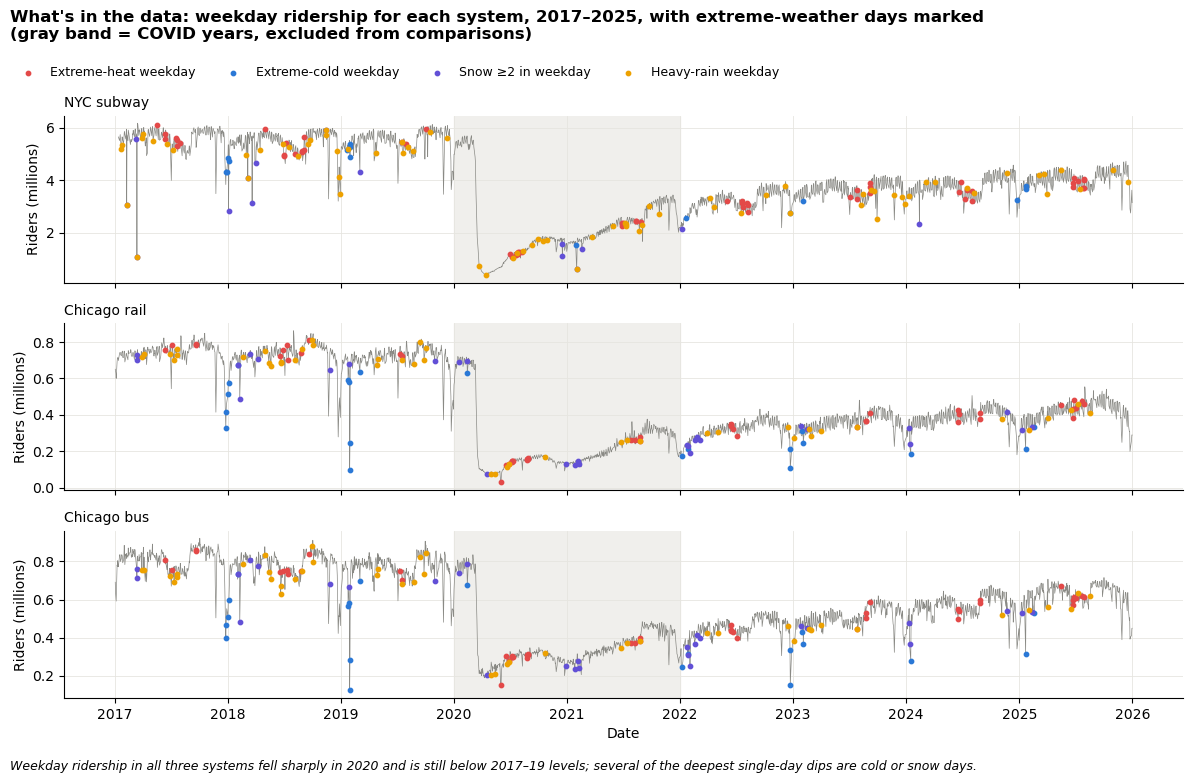

period            covid  post_covid  pre_covid
mode                                          
Chicago bus    323500.0    537644.0   796682.0
Chicago rail   172408.0    380250.0   738412.0
NYC subway    1848402.0   3717874.0  5645394.0


In [49]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": .6, "axes.axisbelow": True, "font.size": 10})
MCOL = {"NYC subway": "#4d4d4d", "Chicago rail": "#1a9aa0", "Chicago bus": "#1baf7a"}
ECOL = {"extreme_heat": "#e34948", "extreme_cold": "#2a78d6","snow_2in": "#6250d6", "heavy_rain": "#eda100"}
EVCOL = {"Extreme heat": ECOL["extreme_heat"], "Extreme cold": ECOL["extreme_cold"],
         "Snow ≥2 in": ECOL["snow_2in"], "Heavy rain ≥1 in": ECOL["heavy_rain"]}
def shade(c, p):   # light for 2017-19, full color for 2022-25
    r = np.array(to_rgb(c)); return tuple(r + (1 - r) * .55) if p == "pre_covid" else tuple(r)
PLAB = {"pre_covid": "2017–19", "post_covid": "2022–25"}

import textwrap
def caption(fig, text, y=-.06):
    # one-sentence caption under the chart, wrapped to the figure's width
    fig.text(.01, y, textwrap.fill(text, width=int(fig.get_figwidth() * 14)), fontsize=9, style="italic", va="top")

# P1 Overview
fig, axes = plt.subplots(len(MODES), 1, figsize=(12, 7.5), sharex=True)
for ax, m in zip(axes, MODES):
    x = mode_day[(mode_day["mode"] == m) & (mode_day.day_type == "W")].set_index("date").sort_index()
    ax.plot(x.index, x.ridership / 1e6, color="#8a8a85", lw=.5)
    for ev, lab in [("extreme_heat", "Extreme-heat weekday"), ("extreme_cold", "Extreme-cold weekday"), ("snow_2in", "Snow ≥2 in weekday"), ("heavy_rain", "Heavy-rain weekday")]:
        e = x[x[ev].astype(bool)]
        ax.scatter(e.index, e.ridership / 1e6, s=10, color=ECOL[ev], zorder=3, label=lab)
    ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2021-12-31"), color="#f0efec", zorder=0)
    ax.set_title(m, loc="left", fontsize=10); ax.set_ylabel("Riders (millions)")
axes[-1].set_xlabel("Date")
fig.tight_layout(rect=(0, 0, 1, .9))
fig.suptitle("What's in the data: weekday ridership for each system, 2017–2025, with extreme-weather days marked\n(gray band = COVID years, excluded from comparisons)",
             x=.01, ha="left", fontweight="bold", y=.995)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, ncol=4, loc="upper left", bbox_to_anchor=(.005, .935), fontsize=9)
caption(fig, "Weekday ridership in all three systems fell sharply in 2020 and is still below 2017–19 levels; several of the deepest single-day dips are cold or snow days.", y=-.005)
fig.savefig(FIG_DIR / "P1_overview.png", dpi=150, bbox_inches="tight"); plt.show()
print(mode_day[mode_day.day_type == "W"].groupby(["mode", "period"])["ridership"].median().unstack().round(0))

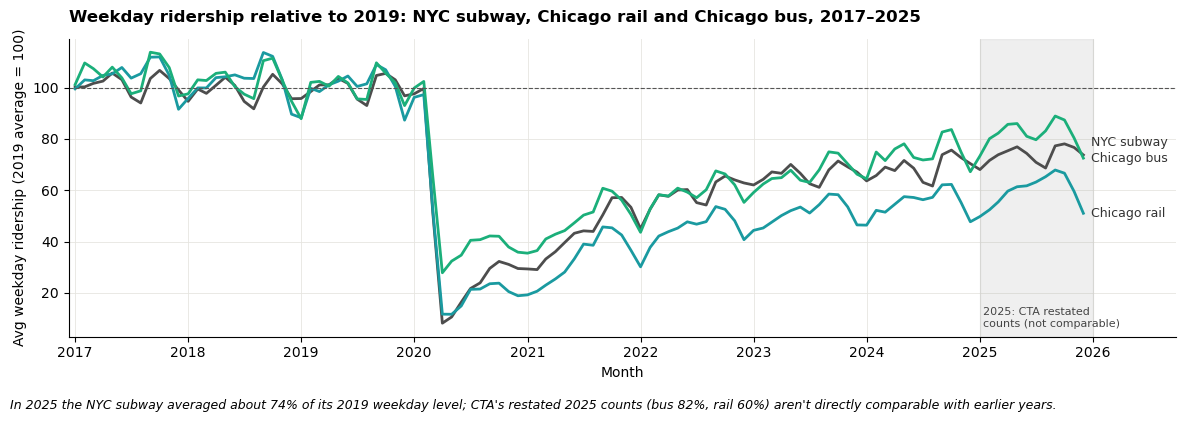

2025 level vs 2019 (=100): {'Chicago bus': 82.0, 'Chicago rail': 60.0, 'NYC subway': 74.0}


In [50]:
# P2 Trend: weekday ridership relative to 2019
w = mode_day[(mode_day.day_type == "W") & mode_day.valid].copy()
w["month"] = w["date"].dt.to_period("M").dt.to_timestamp()
mm = w.groupby(["mode", "month"])["ridership"].mean().unstack(0)
idx = mm / mm[mm.index.year == 2019].mean() * 100
fig, ax = plt.subplots(figsize=(12, 4))
for m in MODES:
    ax.plot(idx.index, idx[m], color=MCOL[m], lw=2, label=m)
# Shade 2025: CTA restated its 2025 counts, so it isn't directly comparable with earlier years
ax.axvspan(pd.Timestamp("2025-01-01"), idx.index[-1] + pd.Timedelta(days=31), color="#999", alpha=.15)
ax.text(pd.Timestamp("2025-01-10"), 6, "2025: CTA restated\ncounts (not comparable)", fontsize=8, va="bottom", color="#444")
last = sorted(((idx[m].dropna().iloc[-1], m) for m in MODES))
prev = None
for y, m in last:                                  # nudge end labels apart so they don't overlap
    if prev is not None and y - prev < 6: y = prev + 6
    ax.text(idx.index[-1], y, "  " + m, color="#333", va="center", fontsize=9); prev = y
ax.axhline(100, color="#555", lw=.8, ls="--")
ax.set_xlim(idx.index[0] - pd.Timedelta(days=20), idx.index[-1] + pd.Timedelta(days=300))
ax.set_ylabel("Avg weekday ridership (2019 average = 100)"); ax.set_xlabel("Month")
ax.set_title("Weekday ridership relative to 2019: NYC subway, Chicago rail and Chicago bus, 2017–2025", loc="left", fontweight="bold", pad=12)
lvl = idx[idx.index.year == 2025].mean().round(0)
fig.tight_layout()
caption(fig, f"In 2025 the NYC subway averaged about {lvl['NYC subway']:.0f}% of its 2019 weekday level; CTA's restated 2025 counts "
             f"(bus {lvl['Chicago bus']:.0f}%, rail {lvl['Chicago rail']:.0f}%) aren't directly comparable with earlier years.", y=-.01)
fig.savefig(FIG_DIR / "P2_recovery_trend.png", dpi=150, bbox_inches="tight"); plt.show()
print("2025 level vs 2019 (=100):", idx[idx.index.year == 2025].mean().round(0).to_dict())

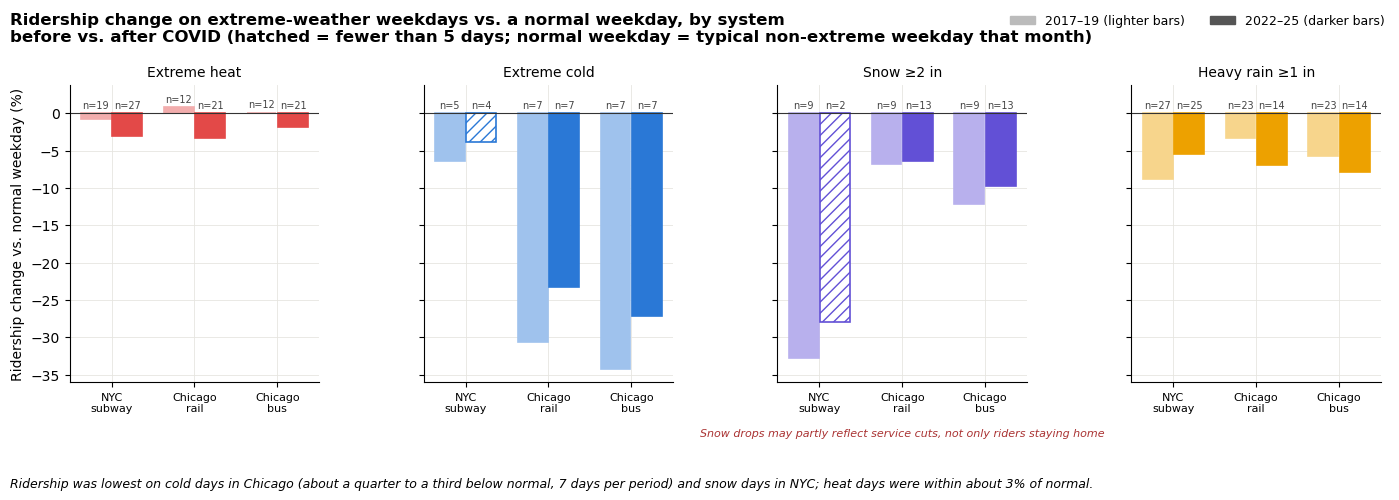

                                mean_pct               n_days          
period                        post_covid pre_covid post_covid pre_covid
event            group                                                 
Extreme cold     Chicago bus       -27.1     -34.3        7.0       7.0
                 Chicago rail      -23.3     -30.7        7.0       7.0
                 NYC subway         -3.9      -6.4        4.0       5.0
Extreme heat     Chicago bus        -1.9       0.1       21.0      12.0
                 Chicago rail       -3.3       0.8       21.0      12.0
                 NYC subway         -3.0      -0.8       27.0      19.0
Heavy rain ≥1 in Chicago bus        -7.9      -5.7       14.0      23.0
                 Chicago rail       -6.9      -3.3       14.0      23.0
                 NYC subway         -5.4      -8.8       25.0      27.0
Snow ≥2 in       Chicago bus        -9.8     -12.2       13.0       9.0
                 Chicago rail       -6.4      -6.9       13.0   

In [51]:
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
def bars(summary, groups, show, title, fname, labels=None, note_snow=True, rows=False, split_at=None, cap=""):
    if rows:
        fig, axes = plt.subplots(len(show), 1, figsize=(14, 3.4 * len(show)), sharex=True, sharey=True)
    else:
        fig, axes = plt.subplots(1, len(show), figsize=(14, 4.6), sharey=True)
    x = np.arange(len(groups))
    for ax, ev in zip(axes, show):
        s = summary[summary.event == ev].set_index(["group", "period"])
        for j, p in enumerate(PERIODS):
            xs = x + (j - .5) * .38
            for k, (xi, g) in enumerate(zip(xs, groups)):
                v, n = s.loc[(g, p), "mean_pct"], s.loc[(g, p), "n_days"]
                ok = n >= 5 and pd.notna(v)
                c = shade(EVCOL[ev], p)
                ax.bar(xi, v if pd.notna(v) else 0, .36, color=c if ok else "white", edgecolor=c,
                       hatch=None if ok else "///", linewidth=1.2, label=PLAB[p] if k == 0 else None)
                ax.text(xi, (max(v, 0) if pd.notna(v) else 0) + .4, f"n={n}", ha="center", va="bottom", fontsize=7, color="#444")
        ax.axhline(0, color="#333", lw=.8)
        ax.set_xticks(x, labels or groups, fontsize=8)
        ax.set_title(ev, fontsize=10, loc="left" if rows else "center")
        if split_at:
            ax.axvline(split_at - .5, color="#999", lw=1, ls="--")
    if split_at:   # city labels above the first panel, centred over each city's groups
        tr = axes[0].get_xaxis_transform()
        axes[0].text((split_at - 1) / 2, 1.04, "New York City (subway)", transform=tr, ha="center", fontsize=9, color="#444", fontweight="bold")
        axes[0].text(split_at + (len(groups) - split_at - 1) / 2, 1.04, "Chicago ('L' rail)", transform=tr, ha="center", fontsize=9, color="#444", fontweight="bold")
    for ax in (axes if rows else axes[:1]):
        ax.set_ylabel("Change vs. normal weekday (%)" if rows else "Ridership change vs. normal weekday (%)")
    for ax in axes: ax.set_xlabel("")
    top = np.nanmax([summary.loc[summary.event.isin(show), "mean_pct"].max(), 0])
    axes[0].set_ylim(top=top + 3)
    if note_snow:
        i = [k for k, e in enumerate(show) if "Snow" in e][0]
        note = "Snow drops may partly reflect service cuts, not only riders staying home"
        if rows:
            axes[i].set_title(note, loc="right", fontsize=8, style="italic", color="#a33")
        else:
            axes[i].text(.5, -.18, note, transform=axes[i].transAxes, ha="center", fontsize=8, style="italic", color="#a33")
    fig.legend(handles=[Patch(color="#bbbbbb", label=PLAB["pre_covid"] + " (lighter bars)"),
                    Patch(color="#555555", label=PLAB["post_covid"] + " (darker bars)")],
           frameon=False, ncol=2, loc="upper right", bbox_to_anchor=(1, 1.0), fontsize=9)
    fig.suptitle(title, x=.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, .965) if rows else (0, 0, 1, 1))
    caption(fig, cap, y=-.005 if rows else -.03)
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight"); plt.show()

SHOW = ["Extreme heat", "Extreme cold", "Snow ≥2 in", "Heavy rain ≥1 in"]
# P3 Comparison across systems
bars(sum_mode, MODES, SHOW,
    "Ridership change on extreme-weather weekdays vs. a normal weekday, by system\nbefore vs. after COVID (hatched = fewer than 5 days; normal weekday = typical non-extreme weekday that month)",
     "P3_systems_comparison.png", labels=["NYC\nsubway", "Chicago\nrail", "Chicago\nbus"],
     cap="Ridership was lowest on cold days in Chicago (about a quarter to a third below normal, 7 days per period) and snow days in NYC; heat days were within about 3% of normal.")
print(sum_mode[sum_mode.event.isin(SHOW)].pivot_table(index=["event", "group"], columns="period",
      values=["mean_pct", "n_days"]).round(1).to_string())

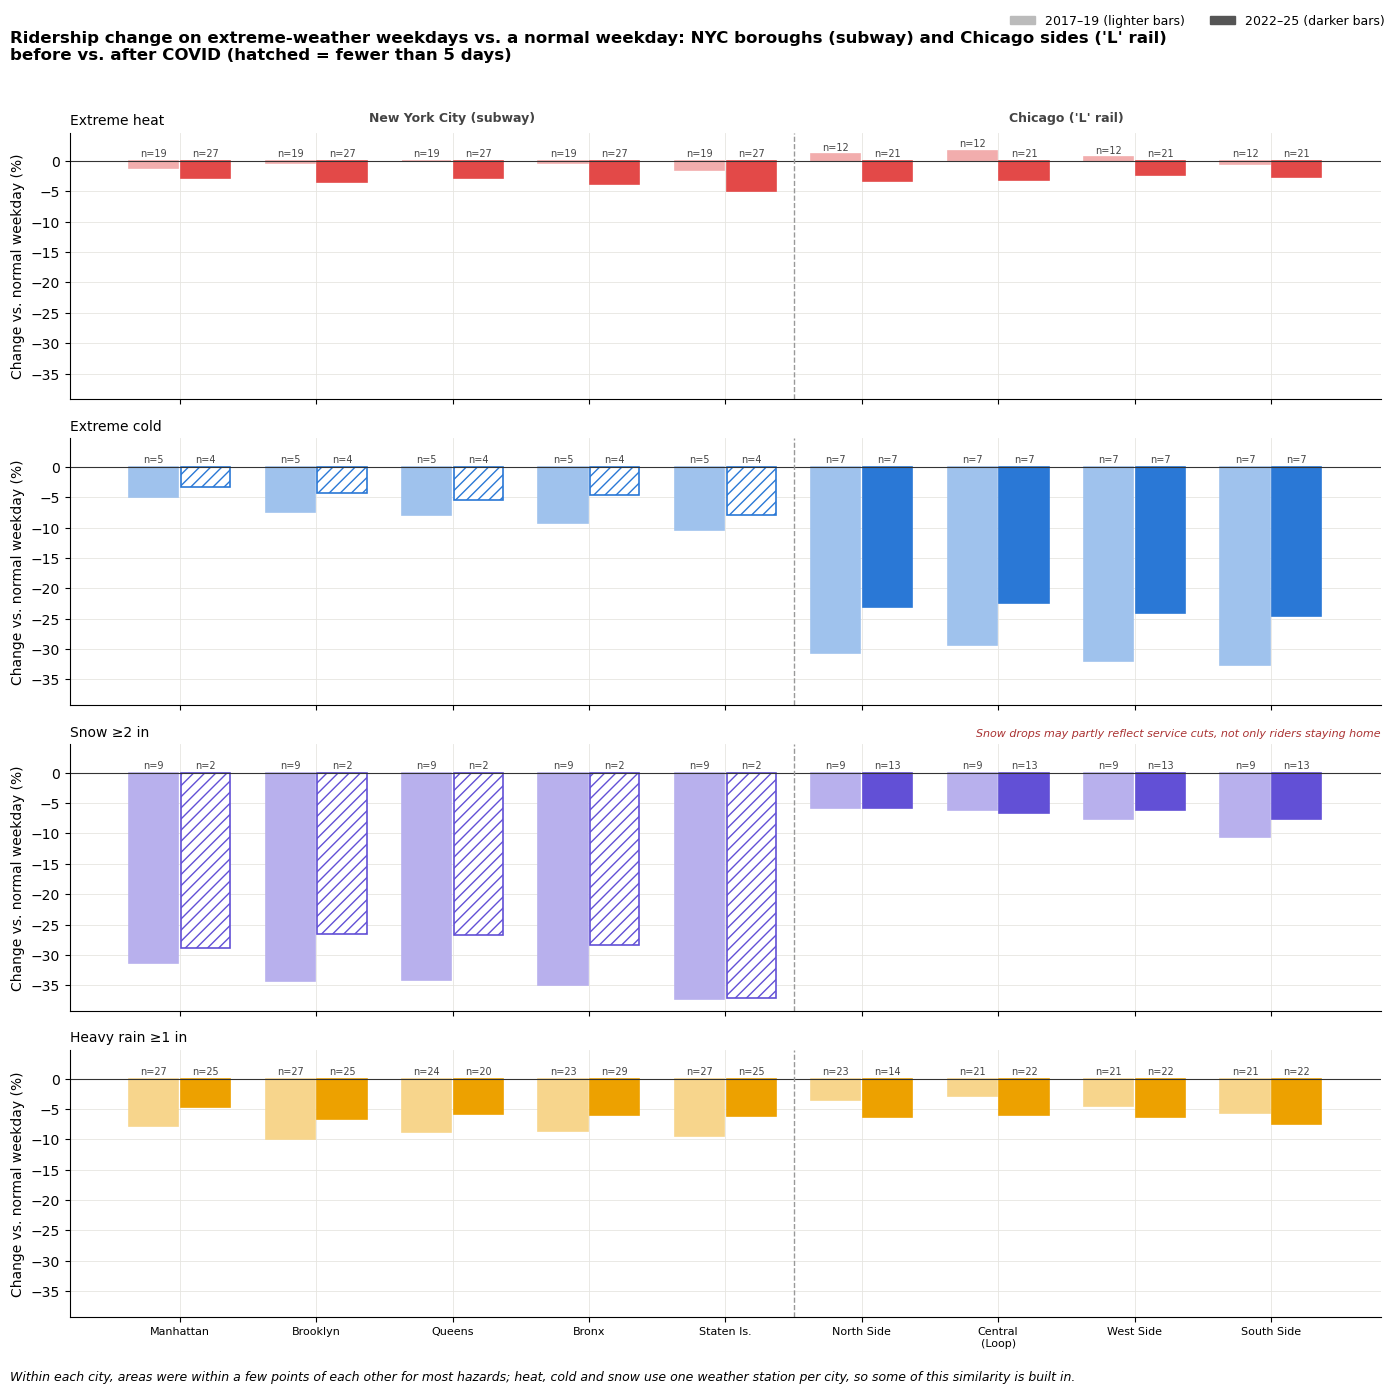

                                      mean_pct               n_days          
period                              post_covid pre_covid post_covid pre_covid
event            group                                                       
Extreme cold     Bronx                    -4.7      -9.2        4.0       5.0
                 Brooklyn                 -4.3      -7.5        4.0       5.0
                 Chicago Central         -22.4     -29.3        7.0       7.0
                 Chicago North Side      -23.1     -30.7        7.0       7.0
                 Chicago South Side      -24.5     -32.7        7.0       7.0
                 Chicago West Side       -24.1     -32.0        7.0       7.0
                 Manhattan                -3.4      -5.0        4.0       5.0
                 Queens                   -5.5      -7.9        4.0       5.0
                 Staten Island            -7.9     -10.4        4.0       5.0
Extreme heat     Bronx                    -3.8      -0.4       2

In [52]:
# P4 Comparison across places: NYC boroughs and Chicago regions
bars(sum_area, AREAS, SHOW,
     "Ridership change on extreme-weather weekdays vs. a normal weekday: NYC boroughs (subway) and Chicago sides ('L' rail)\n"
     "before vs. after COVID (hatched = fewer than 5 days)",
     "P4_areas_nyc_chicago.png", rows=True, split_at=len(BOROUGHS),
     labels=["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Is.", "North Side", "Central\n(Loop)", "West Side", "South Side"],
     cap="Within each city, areas were within a few points of each other for most hazards; heat, cold and snow use one weather station per city, so some of this similarity is built in.")
print(sum_area[sum_area.event.isin(SHOW)].pivot_table(index=["event", "group"], columns="period",
      values=["mean_pct", "n_days"]).round(1).to_string())

  ✓ P5 caption: the 5 highest stations are beach stops (Beach 105 St (A,S), Beach 90 St (A,S), Beach
      98 St (A,S), Rockaway Park-Beach 116 St (A,S), Beach 67 St (A))


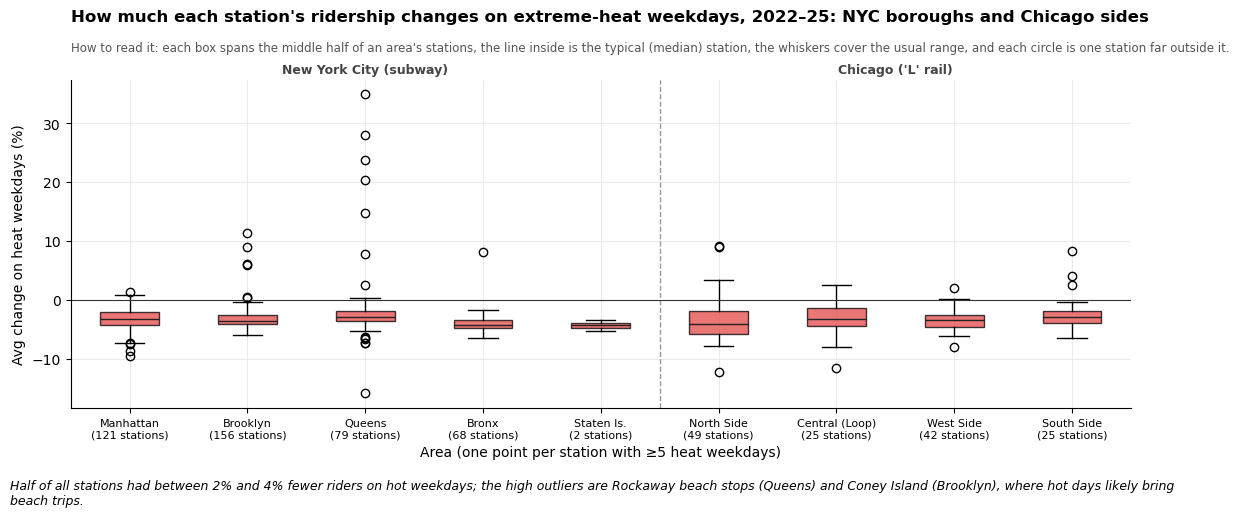

Five stations per area losing the most riders on heat weekdays:
city               area station_id                         station_name  mean  size  \
 NYC              Bronx        370                      Whitlock Av (6)  -6.5    27   
 NYC              Bronx        380 Bedford Park Blvd-Lehman College (4)  -6.3    27   
 NYC              Bronx        425                Bronx Park East (2,5)  -5.7    27   
 NYC              Bronx        421                    Gun Hill Rd (2,5)  -5.7    27   
 NYC              Bronx        372                      Longwood Av (6)  -5.7    27   
 NYC           Brooklyn        177           Clinton-Washington Avs (C)  -5.9    27   
 NYC           Brooklyn        252                         Avenue X (F)  -5.8    27   
 NYC           Brooklyn        127                        DeKalb Av (L)  -5.7    27   
 NYC           Brooklyn        114                       Central Av (M)  -5.6    27   
 NYC           Brooklyn        235                          York S

In [53]:
# P5 Distribution: how stations differ on extreme-heat weekdays (2022–25)
heat = res_st[res_st.extreme_heat.astype(bool) & (res_st.period == "post_covid")]
per_st = heat.groupby(["city", "area", "station_id", "station_name"])["pct_change"].agg(mean="mean", size="count").reset_index()
per_st["community_area"] = per_st["station_id"].map(cta_st_lookup["community_area"])   # Chicago only
per_st = per_st[per_st["size"] >= 5]
CITY_C = {"NYC": ECOL["extreme_heat"], "CHI": ECOL["extreme_heat"]}
# The caption names the high outliers; stop if the data no longer supports that
top = per_st.nlargest(5, "mean")
check(top["station_name"].str.contains("Beach|Coney|Aquarium").all(),
      f"P5 caption: the 5 highest stations are beach stops ({', '.join(top.station_name)})")
q25, q75 = per_st["mean"].quantile([.25, .75])
fig, ax = plt.subplots(figsize=(13, 4.8))
data = [per_st.loc[per_st.area == a, "mean"].dropna() for a in AREAS]
bp = ax.boxplot(data, patch_artist=True, widths=.5, medianprops=dict(color="#222"))
for patch, a in zip(bp["boxes"], AREAS):
    patch.set_facecolor(CITY_C["CHI" if a.startswith("Chicago") else "NYC"]); patch.set_alpha(.75)
short = [a.replace("Chicago ", "").replace("Central", "Central (Loop)").replace("Staten Island", "Staten Is.") for a in AREAS]
ax.set_xticks(range(1, len(AREAS) + 1), [f"{a}\n({plural(len(v), 'station')})" for a, v in zip(short, data)], fontsize=8)
ax.axvline(len(BOROUGHS) + .5, color="#999", lw=1, ls="--")
ax.axhline(0, color="#333", lw=.8)
ax.set_ylabel("Avg change on heat weekdays (%)"); ax.set_xlabel("Area (one point per station with ≥5 heat weekdays)")
ax.set_title("How much each station's ridership changes on extreme-heat weekdays, 2022–25: NYC boroughs and Chicago sides",
             loc="left", fontweight="bold", pad=42)
ax.text(0, 1.085, "How to read it: each box spans the middle half of an area's stations, the line inside is the typical (median) station, "
        "the whiskers cover the usual range, and each circle is one station far outside it.", transform=ax.transAxes, fontsize=8.5, color="#555")
tr = ax.get_xaxis_transform()
ax.text((len(BOROUGHS) + 1) / 2, 1.01, "New York City (subway)", transform=tr, ha="center", va="bottom", fontsize=9, color="#444", fontweight="bold")
ax.text(len(BOROUGHS) + (len(CHI_REGIONS) + 1) / 2, 1.01, "Chicago ('L' rail)", transform=tr, ha="center", va="bottom", fontsize=9, color="#444", fontweight="bold")
fig.tight_layout()
caption(fig, f"Half of all stations had between {-q75:.0f}% and {-q25:.0f}% fewer riders on hot weekdays; the high outliers are Rockaway "
             "beach stops (Queens) and Coney Island (Brooklyn), where hot days likely bring beach trips.", y=-.01)
fig.savefig(FIG_DIR / "P5_station_distribution.png", dpi=150, bbox_inches="tight"); plt.show()
top5 = per_st.sort_values("mean").groupby("area").head(5).sort_values(["area", "mean"])
top5["note"] = station_note(top5["station_id"])
top5.to_csv(CLEAN_DIR / "result_top5_heat_losers_by_area.csv", index=False)
print("Five stations per area losing the most riders on heat weekdays:"); print(top5.round(1).to_string(index=False))

[ANALYSIS P6] Chart P6 counted all days, but the % change results use weekdays outside Dec 20-Jan 2
    only: 2,056 rows -> P6 now counts the same weekdays the results use (city-days left out shown;
    changed after Round 3)


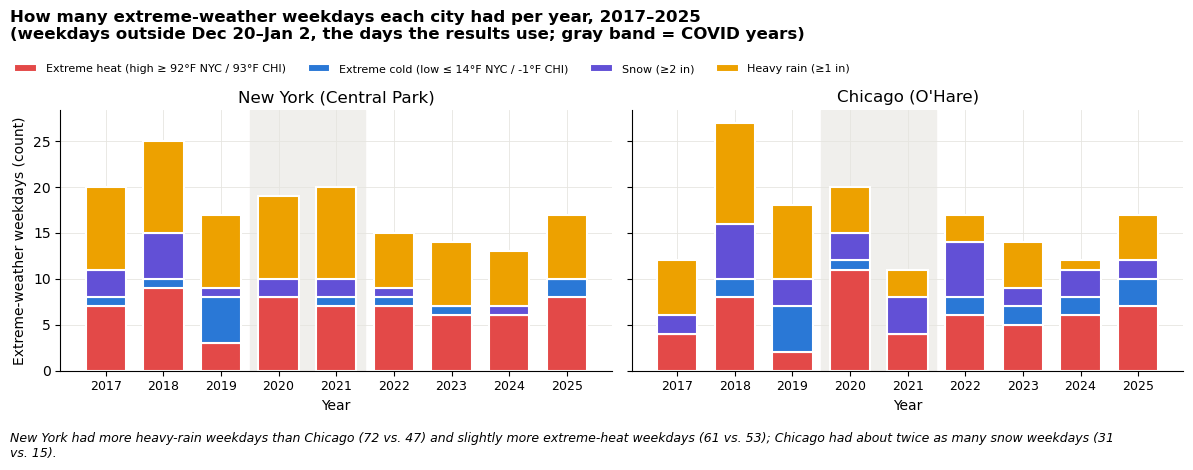

      extreme_heat  extreme_cold  snow_2in  heavy_rain
city                                                  
CHI             53            17        31          47
NYC             61            12        15          72
Weekdays with two hazards at once (e.g. snow and cold), counted in both bars: 10


In [54]:
# P6 Context: extreme-weather days per year (from the NOAA notebook's Chart 1)
PFLAGS = ["extreme_heat", "extreme_cold", "snow_2in", "heavy_rain"]
FLAG_C = {f: ECOL[f] for f in PFLAGS}
LABEL = {"extreme_heat": f"Extreme heat (high ≥ {TH['NYC']['heat']:.0f}°F NYC / {TH['CHI']['heat']:.0f}°F CHI)",
         "extreme_cold": f"Extreme cold (low ≤ {TH['NYC']['cold']:.0f}°F NYC / {TH['CHI']['cold']:.0f}°F CHI)",
         "snow_2in": "Snow (≥2 in)", "heavy_rain": "Heavy rain (≥1 in)"}
cda = city_day[city_day.period != "buffer"]
cdw = cda[(cda["date"].dt.dayofweek < 5) & ~in_holiday_window(cda["date"])].copy()
log("P6", "Chart P6 counted all days, but the % change results use weekdays outside Dec 20-Jan 2 only", len(cda) - len(cdw),
    "P6 now counts the same weekdays the results use (city-days left out shown; changed after Round 3)",
    "Counting all days (overstates how many days are behind each result)")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
counts = cdw.groupby(["city", "year"])[PFLAGS].sum()
for ax, cty in zip(axes, ["NYC", "CHI"]):
    c = counts.loc[cty]; bottom = np.zeros(len(c))
    for f in PFLAGS:
        ax.bar(c.index, c[f], bottom=bottom, color=FLAG_C[f], label=LABEL[f], edgecolor="white", linewidth=1.5, width=.7)
        bottom += c[f].values
    ax.set_title({"NYC": "New York (Central Park)", "CHI": "Chicago (O'Hare)"}[cty])
    ax.set_xlabel("Year"); ax.axvspan(2019.5, 2021.5, color="#f0efec", zorder=0)
    ax.set_xticks(c.index); ax.tick_params(axis="x", labelsize=9)
axes[0].set_ylabel("Extreme-weather weekdays (count)")
tot = counts.groupby("city").sum()
both = int((cdw[PFLAGS].sum(axis=1) > 1).sum())
fig.tight_layout(rect=(0, 0, 1, .84))
fig.suptitle("How many extreme-weather weekdays each city had per year, 2017–2025\n(weekdays outside Dec 20–Jan 2, the days the results use; gray band = COVID years)",
             x=.01, ha="left", fontweight="bold", y=.995)
fig.legend(*axes[1].get_legend_handles_labels(), frameon=False, ncol=4, loc="upper left", bbox_to_anchor=(.005, .89), fontsize=8)
caption(fig, f"New York had more heavy-rain weekdays than Chicago ({tot.loc['NYC', 'heavy_rain']} vs. {tot.loc['CHI', 'heavy_rain']}) and "
             f"slightly more extreme-heat weekdays ({tot.loc['NYC', 'extreme_heat']} vs. {tot.loc['CHI', 'extreme_heat']}); "
             f"Chicago had about twice as many snow weekdays ({tot.loc['CHI', 'snow_2in']} vs. {tot.loc['NYC', 'snow_2in']}).", y=-.01)
fig.savefig(FIG_DIR / "P6_extreme_days_per_year.png", dpi=150, bbox_inches="tight"); plt.show()
print(tot); print(f"Weekdays with two hazards at once (e.g. snow and cold), counted in both bars: {both}")

# Part 8 — Round 2: follow-up requests and their status
After Round 1, the decision-maker (**Alex**, VP Operations Planning, NYC Transit) and the end user (**Shirley**, a Loop commuter on the CTA 'L') asked for more. Each request is analyzed below and marked **Answered**, **Partially answered**, **Not answerable with this data**, or **Out of scope**, with a reason. *Raised:* R1 = reacting to the Round 1 briefing pack; R2 = during Round 2; after R2 = needs they still stated at the end of Round 2. *Where* points to the labeled analysis cells below (R2-1, R2-2, …) and to the briefing-pack charts (P1–P7).

**Summary:** 32 requests: 22 answered, 3 partially answered, 5 not answerable with this data, 2 out of scope.

### Alex — decision-maker (NYC subway)
| # | Request | Raised | Status | Reason / result | Where |
|---|---|---|---|---|---|
| A1 | Compare NYC snow days with scheduled service | R1 | Not answerable with this data | No scheduled or delivered service data in our sources, so a drop can't be split into riders staying home vs. service cuts | — |
| A2 | Expected annual loss per hazard (days per year × drop per day), in one view | R1 | Answered | Rides lost per year for heat, cold, snow and heavy rain; heavy rain is the largest NYC hazard by volume after COVID | R2-1 (3)–(4) |
| A3 | Riders lost by borough, in volume rather than % | R1 | Answered | Manhattan is about half of rides lost and Brooklyn about a quarter, which mostly mirrors where riders are | R2-1 (5) |
| A4 | A finer cut than borough: by subway line | R1 | Out of scope | Possible from station IDs but not done in this phase; carried into the requirements document | — |
| A5 | Flood-prone or heat-exposed stations vs. the rest | R1, after R2 | Not answerable with this data | No flood or heat exposure data in our sources | — |
| A6 | Does one Central Park reading make the boroughs look alike? | R1 | Answered | Partly, by construction: heat, cold and snow use one station per city, so boroughs can't differ in weather. Stated on the borough view | P4; Part 1 |
| A7 | Ranges on the before/after-COVID results (19 vs. 27 heat days) | R1 | Answered | Ranges added; the heat ranges overlap across periods | R2-1 (2); R2-2 (C) |
| A8 | Compare weather days with the same weekday (hybrid work) | R1 | Answered | Already in the method: each extreme weekday is compared with normal days on the same weekday in the same month | Part 6 |
| A9 | Weather's effect next to the post-COVID recovery gap | R1 | Answered | Largest hazard is about 0.33% of annual ridership (NYC snow, 2017–19); NYC subway was at 74% of 2019 in 2025 | R2-2 (A); P2 |
| A10 | Name the P5 outlier stations; are events or something structural behind them? | R1 | Partially answered | Named and annotated: Rockaway beach stops and Coney Island rise on hot days; Mets-Willets Point, Wrigley Field (Addison) and McCormick Place fall. Trip purpose and events are likely, but the data can't prove the cause. The G-line stops shown in Round 2 turned out to be a service suspension, not weather (see Part 9, revisions after Round 3) | R2-1 (7); R2-2 (F) |
| A11 | Everything per year, with the days per year behind each number | R2 | Answered | Per-year table (3 years for 2017–19, 4 for 2022–25) | R2-2 (A) |
| A12 | Each hazard as a share of annual ridership | R2 | Answered | Largest is 0.33% (NYC snow, 2017–19); at most 0.14% in any system after COVID | R2-2 (A) |
| A13 | A range around each number | R2 | Answered | Best and worst year for each hazard, plus episode-based ranges | R2-2 (A), (C) |
| A14 | Heavy rain in the same view as heat | R2 | Answered | All four hazards in one table | R2-2 (A) |
| A15 | Report heat as "no detectable change" rather than a shift | after R2 | Answered | Adopted: heat's ranges overlap across periods | R2-2 (C), (E) |
| A16 | Ridership on days with vs. without service cuts | after R2 | Not answerable with this data | Same reason as A1 | — |
| A17 | Peak vs. off-peak drops | after R2 | Out of scope | The notebook uses daily totals. MTA's hourly data could answer this for NYC later; CTA publishes daily totals only | — |
| A18 | One page: hazard by borough on a common scale, with sample sizes and the one-station caveat | R1, after R2 | Partially answered | P4 shows hazard by borough on one scale with n; the one-page layout itself goes into the requirements document | P4 |

### Shirley — end user (CTA 'L' commuter)
| # | Request | Raised | Status | Reason / result | Where |
|---|---|---|---|---|---|
| S1 | Is cold really worse than snow, or is it the small sample? | R1 | Answered | Chicago rail: cold about −23% to −31%, snow about −6% to −7%; the ranges barely touch, but cold rests on 14 days | R2-1 (2) |
| S2 | Does "25% fewer riders" mean 1 in 4 people stayed home? | R1 | Answered | No: about a quarter fewer rides than a normal weekday. Who stayed home isn't measured | P7 wording |
| S3 | How many extreme-cold days in a typical winter? | R1 | Answered | About 2 weekdays a year (2.3 in 2017–19, 1.8 in 2022–25) | R2-1 (3) |
| S4 | Does a big snow (6+ in) differ from 2 in? | R1 | Not answerable with this data | Too few Chicago snow days to split by size | — |
| S5 | Explain "2019 = 100" on the trend chart | R1 | Answered | P2's axis now reads "2019 average = 100" | P2 |
| S6 | Is the bus a safer backup? | R1 | Answered | No: on cold and snow days the bus drops as much as rail or more | R2-1 (2); R3-2 (2) |
| S7 | One simple chart: Chicago trains only, one bar per hazard, "about X fewer", with days per year | R2 | Answered | Built as P7 | R2-2 (G); P7 |
| S8 | Show the ranges, or don't use the word "interval" | R2 | Answered | The word was dropped; P7 shows a typical day and the worst day | P7 |
| S9 | Say plainly that fewer riders isn't the same as a bad ride | R2 | Answered | Stated in P7's caption | P7 |
| S10 | Is −1°F the daily low or the high? | R2 | Answered | The daily (overnight) low; P7's cold label says so | P7 |
| S11 | Any sign whether cold-day drops are skipped trains or people staying home? | after R2 | Not answerable with this data | No service data; P7 says we can't tell | — |
| S12 | Are cold days clumped together or spread out? | after R2 | Answered (not yet shared with Shirley) | Spread out: Chicago's 14 cold weekdays fall in 11 separate episodes; the only multi-day run is Jan 29–31, 2019 | R2-1 (6) |
| S13 | Is the Loop different on cold days after COVID? | after R2 | Answered (not yet shared with Shirley) | No: Chicago Central −22.4% vs. −23.1% to −24.5% for the other sides (2022–25, 7 days each) | P4 table (Part 7) |
| S14 | Label wording: "about 1 in 4, sometimes closer to 1 in 3"; a note that snow's range starts at 0 | after R2 | Partially answered | "Daily low" was added and P7 now shows typical and worst days; the "1 in 4" wording and the snow note aren't on the chart | P7 |

### R2-1 · Round 2 follow-ups, first pass
Noise check, ranges, days per year, annual loss, loss by area, cold and snow episodes, and named station outliers (numbered (1)–(7) in the code).

In [55]:
SOURCE = "ROUND2"
rng = np.random.default_rng(7)
YEARS = {"pre_covid": 3, "post_covid": 4}   # 2017-19, 2022-25

def boot_ci(x, n=5000):
    x = np.asarray(x.dropna());
    if len(x) < 2: return (np.nan, np.nan)
    m = rng.choice(x, (n, len(x))).mean(axis=1)
    return tuple(np.percentile(m, [2.5, 97.5]))

# 1) Noise check: how far does an ordinary (non-extreme) weekday sit from its own baseline?
normal_days = res_mode[~res_mode.any_extreme.astype(bool) & ~res_mode.is_holiday.astype(bool)
                       & res_mode.period.isin(PERIODS)]
noise = normal_days.groupby(["mode", "period"])["pct_change"].agg(
    mean="mean", sd="std", p25=lambda v: v.quantile(.25), p75=lambda v: v.quantile(.75)).round(1)
print("Spread of NORMAL weekdays vs their own baseline (% change):"); print(noise.to_string())

# 2) Uncertainty: bootstrap 95% interval on every system bar
rows = []
for ev, lab in EVENTS.items():
    for m in MODES:
        for p in PERIODS:
            x = res_mode[res_mode[ev].astype(bool) & (res_mode["mode"] == m) & (res_mode.period == p)]["pct_change"]
            lo, hi = boot_ci(x)
            rows.append(dict(event=lab, mode=m, period=p, n_days=int(x.notna().sum()),
                             mean_pct=x.mean(), ci_low=lo, ci_high=hi))
ci = pd.DataFrame(rows).round(1)
print("\n% change with 95% interval:"); print(ci.to_string(index=False))
ci.to_csv(CLEAN_DIR / "result_pct_change_with_ci.csv", index=False)

# 3) Extreme weekdays per year (weekday-only, same days used in the % change)
cnt = (res_mode[res_mode.period.isin(PERIODS)].assign(year=lambda d: d["date"].dt.year)
       .melt(id_vars=["mode", "year", "period", "pct_change"], value_vars=list(EVENTS),
             var_name="ev", value_name="flag").query("flag == True and pct_change == pct_change"))
per_year = cnt.groupby(["mode", "period", "ev"]).size().div(
    cnt["period"].map(YEARS).groupby([cnt["mode"], cnt["period"], cnt["ev"]]).first()).round(1)
print("\nExtreme weekdays per year (typical):"); print(per_year.unstack("period").to_string())

# 4) Expected annual riders lost per hazard (system level)
res_mode["lost"] = res_mode["baseline"] - res_mode["ridership"]
rows = []
for ev, lab in EVENTS.items():
    for m in MODES:
        for p in PERIODS:
            x = res_mode[res_mode[ev].astype(bool) & (res_mode["mode"] == m) & (res_mode.period == p) & res_mode["pct_change"].notna()]
            rows.append(dict(event=lab, mode=m, period=p, days_per_year=len(x) / YEARS[p],
                             avg_riders_lost_per_day=x["lost"].mean(),
                             riders_lost_per_year=x["lost"].sum() / YEARS[p]))
exp_loss = pd.DataFrame(rows).round(0)
print("\nExpected annual loss by hazard:"); print(exp_loss.to_string(index=False))

# 5) Riders lost by NYC borough (volume, not %)
res_area["lost"] = res_area["baseline"] - res_area["ridership"]
rows = []
for ev, lab in EVENTS.items():
    for a in AREAS:
        for p in PERIODS:
            x = res_area[res_area[ev].astype(bool) & (res_area["area"] == a) & (res_area.period == p) & res_area["pct_change"].notna()]
            rows.append(dict(event=lab, area=a, period=p, n_days=len(x), avg_riders_lost_per_day=x["lost"].mean()))
lost_area = pd.DataFrame(rows).round(0)
print("\nAvg riders lost per extreme weekday by area:")
print(lost_area.pivot_table(index=["event", "area"], columns="period", values="avg_riders_lost_per_day").to_string())

# 6) Dates and consecutive runs (spot one-event bars like the Jan-2019 cold snap)
for m in MODES:
    for ev in ["extreme_cold", "snow_2in"]:
        d = res_mode[res_mode[ev].astype(bool) & (res_mode["mode"] == m) & res_mode.period.isin(PERIODS)
                     & res_mode["pct_change"].notna()].sort_values("date")
        runs = (d["date"].diff().dt.days.fillna(99) > 3).cumsum()
        print(f"\n{m} {ev}: {plural(len(d), 'day')} in {plural(runs.nunique(), 'separate episode')}")
        print(d.groupby(runs)["date"].agg(["min", "max", "size"]).to_string(index=False))

# 7) Station outliers: name them, with size and number of heat days
name_col = next(c for c in ["station_name", "stationname", "station", "complex_name", "stop_name"] if c in station_all.columns)
st = res_st[res_st.extreme_heat.astype(bool) & res_st.period.isin(PERIODS) & res_st["pct_change"].notna()]
st = st.groupby("station_id").agg(mean_pct=("pct_change", "mean"), n_days=("pct_change", "size"),
                                  typical_daily=("baseline", "median")).reset_index()
names = station_all[["station_id", name_col, "area"]].drop_duplicates("station_id")
st = st.merge(names, on="station_id", how="left").round(1)
st["note"] = station_note(st["station_id"])
print("\nHeat-day outliers (top 8 and bottom 8):")
print(pd.concat([st.nlargest(8, "mean_pct"), st.nsmallest(8, "mean_pct")]).to_string(index=False))

Spread of NORMAL weekdays vs their own baseline (% change):
                         mean   sd  p25  p75
mode         period                         
Chicago bus  post_covid  -0.6  6.0 -2.0  1.6
             pre_covid   -0.7  5.2 -1.6  1.4
Chicago rail post_covid  -0.3  5.9 -2.0  1.9
             pre_covid   -0.5  5.0 -1.6  1.6
NYC subway   post_covid  -0.8  4.5 -1.4  1.0
             pre_covid   -0.9  4.4 -1.2  0.8

% change with 95% interval:
           event         mode     period  n_days  mean_pct  ci_low  ci_high
    Extreme heat   NYC subway  pre_covid      19      -0.8    -2.5      0.8
    Extreme heat   NYC subway post_covid      27      -3.0    -4.5     -1.7
    Extreme heat Chicago rail  pre_covid      12       0.8    -1.0      2.8
    Extreme heat Chicago rail post_covid      21      -3.3    -5.9     -0.8
    Extreme heat  Chicago bus  pre_covid      12       0.1    -2.2      2.7
    Extreme heat  Chicago bus post_covid      21      -1.9    -4.5      1.2
    Extreme cold   

### R2-2 · Round 2 follow-ups, second pass
Per-year losses and share of annual ridership (A), normal-day noise (B), episode-based ranges (C), Chicago cold day by day (D), heat by year (E), outlier-station noise (F), and the simple Chicago trains chart, P7 (G).

*P7 here is the final version.* After Shirley saw the first draft (mean and range per hazard), we added "daily low" to the cold label and switched each bar to a typical day (median) with the worst day noted, which she found easier to picture.

Per-year loss by hazard:
           event         mode     period  years  days_per_year  lost_per_day  lost_per_year  \
    Extreme heat   NYC subway  pre_covid      3            6.3       45412.0       287611.0   
    Extreme heat   NYC subway post_covid      4            6.8      120272.0       811839.0   
    Extreme heat Chicago rail  pre_covid      3            4.0       -4945.0       -19782.0   
    Extreme heat Chicago rail post_covid      4            5.2       12779.0        67091.0   
    Extreme heat  Chicago bus  pre_covid      3            4.0         691.0         2764.0   
    Extreme heat  Chicago bus post_covid      4            5.2       10402.0        54613.0   
    Extreme cold   NYC subway  pre_covid      3            1.7      344103.0       573505.0   
    Extreme cold   NYC subway post_covid      4            1.0      141397.0       141397.0   
    Extreme cold Chicago rail  pre_covid      3            2.3      217095.0       506556.0   
    Extreme cold Chicago 

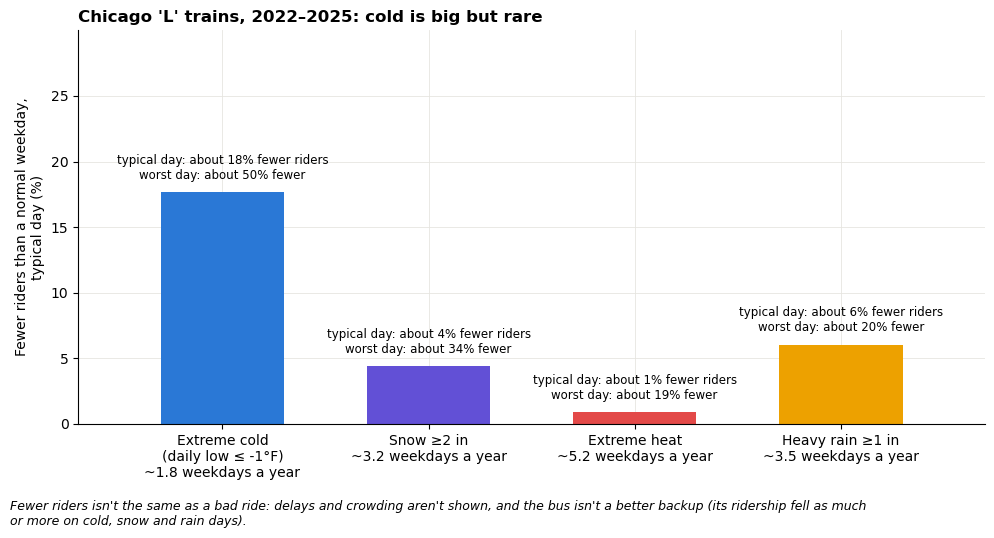

  P7 Extreme heat: typical day -0.9%, worst day -19.3%
  P7 Extreme cold: typical day -17.6%, worst day -49.7%
  P7 Snow ≥2 in: typical day -4.4%, worst day -33.8%
  P7 Heavy rain ≥1 in: typical day -6.0%, worst day -20.2%


In [56]:
SOURCE = "ROUND2"
rng = np.random.default_rng(11)
CHR = "Chicago rail"

def episodes(dates, gap=3):
    d = dates.sort_values()
    return (d.diff().dt.days.fillna(99) > gap).cumsum().reindex(dates.index)

def cluster_ci(x, ep, n=3000):
    groups = [v.to_numpy() for _, v in x.groupby(ep)]
    if len(groups) < 2: return (np.nan, np.nan)
    m = [np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))]).mean() for _ in range(n)]
    return tuple(np.percentile(m, [2.5, 97.5]))

res_mode["lost"] = res_mode["baseline"] - res_mode["ridership"]
base = mode_day[mode_day.valid & mode_day.period.isin(PERIODS)].assign(year=lambda d: d["date"].dt.year)
annual_total = base.groupby(["mode", "period", "year"])["ridership"].sum().groupby(["mode", "period"]).mean()

def flagged(ev, m, p):
    return res_mode[res_mode[ev].astype(bool) & (res_mode["mode"] == m) & (res_mode.period == p)
                    & res_mode["pct_change"].notna()].sort_values("date")

# A) Everything per YEAR, with days per year, share of annual ridership, and best/worst year
rows = []
for ev, lab in EVENTS.items():
    for m in MODES:
        for p in PERIODS:
            yrs = sorted(base[(base["mode"] == m) & (base.period == p)]["year"].unique())
            x = flagged(ev, m, p)
            by_year = x.assign(year=x["date"].dt.year).groupby("year")["lost"].sum().reindex(yrs, fill_value=0)
            rows.append(dict(event=lab, mode=m, period=p, years=len(yrs), days_per_year=np.round(len(x) / len(yrs), 1),
                             lost_per_day=np.round(x["lost"].mean()), lost_per_year=np.round(by_year.mean()),
                             best_year=np.round(by_year.min()), worst_year=np.round(by_year.max()),
                             pct_of_annual=np.round(100 * by_year.mean() / annual_total[(m, p)], 2)))
annual = pd.DataFrame(rows)
print("Per-year loss by hazard:"); print(annual.to_string(index=False))

# B) Share of ordinary weekdays within +/-2% of baseline
nd = res_mode[~res_mode.any_extreme.astype(bool) & ~res_mode.is_holiday.astype(bool) & res_mode.period.isin(PERIODS)]
print("\nShare of normal weekdays within +/-2%:")
print((nd["pct_change"].abs() <= 2).groupby([nd["mode"], nd["period"]]).mean().round(2))

# C) Ranges that treat consecutive days as ONE episode (cluster bootstrap)
rows = []
for ev, lab in EVENTS.items():
    for m in MODES:
        for p in PERIODS:
            x = flagged(ev, m, p); ep = episodes(x["date"]); lo, hi = cluster_ci(x["pct_change"], ep)
            rows.append(dict(event=lab, mode=m, period=p, n_days=len(x), n_episodes=ep.nunique(),
                             mean_pct=x["pct_change"].mean(), low=lo, high=hi))
cl = pd.DataFrame(rows).round(1)
log("R2a", "Extreme weekdays come in runs (one storm or heat wave covers several days), so they aren't independent",
    int(cl["n_days"].sum()),
    f"Ranges resample whole episodes (weekdays within 3 days of each other = one episode; {int(cl['n_episodes'].sum())} "
    "episodes in total), 3,000 times. The day-level ranges in Round 2's first pass (result_pct_change_with_ci.csv) are superseded",
    "Resampling single days (treats a 3-day cold snap as 3 separate events, so ranges come out too narrow)")
print("\n% change with episode-based ranges:"); print(cl.to_string(index=False))

# D) Chicago cold day by day, and pre-COVID without the Jan 29-31, 2019 run
c = res_mode[res_mode.extreme_cold.astype(bool) & (res_mode["mode"] == CHR) & res_mode.period.isin(PERIODS)].sort_values("date")
print("\nChicago rail cold days:"); print(c[["date", "ridership", "baseline", "pct_change"]].round({"ridership": 1, "baseline": 1, "pct_change": 1}).to_string(index=False))
pre = c[c.period == "pre_covid"]; drop = pre["date"].between("2019-01-29", "2019-01-31")
print("Pre-COVID cold, mean with / without Jan 29-31:", round(pre["pct_change"].mean(), 1), round(pre[~drop]["pct_change"].mean(), 1))

# E) Post-COVID heat by year, and excluding 2025
h = res_mode[res_mode.extreme_heat.astype(bool) & (res_mode.period == "post_covid") & res_mode["pct_change"].notna()].assign(year=lambda d: d["date"].dt.year)
print("\nPost-COVID heat, mean % by year:"); print(h.groupby(["mode", "year"])["pct_change"].agg(["mean", "size"]).round(1).unstack("mode").to_string())
for m in MODES:
    x = h[(h["mode"] == m) & (h.year < 2025)].sort_values("date"); lo, hi = cluster_ci(x["pct_change"], episodes(x["date"]))
    print(m, "heat excluding 2025:", round(x["pct_change"].mean(), 1), (round(lo, 1), round(hi, 1)), "n =", len(x))

# F) Day-to-day noise at the outlier stations
ndst = res_st[~res_st.any_extreme.astype(bool) & ~res_st.is_holiday.astype(bool) & res_st["pct_change"].notna()]
ids = pd.concat([st.nlargest(8, "mean_pct"), st.nsmallest(8, "mean_pct")])["station_id"]
ns = ndst[ndst.station_id.isin(ids)].groupby("station_id")["pct_change"].agg(sd="std", p25=lambda v: v.quantile(.25), p75=lambda v: v.quantile(.75)).round(1)
print("\nNormal-day noise at outlier stations:"); print(st[st.station_id.isin(ids)].merge(ns, on="station_id")[[name_col, "mean_pct", "sd", "p25", "p75", "note"]].to_string(index=False))

# G) Shirley's chart: Chicago trains, 2022-25 (typical day + worst day)
days = annual[(annual["mode"] == CHR) & (annual.period == "post_covid")].set_index("event")["days_per_year"]
order = ["Extreme cold", "Snow ≥2 in", "Extreme heat", "Heavy rain ≥1 in"]
cols = [ECOL[k] for k in ["extreme_cold", "snow_2in", "extreme_heat", "heavy_rain"]]

med = {}
for ev, lab in EVENTS.items():
    x = flagged(ev, CHR, "post_covid")["pct_change"]
    med[lab] = (x.median(), x.min())          # typical day, worst day

ticks = [f"Extreme cold\n(daily low ≤ {TH['CHI']['cold']:.0f}°F)\n~{days['Extreme cold']:.1f} weekdays a year"] + \
        [f"{o}\n~{days[o]:.1f} weekdays a year" for o in order[1:]]

fig, ax = plt.subplots(figsize=(10, 5))
vals = [max(0, -med[o][0]) for o in order]
ax.bar(range(4), vals, color=cols, width=.6)
for i, o in enumerate(order):
    ax.text(i, vals[i] + 1, f"typical day: about {-med[o][0]:.0f}% fewer riders\nworst day: about {-med[o][1]:.0f}% fewer",
            ha="center", fontsize=8.5)
ax.set_xticks(range(4)); ax.set_xticklabels(ticks)
ax.set_ylabel("Fewer riders than a normal weekday,\ntypical day (%)"); ax.set_ylim(0, max(vals) * 1.7); ax.set_xlim(-.7, 3.7)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Chicago 'L' trains, 2022–2025: cold is big but rare", loc="left", fontweight="bold")
fig.tight_layout()
caption(fig, "Fewer riders isn't the same as a bad ride: delays and crowding aren't shown, and the bus isn't a better backup (its ridership fell as much or more on cold, snow and rain days).", y=-.01)
fig.savefig(FIG_DIR / "P7_chicago_rail_simple.png", dpi=150, bbox_inches="tight"); plt.show()
for k, v in med.items(): print(f"  P7 {k}: typical day {v[0]:.1f}%, worst day {v[1]:.1f}%")

### R2-3 · Check: Chicago weekday averages, July 2025

In [57]:
chk = mode_day[mode_day.valid & (mode_day.day_type == "W") & (mode_day["date"].dt.to_period("M") == "2025-07")
               & mode_day["mode"].isin(["Chicago bus", "Chicago rail"])]
print(chk.groupby("mode")["ridership"].mean().round(0))

mode
Chicago bus     608960.0
Chicago rail    449088.0
Name: ridership, dtype: float64


# Part 9 — Round 3: the skeptical expert's challenges
**Rebecca** (Senior Transit Data Analyst, CTA) challenged each finding. The table records every challenge, whether it **held up**, and what we changed in response: the finding, the cleaning, or the datasheet. Changes that affect the data or method are also in the cleaning log (entries P6, R2a, R3a, R3b). *Where* points to the labeled cells (R2-1 … R3-3) and charts (P1–P7).

**Summary:** 22 challenges: 17 held up, 4 partly held, 1 didn't hold. Five points were still open at the end of Round 3; R3-3 addresses three of them.

| # | Rebecca's challenge | Held? | What we changed, and why | Where |
|---|---|---|---|---|
| R1 | How far does an ordinary weekday miss its own baseline? If that's ±2–3%, a −3% heat effect is noise | Held | Measured the noise: only 51–58% of normal Chicago weekdays and 64–72% of NYC weekdays are within ±2% of baseline. The noise is reported alongside the heat results | R2-1 (1); R2-2 (B) |
| R2 | Is "typical" a mean or a median? Does it control for day of week? | Didn't hold | Already in the method: the baseline is the median of normal weekdays on the same weekday in the same month | Part 6 |
| R3 | Chicago cold rests on 7 days per period; the late-Jan 2019 dips look like one cold snap | Held | 3 of the 7 pre-COVID days are one run (Jan 29–31, 2019). Results are now shown day by day, with and without the most extreme day, and as medians (−18.4% pre vs. −17.6% post). Finding revised to "can't tell whether cold changed" | R2-2 (D); R3-2 (1) |
| R4 | Post-COVID NYC cold (n=4) and snow (n=2) support no conclusion | Held | No conclusion drawn; bars with fewer than 5 days are hatched, and ranges aren't relied on for cells with fewer than 8 episodes | P3; R3-2 (1) |
| R5 | Are the n's weekdays only? P6 looks like it counts all days | Held | P6 now counts weekdays outside Dec 20–Jan 2, the same days the results use | P6; log P6 |
| R6 | Days in one storm or heat wave aren't independent, so the ranges are too narrow | Held | Ranges now resample whole episodes (weekdays within 3 days = one episode) | R2-2 (C); log R2a |
| R7 | Means mislead with n=7 | Held | Medians reported alongside means | R2-2 (D); R3-2 (1) |
| R8 | Many post-COVID heat days are in 2025, when CTA changed its counting. Does the heat result hold without 2025? | Held | Heat re-run excluding 2025: NYC −2.7%, Chicago rail −4.1%. Heat is now "a small post-COVID drop", not a change in sensitivity | R2-2 (E) |
| R9 | How do you know your 2025 data is the restated version? Is there a step at Jan 2025? | Held | Compared Jun–Aug 2025 weekday averages with CTA's original reports (bus +7.6% to +10.2%, rail +2.4% to +2.9%). No clean step at Jan 2025, so the monthly comparison is the evidence. 2025 is shaded on P2 and no longer called recovery | R3-1 (3a–b); P2; log R3b |
| R10 | Bus and rail are counted differently, and 2025 affects the bus most. Re-run bus vs. rail on 2022–24 and compare the same days | Held | Paired same-day comparison added, also for 2022–24 only. On the same days, bus ridership fell about 3–7 points more than rail on cold and snow days. Worded as "ridership fell more", not "bus riders are more sensitive". Service data remains a gap | R3-1 (3c–d); R3-2 (2) |
| R11 | Calendar days (school closures, holiday-adjacent days) sit inside weather days | Partly held | One rule for every hazard, system and period: days next to a federal holiday plus 2025-01-21 (CPS non-attendance) and 2018-04-02 (NYC spring recess) are kept, and every result is also shown without them. School breaks weren't checked for every flagged day (see R3-3 (3)) | R3-1 (2); R3-2 (1); log R3a |
| R12 | You dropped Jan 2019 pre-COVID but holiday-adjacent days post-COVID: different rules for each period | Held | Replaced with one rule set applied to both periods; the earlier −11% vs. −13% comparison was withdrawn | R3-2 (1); log R3a |
| R13 | 2024-01-16 isn't a "weather-caused closure"; that's an institutional response with only news reports as a source | Held | Relabeled as a closure-related day; rider choice and institutional closure can't be separated | R3-1 (2) |
| R14 | NYC heat after excluding calendar days is below the noise level; what's the range? | Held | Post-COVID range stays below zero in every view (−2.1%, range −3.9 to −0.7 without calendar days); pre-COVID includes zero. No change in heat sensitivity is claimed | R3-2 (1) |
| R15 | NYC snow is the headline at 0.33%; show the nine days and check whether one blizzard carries the mean | Held | Day-by-day values with NOAA snowfall; mean −32.7%, median −29.7%. Without the 2017-03-14 blizzard the mean is −26.6%. The four 7.6+ inch days are the four largest drops | R3-1 (1); R3-2 (3) |
| R16 | A 2-inch threshold mixes overnight and commute storms; check near-zero days (2018-11-15) and 2018-04-02 | Partly held | 2018-04-02 confirmed as NYC spring recess and added to the calendar rule. Storm timing can't be seen in daily data; the late-day timing of 2018-11-15 comes from weather reports and is labeled unverified | R3-2 (3) |
| R17 | "Snow ≥2 in" mixes 2-inch and 9.8-inch days, so NYC vs. Chicago snow may just be bigger storms or different service policy | Partly held | NYC vs. Chicago snow is reported as a difference in ridership, not in rider behavior. NYC amounts are shown; Chicago snow isn't split by size (too few days). Recorded as a limitation | R3-2 (3) |
| R18 | Where does "0.33% of annual ridership" come from? Give the formula and the full table | Held | Defined: rides lost on flagged weekdays per year ÷ that year's total ridership (all days), averaged over the period. Full table for every hazard, system and period | R2-2 (A) |
| R19 | Annual share and the recovery gap are different quantities; don't use one to dismiss weather | Held | Reworded: weather has a small effect on annual ridership; the data says nothing about crowding, service or safety on the bad days themselves | R2-2 (A); P2 |
| R20 | Ranges from 4–7 episodes understate uncertainty | Held | For cells with fewer than 8 episodes we don't rely on ranges and show individual days instead (NYC snow: all nine days listed) | R3-2 (1); R3-1 (1) |
| R21 | Captions read as causal ("extreme cold cut ridership") | Held | Captions reworded to "ridership was lower" | P1–P7 captions |
| R22 | Ridership drops don't separate riders staying home from service cuts; get delivered-service data | Partly held | No systematic public source for historical service on these days. Listed as a limitation in the datasheet; the agencies would need to be asked directly | Datasheet |

### Revisions after Round 3
| # | What we found | Held? | What we changed, and why | Where |
|---|---|---|---|---|
| V1 | While annotating station outliers, the G-line stops (Nassau Av, Greenpoint Av, Broadway, Myrtle-Willoughby, 21 St) turned out to be the July–Aug 2024 G-line suspension, not weather: their median weekday ridership fell to 2–7 riders in July 2024, and three of Nassau Av's heat days had 1–2 riders. A system-wide check found 20,148 such near-zero station-days at 353 stations, 257 of them on extreme-weather weekdays | Revised | Added MTA step 4j: a station-day below 5% of the station's median for that year is a closure and is set to missing, matching how CTA's 0-entry days were already treated (CTA C5). **Station level:** the G-line stops are no longer among the largest heat-day drops; Brooklyn's five largest are now −5.6% to −5.9% (were −5.9% to −15.0%), and 21 St (G) left Queens' list. The "G-train stops (−7 to −10%)" reported to Rebecca were this artifact. **System and area level:** no n changed; the largest change was 0.06 points by system and 0.16 points by area (NYC snow, 2017–19). Station spikes flagged in MTA 4i fell from 113 to 81, because closures no longer pull the rolling median down. The MTA spot-check drew a new random sample of valid rows and still matched 20 of 20 | MTA 4j; R2-1 (7); P5; Part 5 |

### Still open at the end of Round 3
| # | Rebecca's last point | Status |
|---|---|---|
| O1 | State heat vs. snow plainly, with n | Addressed in R3-3 (1) |
| O2 | Q4 is thin: only heat-day stations were examined | Recorded: no evidence on which stations hold up in cold, snow or rain beyond the trip-purpose outliers on hot days |
| O3 | Give the actual spread across boroughs and sides for each hazard; keep the destination-station caveat (Manhattan and Loop entries reflect trips that began elsewhere) | Addressed in R3-3 (2) |
| O4 | Name the cells that weren't checked against school breaks | Addressed in R3-3 (3) |
| O5 | The datasheet needs the measurement limits (NYC vs. Chicago counting, bus vs. rail counting, one weather station per city) | For the datasheet, outside this notebook |

### R3-1 · Round 3 checks, first pass
NYC snow day by day (1); calendar-adjacent days (2); CTA's 2025 restatement: comparison with CTA's original reports (3a), a year-over-year check for a step (3b), bus vs. rail on 2022–24 only (3c), and 2025 vs. 2022–24 (3d).

In [58]:
SOURCE = "ROUND3"
from pandas.tseries.holiday import USFederalHolidayCalendar
hol = USFederalHolidayCalendar().holidays("2016-12-01", "2025-12-31")
near_hol = set(hol) | set(hol + pd.offsets.BDay(1)) | set(hol - pd.offsets.BDay(1))
manual = pd.to_datetime(["2025-01-21"])          # add dates you confirm are school/event days

# 1) NYC snow, day by day
for p, yrs in [("pre_covid", 3), ("post_covid", 4)]:
    x = flagged("snow_2in", "NYC subway", p)
    out = x[["date"]].assign(weekday=x["date"].dt.day_name()).join(x[["ridership", "baseline", "pct_change"]].round(1))
    print(f"\nNYC subway snow, {p}:"); print(out.to_string(index=False))
    print("mean / median / worst %:", round(x["pct_change"].mean(), 1), round(x["pct_change"].median(), 1), round(x["pct_change"].min(), 1))
    print("share of annual ridership, mean vs median day: %.2f%% vs %.2f%%" % (
        100 * len(x) / yrs * x["lost"].mean() / annual_total[("NYC subway", p)],
        100 * len(x) / yrs * x["lost"].median() / annual_total[("NYC subway", p)]))

# 2) Calendar check: results with holiday-adjacent / manual days removed
rows = []
for ev, lab in EVENTS.items():
    for m in MODES:
        for p in PERIODS:
            x = flagged(ev, m, p); skip = x["date"].isin(near_hol) | x["date"].isin(manual); y = x[~skip]
            rows.append(dict(event=lab, mode=m, period=p, n=len(x), n_calendar=int(skip.sum()),
                             mean_all=x["pct_change"].mean(), mean_clean=y["pct_change"].mean(),
                             median_all=x["pct_change"].median(), median_clean=y["pct_change"].median()))
print("\nWith vs. without calendar-adjacent days:"); print(pd.DataFrame(rows).round(1).to_string(index=False))
c = flagged("extreme_cold", "Chicago rail", "post_covid")
print("\nChicago cold, post-COVID:"); print(c[["date"]].assign(weekday=c["date"].dt.day_name(), near_holiday=c["date"].isin(near_hol)).join(c[["pct_change"]].round(1)).to_string(index=False))

# 3a) Which CTA version? Monthly average weekday vs CTA's original reports
orig = {6: (562013, 426420), 7: (555447, 438484), 8: (590396, 452943)}
wk = mode_day[mode_day.valid & (mode_day.day_type == "W") & (mode_day["date"].dt.year == 2025) & mode_day["mode"].isin(["Chicago bus", "Chicago rail"])]
mon = wk.groupby([wk["date"].dt.month, "mode"])["ridership"].mean().unstack().round(0)
for mth, (b, r) in orig.items():
    print(f"2025-{mth:02d}: bus {mon.loc[mth, 'Chicago bus'] / b - 1:+.1%} vs CTA original, rail {mon.loc[mth, 'Chicago rail'] / r - 1:+.1%}")
gap_bus = [mon.loc[m, "Chicago bus"] / b - 1 for m, (b, r) in orig.items()]
gap_rail = [mon.loc[m, "Chicago rail"] / r - 1 for m, (b, r) in orig.items()]
log("R3b", "CTA 2025 counts are the restated version (new bus passenger counters, rail survey); not comparable with 2017-24",
    int((cta_daily["date"].dt.year == 2025).sum()),
    f"Confirmed by comparing our Jun-Aug 2025 weekday averages with CTA's original monthly reports (bus {min(gap_bus):+.1%} to "
    f"{max(gap_bus):+.1%}, rail {min(gap_rail):+.1%} to {max(gap_rail):+.1%}). 2025 shaded on P2 and not called recovery; "
    "bus vs rail (Q2) re-run on 2022-24 only",
    "Assuming same-month % change cancels the shift (2025 vs 2022-24 effects show no consistent direction, "
    "but 2025 has only 2-7 days per hazard)")

# 3b) Is there a step at Jan 2025? Year-over-year by month (NYC as a control)
mm = res_mode.groupby([res_mode["date"].dt.to_period("M"), "mode"])["ridership"].mean().unstack("mode")
yoy = (mm / mm.shift(12) - 1) * 100
print("\nYear-over-year % by month:"); print(yoy.loc["2024-01":"2025-12"].round(1).to_string())

# 3c) Q2 (bus vs rail) on 2022-24 only
rows = []
for ev, lab in EVENTS.items():
    for m in ["Chicago rail", "Chicago bus"]:
        x = flagged(ev, m, "post_covid"); x = x[x["date"].dt.year < 2025]
        lo, hi = cluster_ci(x["pct_change"], episodes(x["date"]))
        rows.append(dict(event=lab, mode=m, n=len(x), mean=x["pct_change"].mean(), median=x["pct_change"].median(), low=lo, high=hi))
print("\nBus vs rail, 2022-24 only:"); print(pd.DataFrame(rows).round(1).to_string(index=False))

# 3d) Does the weather effect differ in 2025 vs 2022-24?
q = pd.concat([flagged(ev, m, "post_covid").assign(event=lab) for ev, lab in EVENTS.items() for m in ["Chicago rail", "Chicago bus"]])
q["era"] = np.where(q["date"].dt.year < 2025, "2022-24", "2025")
print("\nEffect by era:"); print(q.groupby(["event", "mode", "era"])["pct_change"].agg(["mean", "median", "size"]).round(1).unstack("era").to_string())


NYC subway snow, pre_covid:
      date   weekday  ridership  baseline  pct_change
2017-02-09  Thursday  3044924.0 5788944.0       -47.4
2017-03-10    Friday  5565061.0 5780103.5        -3.7
2017-03-14   Tuesday  1083456.0 5827756.0       -81.4
2018-01-04  Thursday  2820102.0 5530903.0       -49.0
2018-03-07 Wednesday  4093547.0 5825597.0       -29.7
2018-03-21 Wednesday  3126278.0 5825597.0       -46.3
2018-04-02    Monday  4671631.0 5592517.0       -16.5
2018-11-15  Thursday  5926901.0 5949453.0        -0.4
2019-03-04    Monday  4322280.0 5410618.0       -20.1
mean / median / worst %: -32.7 -29.7 -81.4
share of annual ridership, mean vs median day: 0.33% vs 0.31%

NYC subway snow, post_covid:
      date weekday  ridership  baseline  pct_change
2022-01-07  Friday  2132192.0 2621704.5       -18.7
2024-02-13 Tuesday  2319705.0 3696146.0       -37.2
mean / median / worst %: -28.0 -28.0 -37.2
share of annual ridership, mean vs median day: 0.04% vs 0.04%

With vs. without calendar-adjacent

### R3-2 · Round 3 checks, second pass
One rule set for every hazard, system and period, with sensitivity views (1); bus vs. rail on the same days (2); NOAA snowfall on the NYC snow days (3).

In [59]:
SOURCE = "ROUND3"
manual = pd.to_datetime(["2025-01-21", "2018-04-02"])     # CPS non-attendance day; NYC spring recess

MIN_EPISODES = 8   # below this, a resampled range understates uncertainty (Round 3): show days, not a range

def ranged(x, dates):
    # episode-based range, or NaN when there are too few separate episodes to trust one
    # (the resampling always runs, so the random draws, and every range we keep, match earlier runs)
    ep = episodes(dates); lo, hi = cluster_ci(x, ep)
    return (np.nan, np.nan, ep.nunique()) if ep.nunique() < MIN_EPISODES else (lo, hi, ep.nunique())

# 1) One rule set for every hazard, system and period
def views(x):
    adj = x["date"].isin(near_hol) | x["date"].isin(manual)
    return {"all": x, "no_calendar_days": x[~adj],
            "drop_most_extreme_day": x.drop(x["pct_change"].idxmin()) if len(x) > 1 else x.iloc[0:0]}
rows = []
for ev, lab in EVENTS.items():
    for m in MODES:
        for p in PERIODS:
            for vname, v in views(flagged(ev, m, p)).items():
                lo, hi, ne = ranged(v["pct_change"], v["date"]) if len(v) > 1 else (np.nan, np.nan, len(v))
                rows.append(dict(event=lab, mode=m, period=p, view=vname, n=len(v), episodes=ne, mean=v["pct_change"].mean(),
                                 median=v["pct_change"].median(), low=lo, high=hi))
sens = pd.DataFrame(rows).round(1)
sens.to_csv(CLEAN_DIR / "result_sensitivity_views.csv", index=False)
few = sens[(sens.view == "all") & (sens.episodes < MIN_EPISODES)]
log("R3c", f"Hazard x system x period cells with fewer than {MIN_EPISODES} separate episodes", len(few),
    "No range reported for these cells (low/high left blank); results shown as individual days or medians instead",
    "Reporting a resampled range anyway (with 4-7 episodes it understates the uncertainty; Rebecca's challenge held)")
fl = res_mode[res_mode.period.isin(PERIODS) & res_mode[list(EVENTS)].astype(bool).any(axis=1) & res_mode["pct_change"].notna()]
cal = fl["date"].isin(near_hol) | fl["date"].isin(manual)
log("R3a", "Extreme weekdays that are calendar days: next to a federal holiday, or 2025-01-21 (CPS non-attendance day) "
    "and 2018-04-02 (NYC spring recess)", int(cal.sum()),
    "Kept in the main results; every hazard x system x period is also reported without them and without its single most "
    "extreme day, using one rule for both periods (result_sensitivity_views.csv)",
    "Dropping days case by case (we first dropped Jan 2019 pre-COVID but holiday-adjacent days post-COVID; Rebecca flagged the mismatch)")
print("NYC heat and Chicago cold, all views:")
print(sens[((sens.event == "Extreme heat") & (sens["mode"] == "NYC subway")) | ((sens.event == "Extreme cold") & (sens["mode"] != "NYC subway"))].to_string(index=False))

# 2) Bus vs rail on the SAME days (paired difference, bus minus rail)
rows = []
for ev, lab in EVENTS.items():
    for p in PERIODS:
        b = flagged(ev, "Chicago bus", p).set_index("date")["pct_change"]; r = flagged(ev, "Chicago rail", p).set_index("date")["pct_change"]
        d = (b - r).dropna()
        for vname, keep in [("all", d.index == d.index), ("no_calendar_days", ~(d.index.isin(near_hol) | d.index.isin(manual))), ("2022-24 only", d.index.year < 2025)]:
            y = d[keep]
            if len(y) < 2: continue
            lo, hi, ne = ranged(y.reset_index(drop=True), pd.Series(y.index).reset_index(drop=True))
            if vname == "2022-24 only" and p == "pre_covid": continue   # same as "all" before COVID; computed only to keep the random draws (and ranges) as in earlier runs
            rows.append(dict(event=lab, period=p, view=vname, n=len(y), episodes=ne, mean_diff=y.mean(), median_diff=y.median(), low=lo, high=hi))
print(f"\nBus minus rail, same days (negative = bus drops more; no range below {MIN_EPISODES} episodes):"); print(pd.DataFrame(rows).round(1).to_string(index=False))

# 3) Snowfall amount on the NYC snow days (timing is not in daily data)
snow_days = pd.concat([flagged("snow_2in", "NYC subway", p) for p in PERIODS])[["date", "pct_change"]]
cd = city_day[city_day.city == "NYC"]; cols = [c for c in ["SNOW", "SNWD", "PRCP"] if c in cd.columns]
print("\nNYC snow days with NOAA amounts:")
print(snow_days.merge(cd[["date"] + cols], on="date", how="left").round({c: 1 for c in cols + ["pct_change"]}).to_string(index=False))

[ROUND3 R3c] Hazard x system x period cells with fewer than 8 separate episodes: 7 rows -> No range
    reported for these cells (low/high left blank); results shown as individual days or medians
    instead
[ROUND3 R3a] Extreme weekdays that are calendar days: next to a federal holiday, or 2025-01-21 (CPS
    non-attendance day) and 2018-04-02 (NYC spring recess): 36 rows -> Kept in the main results;
    every hazard x system x period is also reported without them and without its single most extreme
    day, using one rule for both periods (result_sensitivity_views.csv)
NYC heat and Chicago cold, all views:
       event         mode     period                  view  n  episodes  mean  median  low  high
Extreme heat   NYC subway  pre_covid                   all 19        13  -0.8     0.1 -2.9   1.2
Extreme heat   NYC subway  pre_covid      no_calendar_days 17        13   0.1     0.3 -1.2   1.4
Extreme heat   NYC subway  pre_covid drop_most_extreme_day 18        13  -0.3     0.2 -2.1   

### R3-3 · Closing Rebecca's last points
(1) Heat vs. snow stated plainly with n; (2) the spread across NYC boroughs and Chicago sides for each hazard; (3) which hazard × system × period cells were and weren't checked against calendar days.

In [60]:
# (1) Heat vs. snow, plainly, with n (all flagged weekdays; ranges shown only where there are 8+ episodes)
v = sens[(sens.view == "all") & sens.event.isin(["Extreme heat", "Snow ≥2 in"])].copy()
v["range"] = np.where(v["low"].notna(), v["low"].astype(str) + " to " + v["high"].astype(str), "too few episodes")
print("(1) Heat vs. snow: % change vs. a normal weekday")
print(v[["mode", "period", "event", "n", "episodes", "mean", "median", "range"]]
      .sort_values(["mode", "period", "event"]).to_string(index=False))

# (2) Spread across NYC boroughs and Chicago sides, per hazard and period
sa = sum_area[sum_area.event.isin(EVENTS.values())].copy()
sa["city"] = np.where(sa["group"].str.startswith("Chicago"), "Chicago sides", "NYC boroughs")
spread = sa.groupby(["event", "period", "city"]).agg(
    lowest=("mean_pct", "min"), highest=("mean_pct", "max"), n_days=("n_days", "max")).round(1)
spread["spread_pts"] = (spread["highest"] - spread["lowest"]).round(1)
print("\n(2) Spread of the mean % change across areas (lowest to highest area)")
print(spread.to_string())
say("Caveat: Manhattan and Loop entries count trips that start there, including riders who began elsewhere; "
      "heat, cold and snow use one weather station per city.")

# (3) Calendar check by cell: how many flagged days are calendar days, and what was checked
cal_cells = (sens[sens.view.isin(["all", "no_calendar_days"])]
             .pivot_table(index=["event", "mode", "period"], columns="view", values="n").astype(int))
cal_cells["calendar_days"] = cal_cells["all"] - cal_cells["no_calendar_days"]
cal_cells["school_breaks_checked"] = "no (only 2025-01-21, 2018-04-02)"
print(); say("(3) Calendar check by cell: holiday-adjacent days checked in every cell; school breaks not checked systematically")
print(cal_cells.rename(columns={"all": "flagged_days"})[["flagged_days", "calendar_days", "school_breaks_checked"]].to_string())


(1) Heat vs. snow: % change vs. a normal weekday
        mode     period        event  n  episodes  mean  median            range
 Chicago bus post_covid Extreme heat 21        13  -1.9    -2.3      -5.1 to 2.3
 Chicago bus post_covid   Snow ≥2 in 13        12  -9.8    -8.2    -16.5 to -4.2
 Chicago bus  pre_covid Extreme heat 12        10   0.1    -1.1      -2.2 to 2.6
 Chicago bus  pre_covid   Snow ≥2 in  9         8 -12.2    -9.7    -20.7 to -6.0
Chicago rail post_covid Extreme heat 21        13  -3.3    -0.9     -6.7 to -0.5
Chicago rail post_covid   Snow ≥2 in 13        12  -6.4    -4.4    -12.4 to -0.4
Chicago rail  pre_covid Extreme heat 12        10   0.8    -0.3      -1.0 to 2.9
Chicago rail  pre_covid   Snow ≥2 in  9         8  -6.9    -1.4    -15.1 to -1.2
  NYC subway post_covid Extreme heat 27        15  -3.0    -1.8     -4.9 to -1.2
  NYC subway post_covid   Snow ≥2 in  2         2 -28.0   -28.0 too few episodes
  NYC subway  pre_covid Extreme heat 19        13  -0.8     

# Part 10 — Complete cleaning log (all sources)
Every cleaning and analysis decision logged by `log()` anywhere in this notebook: the issue found, how many rows it affected, what we did, and the alternative we rejected. Entries with **0 rows** are checks that ran and found nothing; they're kept to show each problem was looked for.

The log is saved in full to `data/clean/cleaning_log_all_sources.csv`. In the printout below, NOAA step 5 (backup-station fills: two checks for each of 7 weather variables in each city, 28 entries) is shown as one compact table; the CSV keeps the 28 rows.

In [61]:
# Save the final log (this cell runs last, so it includes entries from every part of the notebook)
from IPython.display import display, Markdown
cleaning_log = pd.DataFrame(CLEANING_LOG)
cleaning_log.to_csv(CLEAN_DIR / "cleaning_log_all_sources.csv", index=False)
check(len(pd.read_csv(CLEAN_DIR / "cleaning_log_all_sources.csv")) == len(CLEANING_LOG),
      f"saved cleaning log has all {plural(len(CLEANING_LOG), 'entry', 'entries')}")
say(f"{len(cleaning_log)} log entries: {cleaning_log.groupby('source', sort=False).size().to_dict()}")

def md_cell(v):
    return str(v).replace("|", "\\|").replace("\n", " ")

def md_table(df):
    head = "| " + " | ".join(df.columns) + " |\n|" + "---|" * len(df.columns) + "\n"
    return head + "\n".join("| " + " | ".join(md_cell(v) for v in row) + " |" for row in df.itertuples(index=False))

# NOAA step 5 -> one compact table (rows = weather variable, columns = city x check)
pat = r"^(NYC|CHI) (\S+): (primary missing, filled from backup|missing at ALL stations)$"
is5 = (cleaning_log["source"] == "NOAA") & (cleaning_log["step"] == "5")
s5 = cleaning_log[is5].copy()
s5[["city", "var", "kind"]] = s5["issue"].str.extract(pat)
check(s5["var"].notna().all(), f"all {len(s5)} NOAA step-5 entries parsed for the compact table")
check(s5.index.max() - s5.index.min() + 1 == len(s5), "NOAA step-5 entries are one block (so the printout keeps log order)")
s5["kind"] = s5["kind"].map({"primary missing, filled from backup": "filled from backup station",
                             "missing at ALL stations": "missing at all stations"})
compact = s5.pivot_table(index="var", columns=["city", "kind"], values="rows_affected", aggfunc="sum", sort=False)
compact = compact.reindex(columns=["NYC", "CHI"], level=0)
compact.columns = [f"{c} {k}" for c, k in compact.columns]
compact = compact.reset_index().rename(columns={"var": "variable"})
check(int(compact.drop(columns="variable").to_numpy().sum()) == int(s5["rows_affected"].sum()),
      "compact NOAA step-5 table keeps every row count")

COLS = {"step": "step", "issue": "issue", "rows_affected": "rows", "action": "what we did",
        "alternative_rejected": "alternative rejected"}
for src, g in cleaning_log.groupby("source", sort=False):
    out = f"### {src} ({plural(len(g), 'entry', 'entries')})\n\n"
    if src == "NOAA":
        before, after = g[g.index < s5.index.min()], g[(g.index > s5.index.max())]
        out += md_table(before[list(COLS)].rename(columns=COLS).assign(rows=lambda d: d["rows"].map("{:,}".format)))
        notes = s5.groupby("kind")[["action", "alternative_rejected"]].first()
        out += ("\n\n**Step 5 — backup-station fills** (28 entries; days per variable). "
                f"*Filled from backup:* {notes.loc['filled from backup station', 'action']} "
                f"(rejected: {notes.loc['filled from backup station', 'alternative_rejected']}). "
                f"*Missing at all stations:* {notes.loc['missing at all stations', 'action']} "
                f"(rejected: {notes.loc['missing at all stations', 'alternative_rejected']}).\n\n")
        out += md_table(compact) + "\n\n"
        out += md_table(after[list(COLS)].rename(columns=COLS).assign(rows=lambda d: d["rows"].map("{:,}".format)))
    else:
        out += md_table(g[list(COLS)].rename(columns=COLS).assign(rows=lambda d: d["rows"].map("{:,}".format)))
    display(Markdown(out))


  ✓ saved cleaning log has all 115 entries
115 log entries: {'NOAA': 51, 'MTA': 25, 'CTA': 20, 'JOIN': 3, 'ANALYSIS': 12, 'ROUND2': 1,
    'ROUND3': 3}
  ✓ all 28 NOAA step-5 entries parsed for the compact table
  ✓ NOAA step-5 entries are one block (so the printout keeps log order)
  ✓ compact NOAA step-5 table keeps every row count


### NOAA (51 entries)

| step | issue | rows | what we did | alternative rejected |
|---|---|---|---|---|
| 4a | Duplicate STATION+DATE rows | 0 | Kept the first row, dropped the rest | Averaging duplicates (hides a source problem) |
| 4b | TMAX failed NOAA quality check (qflag=['G', 'I']) | 2 | Set value to NaN (backup station can fill it later) | Keeping flagged values / dropping the whole day |
| 4b | TMIN failed NOAA quality check (qflag=['I', 'S']) | 2 | Set value to NaN (backup station can fill it later) | Keeping flagged values / dropping the whole day |
| 4b | SNWD failed NOAA quality check (qflag=['W']) | 2 | Set value to NaN (backup station can fill it later) | Keeping flagged values / dropping the whole day |
| 4c | PRCP trace amounts recorded as 0 | 2,239 | Kept 0 and added a PRCP_trace flag | Imputing a small value like 0.01 in |
| 4c | SNOW trace amounts recorded as 0 | 581 | Kept 0 and added a SNOW_trace flag | Imputing a small value like 0.01 in |
| 4d | Station-days entirely missing from NOAA | 1 | Added empty rows (row_in_raw=False); backup station fills them at the city level | Leaving gaps (they silently disappear in joins) |
| 4e | TMAX outside plausible range [-30, 115] | 0 | Set to NaN | Winsorizing / capping (would invent values) |
| 4e | TMIN outside plausible range [-40, 100] | 0 | Set to NaN | Winsorizing / capping (would invent values) |
| 4e | PRCP outside plausible range [0, 15] | 0 | Set to NaN | Winsorizing / capping (would invent values) |
| 4e | SNOW outside plausible range [0, 40] | 0 | Set to NaN | Winsorizing / capping (would invent values) |
| 4e | SNWD outside plausible range [0, 60] | 0 | Set to NaN | Winsorizing / capping (would invent values) |
| 4e | AWND outside plausible range [0, 80] | 0 | Set to NaN | Winsorizing / capping (would invent values) |
| 4e | TMIN greater than TMAX on the same day | 0 | Set both to NaN | Swapping them (we can't know which value is wrong) |
| 4f | SNOW blank in May–Sep on days with TMIN > 35°F | 1,231 | Filled with 0 | Filling every blank SNOW with 0 (would hide real winter gaps) |
| 4f | SNWD blank in May–Sep on days with TMIN > 35°F | 1,231 | Filled with 0 | Filling every blank SNOW with 0 (would hide real winter gaps) |
| 4g | Daily average temperature (TAVG) is blank in 16,590 of 16,590 station-days (NOAA returned no TAVG for these 5 stations in 2016-2025) | 16,590 | Built TAVG_calc = (TMAX + TMIN) / 2, the standard daily midrange, for reference only: no hazard flag uses it (heat uses the daily high, cold the daily low) | Leaving no average at all; or mixing any raw TAVG (an hourly mean) with the midrange in one column |
| 4h | Units: NOAA bulk files use tenths of °C and tenths of mm | 16,589 | Requested units=standard from the API (°F, inches, mph); verified by the range checks in 4e | Downloading metric bulk files and converting by hand (easy to get a factor of 10 wrong) |
| 4h | Timezone: NOAA's daily values for these airport/park stations run midnight to midnight local STANDARD time all year, while MTA timestamps are local clock time (daylight saving in summer) | 0 | Kept NOAA dates as local calendar dates and summed MTA hours by local date (MTA 4i). During daylight saving the two days are offset by one hour: 12-1 a.m. ridership falls on the next MTA date but the earlier NOAA day. Accepted as negligible (one of the quietest hours, and weather flags are daily totals) | Converting to UTC (would move evening trips onto the next day, a 4-5 hour offset instead of 1) |
| 4h | Extreme but physically possible values (PRCP >= 3 in, SNOW >= 8 in, TMAX >= 100°F) | 50 | Kept; top values checked against known storms (Ida 2021-09-01, JFK flood 2023-09-29, 2021-02-01 snowstorm) | Removing outliers by z-score (would delete exactly the events this project studies) |
| 4h | Source-flag columns (*_S) and raw TAVG not needed for analysis | 16,589 | Left out of the saved files | Keeping every column (clutters the table teammates join to) |

**Step 5 — backup-station fills** (28 entries; days per variable). *Filled from backup:* Used next-priority station (rejected: Averaging all stations (blurs the primary record)). *Missing at all stations:* Left NaN (rejected: Interpolating across days (weather isn't smooth)).

| variable | NYC filled from backup station | NYC missing at all stations | CHI filled from backup station | CHI missing at all stations |
|---|---|---|---|---|
| TMAX | 0 | 0 | 0 | 0 |
| TMIN | 0 | 0 | 0 | 0 |
| TAVG_calc | 0 | 0 | 0 | 0 |
| PRCP | 0 | 0 | 0 | 0 |
| SNOW | 0 | 0 | 0 | 0 |
| SNWD | 0 | 0 | 0 | 0 |
| AWND | 214 | 0 | 0 | 0 |

| step | issue | rows | what we did | alternative rejected |
|---|---|---|---|---|
| 6 | Heavy snow (>= 4 in) too rare to compare periods | 30 | Added a second tier snow_2in (>= 2 in); group to choose which one the analysis uses | Lowering the heavy_snow threshold silently (would change the definition already in the Part 1 write-up) |
| 6 | Days lacking TMAX/TMIN/PRCP/SNOW after fills | 0 | Flagged weather_complete=False; exclude from 'normal day' baselines | Treating missing as not-extreme |

### MTA (25 entries)

| step | issue | rows | what we did | alternative rejected |
|---|---|---|---|---|
| 3 | Months with no MTA data in COVID years 2020–21 | 0 | Accepted: 2020–21 is excluded from comparisons anyway | Treating as an error |
| 3 | Months with no MTA data in 2017–19 / 2022–25: [] | 0 | Accepted only if at the very start of the series (dataset begins later than 2017-01); recorded in datasheet | Filling the gap with estimates |
| 3 | MTA's 2017-2019 dataset starts on 2017-01-13, not 2017-01-01 (calendar days with no NYC subway data shown) | 12 | NYC series starts on 2017-01-13; January 2017 baselines use the days available | Filling the gap with estimates (no other source for station-level counts) |
| 4a | Rows dated outside their dataset's declared range | 0 | Dropped | Keeping them (would double-count overlap days) |
| 4b | Roosevelt Island Tram rows | 6,550 | Dropped (aerial tram, not rail) | Keeping (it isn't subway or rail service) |
| 4b | Staten Island Railway rows | 6,543 | Kept, flagged mode='sir', so Staten Island appears in the borough view | Dropping SIR (would leave Staten Island out of Alex's borough breakdown) |
| 4c | Station IDs with stray spaces/lowercase | 0 | Stripped and uppercased | Leaving as-is (would break joins between datasets) |
| 4c | Station IDs whose name differs between datasets (e.g. Christopher St-Sheridan Sq (1) -> Christopher St-Stonewall (1)) | 38 | Kept the ID as the key and used the most recent name | Joining on names (renames would split one station into two) |
| 4d | Borough values not in a standard form (codes like 'BK', blanks, odd case) | 0 | Mapped codes like 'BK'/'M' to names; blanks filled from the station's most common borough | Dropping rows with unknown borough |
| 4e | Negative daily ridership | 0 | Set to NaN | Taking absolute value (invents data) |
| 4e | Ridership missing/unparseable | 0 | Left NaN; excluded from analysis | Filling with 0 |
| 4f | Rows merged into one station-day | 1 | Summed ridership | Keeping duplicates |
| 4g | Station-days with no record inside the station's active span | 6,774 | Added as NaN rows (flag missing_day); not filled with 0 | Filling with 0 (a closed or unreported station is not zero riders) |
| 4g | Stations missing from either 2017–19 or 2022–25 | 0 | Flagged in_both_periods=False; excluded from pre-vs-post comparisons | Including them (station openings/closures would look like weather effects) |
| 4h | Days where < 95% of the usual number of stations reported | 0 | Flagged partial_day; excluded from analysis as a data gap | Treating low totals on those days as a weather effect |
| 4h | Days with system total < 60% or > 140% of nearby same-weekday days | 55 | Kept, each one explained: 48 holiday or holiday week, 6 extreme weather, 1 COVID shutdown | Removing them (they are often exactly the weather days we study) |
| 4j | Station-days with ridership below 5% of the station's median for that year: closures such as weekend track work and the G line's July-Aug 2024 suspension (353 stations) | 20,148 | Set to missing and flagged closure_day, the same treatment as CTA's 0-entry days (CTA C5); left out of analysis | Keeping them (a closed station reads as a -95 to -100% 'weather' drop, and the +/-100% guard in Part 6 misses most) |
| 4i | Station-days above 5× the station's usual level | 81 | Kept, flagged station_spike | Capping (events are real riders) |
| 4i | Timezone: transit_timestamp is NYC local clock time, so during daylight saving an MTA day is one hour off NOAA's standard-time day (station-days in daylight saving shown) | 912,420 | Summed hours by local calendar date; the 12-1 a.m. hour lands one day later than in NOAA's calendar. The two switch days each year have 23 or 25 hours of ridership | Converting to UTC (would move evening trips onto the next day); shifting MTA by an hour in summer (no gain for daily weather flags) |
| 5 | Stations with no coordinates | 0 | Assigned to Central Park | Dropping them (loses riders) |
| 5 | Stations more than 15 km from their weather station | 52 | Kept; flagged in noaa_km (mostly Staten Island / far Queens) | Dropping them |
| 6 | Station-days with no matching weather day | 0 | Must be 0 | Dropping silently |
| 6 | Station-days with no rain reading at the nearest weather station | 0 | Used the city (Central Park) rain value | Dropping the day |
| 6 | Station-days where local heavy-rain flag differs from Central Park's | 12,784 | Used the local flag | Using Central Park for every station (misses local flooding) |
| 6 | Borough heavy-rain rule | 530 | A borough-day counts as heavy rain if most of its stations' nearest weather station had >= 1 in | Using Central Park rain for all boroughs |

### CTA (20 entries)

| step | issue | rows | what we did | alternative rejected |
|---|---|---|---|---|
| C1 | Unparseable numbers (daily bus/rail + station rides) | 0 | Left NaN | Filling with 0 |
| C2 | Station IDs stored as decimals like '40010.0' | 0 | Converted to plain text IDs like '40010' | Leaving as-is (would not match the stops list's map_id) |
| C3 | Duplicate dates in daily totals | 0 | Kept first | Summing (would double-count) |
| C3 | Station-day rows appearing more than once (0 of them identical copies) | 0 | Kept the first row of each station-day | Summing (identical copies would double the count) |
| C4 | Station IDs with more than one name | 0 | Used the ID as key and the latest name | Joining on names (renamed stations would split in two) |
| C5 | Station-days with 0 or negative entries (closures) | 4,153 | Set to NaN | Keeping 0 |
| C5 | Days with bus <= 0 | 0 | Set to NaN | Keeping 0 |
| C5 | Days with rail_boardings <= 0 | 0 | Set to NaN | Keeping 0 |
| C6 | Calendar days missing from daily totals | 0 | Added as NaN rows | Leaving gaps |
| C6 | Station-days with no entries record inside the station's active span | 4,153 | Kept as NaN (flag missing_day) | Filling with 0 |
| C7 | Days where CTA's day type differs from our federal-holiday calendar | 41 | Kept CTA code as cta_day_type; analysis uses the shared calendar so NYC and Chicago are treated alike | Mixing CTA's codes for Chicago with our rule for NYC |
| C8 | Days where < 95% of usual 'L' stations reported | 2 | Flagged partial_day; excluded from station analysis | Treating as a weather effect |
| C9 | Days where station entries / rail boardings is > 15% off its usual level | 0 | Flagged rail_check_off; listed below for review, kept | Silently trusting either table |
| C10 | CTA changed how it estimates unpaid riders in 2025 | 365 | Kept; flagged in datasheet. Each day is compared only with normal days in the same month, which limits the effect on % change but may not remove it; checked in Round 3 (see ROUND3 entry R3b) | Dropping 2025 |
| C11 | Days with bus < 60% or > 140% of nearby same-weekday days | 67 | Kept, each one explained: 62 holiday or holiday week, 3 extreme weather, 2 known event | Removing them |
| C11 | Days with rail_boardings < 60% or > 140% of nearby same-weekday days | 84 | Kept, each one explained: 70 holiday or holiday week, 12 known event, 2 extreme weather | Removing them |
| C12 | 'L' station IDs not in the current stops list, so no coordinates: Randolph/Wabash (last day with riders 2018-08-28), Madison/Wabash (last day with riders 2017-01-01) | 2 | Closed Loop stations (Washington/Wabash opened nearby in Aug 2017). Kept in the station table with O'Hare weather and area 'Unknown'; they're also excluded from before-vs-after comparisons (not open in 2022-25) | Dropping them (would remove their riders from the station table) |
| C12 | 'L' stations placed in an official community area (point-in-polygon) | 124 | Community area name kept; grouped into North Side / Central / West Side / South Side | Hand-drawn latitude cut-offs for every station |
| C12 | 'L' stations outside Chicago city limits (Evanston, Oak Park, Rosemont, ...) | 20 | Assigned to the side they border, by latitude/longitude; flagged assigned_by='bordering side (suburb)' | Dropping suburban stations (they are part of the CTA system) |
| C12 | 'L' stations missing from either 2017–19 or 2022–25 | 3 | Flagged in_both_periods=False; excluded from pre-vs-post comparisons | Including them |

### JOIN (3 entries)

| step | issue | rows | what we did | alternative rejected |
|---|---|---|---|---|
| J1 | Ridership days (all 3 modes) with no weather match | 0 | Must be 0 | Dropping silently |
| J2 | Chicago station-days with no rain reading at nearest weather station | 885 | Used O'Hare (city) rain | Dropping the day |
| J3 | Station-days (both cities) with no weather match | 0 | Must be 0 | Dropping silently |

### ANALYSIS (12 entries)

| step | issue | rows | what we did | alternative rejected |
|---|---|---|---|---|
| A0 | Hazards analysed: heavy snow (>= 4 in) is too rare (see NOAA step 6) | 60 | Analysis uses snow >= 2 in (city-days shown); heavy_snow stays a flag but isn't charted | Using >= 4 in (only about 12-16 days per city in 9 years) |
| A0 | Hazards analysed: extreme cold was not in the Phase 1 heat-and-snow plan | 61 | Added extreme cold (coldest 5% of winter daily lows, 2017-19 thresholds) and heavy rain as hazards | Heat and snow only, as first planned (would leave out Chicago's largest weekday drops) |
| A0 | System weekdays between Dec 20 and Jan 2 (holiday weeks) | 213 | Excluded from baselines and % change; the same window applies to the area and station tables | Keeping them (holiday-week lows would read as weather effects and pull December baselines down) |
| A0 | Known limitation: 'normal day' baselines exclude heavy snow (>= 4 in) but not 2-4 in snow, so 2-4 in snow weekdays count as normal days even though the results treat them as snow days | 21 | Left as is and recorded (city-weekdays shown): a snow day can sit in its own baseline, which slightly understates snow drops, mostly Chicago. Not changed because these numbers were already shared with stakeholders | Excluding 2-4 in days from baselines now (would change results already reported in Rounds 2-3) |
| A1 | System weekdays using month-level baseline | 25 | Median of all normal weekdays that month | Dropping |
| A1 | System weekdays with a baseline < 50% of that year's typical level or a change beyond ±100% (closure/data gap) | 52 | Excluded from % change | Keeping (inflates % change) |
| A2 | Area heavy-rain rule | 819 | An area-day counts as heavy rain if most of its stations' nearest weather station had >= 1 in | City rain for all areas |
| A2 | Area weekdays using month-level baseline | 91 | Median of all normal weekdays that month | Dropping |
| A2 | Area weekdays with a baseline < 50% of that year's typical level or a change beyond ±100% (closure/data gap) | 293 | Excluded from % change | Keeping (inflates % change) |
| A3 | Station weekdays using month-level baseline | 6,373 | Median of all normal weekdays that month | Dropping |
| A3 | Station weekdays with a baseline < 50% of that year's typical level or a change beyond ±100% (partial closures, e.g. station rehab) | 24,762 | Excluded from % change | Keeping (produced +2,000% outliers) |
| P6 | Chart P6 counted all days, but the % change results use weekdays outside Dec 20-Jan 2 only | 2,056 | P6 now counts the same weekdays the results use (city-days left out shown; changed after Round 3) | Counting all days (overstates how many days are behind each result) |

### ROUND2 (1 entry)

| step | issue | rows | what we did | alternative rejected |
|---|---|---|---|---|
| R2a | Extreme weekdays come in runs (one storm or heat wave covers several days), so they aren't independent | 330 | Ranges resample whole episodes (weekdays within 3 days of each other = one episode; 271 episodes in total), 3,000 times. The day-level ranges in Round 2's first pass (result_pct_change_with_ci.csv) are superseded | Resampling single days (treats a 3-day cold snap as 3 separate events, so ranges come out too narrow) |

### ROUND3 (3 entries)

| step | issue | rows | what we did | alternative rejected |
|---|---|---|---|---|
| R3b | CTA 2025 counts are the restated version (new bus passenger counters, rail survey); not comparable with 2017-24 | 365 | Confirmed by comparing our Jun-Aug 2025 weekday averages with CTA's original monthly reports (bus +7.6% to +10.2%, rail +2.4% to +2.9%). 2025 shaded on P2 and not called recovery; bus vs rail (Q2) re-run on 2022-24 only | Assuming same-month % change cancels the shift (2025 vs 2022-24 effects show no consistent direction, but 2025 has only 2-7 days per hazard) |
| R3c | Hazard x system x period cells with fewer than 8 separate episodes | 7 | No range reported for these cells (low/high left blank); results shown as individual days or medians instead | Reporting a resampled range anyway (with 4-7 episodes it understates the uncertainty; Rebecca's challenge held) |
| R3a | Extreme weekdays that are calendar days: next to a federal holiday, or 2025-01-21 (CPS non-attendance day) and 2018-04-02 (NYC spring recess) | 36 | Kept in the main results; every hazard x system x period is also reported without them and without its single most extreme day, using one rule for both periods (result_sensitivity_views.csv) | Dropping days case by case (we first dropped Jan 2019 pre-COVID but holiday-adjacent days post-COVID; Rebecca flagged the mismatch) |